# 1. Data Exploration

1. **Shape and quality.** How many rows, are there missing values or duplicates?
2. **Labels over time.** How imbalanced is the target, and how does the proportion of illicit change across time steps?
3. **Train vs test.** Which time steps does each file cover, and do feature distributions drift?
4. **Features.** Which anonymised features are near-constant, redundant, or individually predictive?
5. **Graph.** What does the transaction graph look like, how much of it is visible for test nodes, and is it homophilic?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)

# Colours
LICIT, ILLICIT, UNKNOWN = "#2a78d6", "#eb6834", "#b5b4ad"
TRAIN, TEST = "#2a78d6", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 9,
})
DATA_DIR = "."

## 1.1 Load data and check quality

In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv", dtype={"txId": "int64", "time_step": "int16"})
test = pd.read_csv(f"{DATA_DIR}/test.csv", dtype={"txId": "int64", "time_step": "int16"})
edges = pd.read_csv(f"{DATA_DIR}/txs_edgelist.csv")

FEATS = [c for c in train.columns if c.startswith("feat_")]
train[FEATS] = train[FEATS].astype("float32")
test[FEATS] = test[FEATS].astype("float32")

summary = pd.DataFrame({
    "rows": [len(train), len(test), len(edges)],
    "columns": [train.shape[1], test.shape[1], edges.shape[1]]
}, index=["train.csv", "test.csv", "txs_edgelist.csv"])
print(f"Feature columns: {len(FEATS)} ({FEATS[0]} … {FEATS[-1]})")
summary

Feature columns: 165 (feat_1 … feat_165)


,rows,columns
train.csv,141772,168
test.csv,15329,168
txs_edgelist.csv,234355,2


In [3]:
quality = pd.DataFrame({
    "missing feature values": [int(train[FEATS].isna().sum().sum()), int(test[FEATS].isna().sum().sum())],
    "duplicate txId": [int(train.txId.duplicated().sum()), int(test.txId.duplicated().sum())],
    "duplicate feature rows": [int(train[FEATS].duplicated().sum()), int(test[FEATS].duplicated().sum())],
    "non-finite values": [int((~np.isfinite(train[FEATS].to_numpy())).sum()), int((~np.isfinite(test[FEATS].to_numpy())).sum())],
}, index=["train", "test"])
print("txIds shared between train and test:", len(set(train.txId) & set(test.txId)))
print("Duplicate edges:", int(edges.duplicated().sum()))
print("Self-loops:", int((edges.txId1 == edges.txId2).sum()))
quality

txIds shared between train and test: 0
Duplicate edges: 0
Self-loops: 0


,missing feature values,duplicate txId,duplicate feature rows,non-finite values
train,0,0,31,0
test,0,0,0,0


> **Conclusion.** There are no missing or non-finite feature values, no duplicate transaction IDs, no shared IDs between train and test, and no duplicate edges or self-loops. Only 31 train rows have identical features.
>
> No imputation, outlier capping or scaling is needed for tree models. The few duplicate rows are kept, since identical transactions can occur legitimately. The only missing field is `label`, which marks unlabelled rows.

## 1.2 Labels over time

In [4]:
train["label_name"] = train["label"].map({0: "licit", 1: "illicit"}).fillna("unknown")
lab_counts = train["label_name"].value_counts().reindex(["licit", "illicit", "unknown"])
labelled = train[train.label.notna()].copy()
labelled["label"] = labelled["label"].astype(int)

print(lab_counts.to_frame("count").assign(share=lambda d: d["count"] / d["count"].sum()))
print(f"\nIllicit share among labelled: {labelled.label.mean():.2%}")
print(f"Licit-to-illicit ratio: {(labelled.label == 0).sum() / labelled.label.sum():.2f}")

             count  share
label_name               
licit        27591 0.1946
illicit       3644 0.0257
unknown     110537 0.7797

Illicit share among labelled: 11.67%
Licit-to-illicit ratio: 7.57


> **Conclusion.** 78% of train rows are unlabelled. Among labelled rows, 11.7% are illicit, a licit-to-illicit ratio of 7.6.

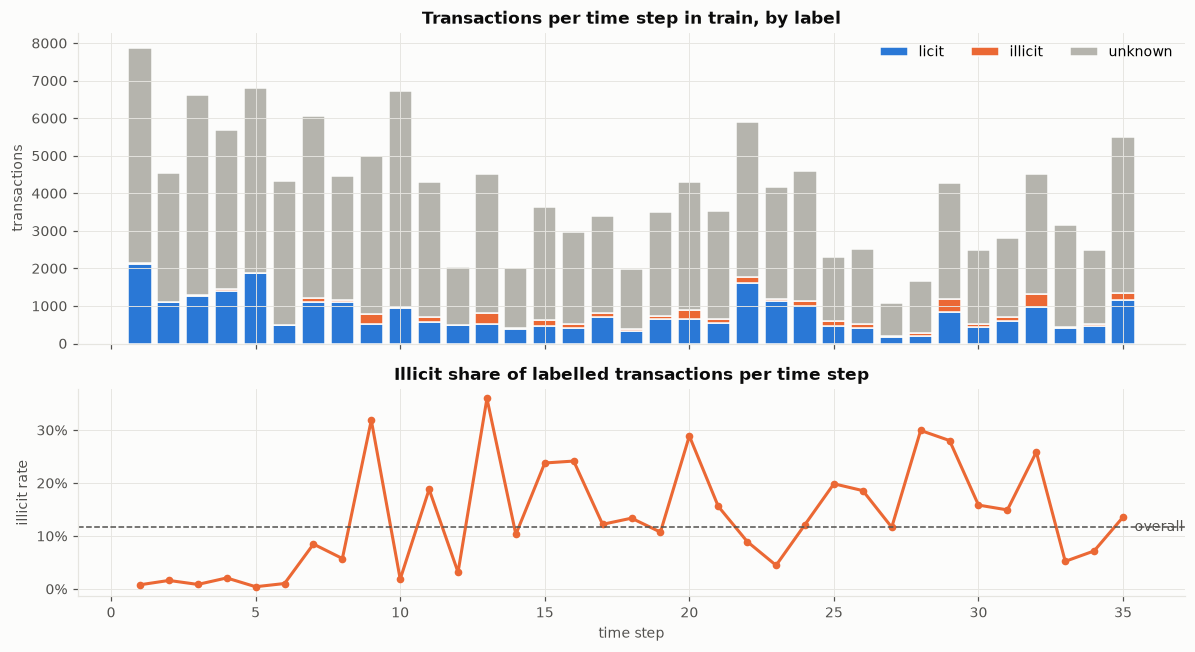

time_step,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
label_name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
licit,"2,130.0000","1,099.0000","1,268.0000","1,410.0000","1,874.0000",480.0000,"1,101.0000","1,098.0000",530.0000,954.0000,565.0000,490.0000,518.0000,374.0000,471.0000,402.0000,712.0000,337.0000,665.0000,640.0000,541.0000,"1,605.0000","1,134.0000",989.0000,476.0000,421.0000,182.0000,199.0000,845.0000,441.0000,604.0000,981.0000,418.0000,478.0000,"1,159.0000"
illicit,17.0000,18.0000,11.0000,30.0000,8.0000,5.0000,102.0000,67.0000,248.0000,18.0000,131.0000,16.0000,291.0000,43.0000,147.0000,128.0000,99.0000,52.0000,80.0000,260.0000,100.0000,158.0000,53.0000,137.0000,118.0000,96.0000,24.0000,85.0000,329.0000,83.0000,106.0000,342.0000,23.0000,37.0000,182.0000
unknown,"5,733.0000","3,427.0000","5,342.0000","4,253.0000","4,921.0000","3,843.0000","4,845.0000","3,292.0000","4,218.0000","5,755.0000","3,600.0000","1,541.0000","3,719.0000","1,605.0000","3,021.0000","2,445.0000","2,574.0000","1,587.0000","2,761.0000","3,391.0000","2,896.0000","4,131.0000","2,978.0000","3,466.0000","1,720.0000","2,006.0000",883.0000,"1,369.0000","3,101.0000","1,959.0000","2,106.0000","3,202.0000","2,710.0000","1,971.0000","4,166.0000"
illicit_rate,0.0079,0.0161,0.0086,0.0208,0.0043,0.0103,0.0848,0.0575,0.3188,0.0185,0.1882,0.0316,0.3597,0.1031,0.2379,0.2415,0.1221,0.1337,0.1074,0.2889,0.1560,0.0896,0.0447,0.1217,0.1987,0.1857,0.1165,0.2993,0.2802,0.1584,0.1493,0.2585,0.0522,0.0718,0.1357


In [5]:
per_step = train.pivot_table(index="time_step", columns="label_name", values="txId", aggfunc="count").fillna(0)
per_step = per_step[["licit", "illicit", "unknown"]].astype(int)
per_step["illicit_rate"] = per_step["illicit"] / (per_step["licit"] + per_step["illicit"])

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax = axes[0]
bottom = np.zeros(len(per_step))
for col, colr in [("licit", LICIT), ("illicit", ILLICIT), ("unknown", UNKNOWN)]:
    ax.bar(per_step.index, per_step[col], bottom=bottom, color=colr, label=col,
           width=0.8, edgecolor="#fcfcfb", linewidth=1)
    bottom += per_step[col].to_numpy()
ax.set_title("Transactions per time step in train, by label")
ax.set_ylabel("transactions")
ax.legend(ncol=3, loc="upper right")

ax = axes[1]
ax.plot(per_step.index, per_step["illicit_rate"], color=ILLICIT, lw=2, marker="o", ms=4)
ax.axhline(labelled.label.mean(), color=MUTED, lw=1, ls="--")
ax.text(per_step.index.max() + 0.4, labelled.label.mean(), "overall", color=MUTED, va="center")
ax.set_title("Illicit share of labelled transactions per time step")
ax.set_ylabel("illicit rate")
ax.set_xlabel("time step")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

per_step.T

> **Conclusion.** The illicit share swings from under 1% to 36% between time steps. Steps 1 to 6 contain almost no illicit cases.
>
> The label mix is not stable over time, so validation must use forward-chaining time splits, not random folds.

## 1.3 Train vs test coverage

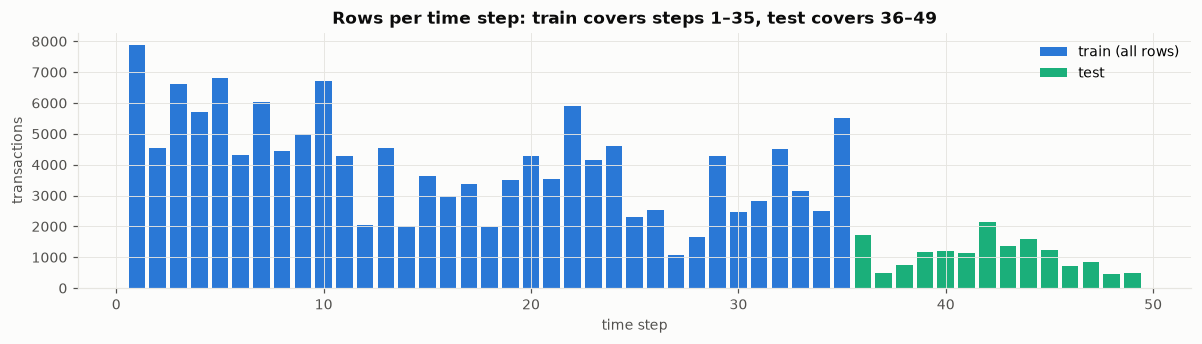

Train time steps: 1 to 35
Test time steps:  36 to 49
Labelled train rows: 31235 | test rows: 15329


In [6]:
cov = pd.concat([
    train.groupby("time_step").size().rename("train"),
    test.groupby("time_step").size().rename("test"),
], axis=1).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(cov.index, cov["train"], color=TRAIN, label="train (all rows)", width=0.8)
ax.bar(cov.index, cov["test"], color=TEST, label="test", width=0.8)
ax.set_title("Rows per time step: train covers steps 1–35, test covers 36–49")
ax.set_xlabel("time step"); ax.set_ylabel("transactions"); ax.legend()
plt.tight_layout(); plt.show()

print("Train time steps:", train.time_step.min(), "to", train.time_step.max())
print("Test time steps: ", test.time_step.min(), "to", test.time_step.max())
print("Labelled train rows:", len(labelled), "| test rows:", len(test))

> **Conclusion.** Train covers steps 1 to 35 and test covers 36 to 49, with no overlap. 

### 1.3.1 Feature drift between labelled train and test

In [7]:
# Two-sample Kolmogorov–Smirnov statistic per feature: 0 means identical distributions, 1 means fully separated.
late = labelled[labelled.time_step >= 25]
drift = pd.DataFrame({
    "ks_all_labelled_vs_test": [ks_2samp(labelled[f], test[f]).statistic for f in FEATS],
    "ks_steps25to35_vs_test": [ks_2samp(late[f], test[f]).statistic for f in FEATS],
}, index=FEATS).sort_values("ks_all_labelled_vs_test", ascending=False)

print(drift.describe().T[["mean", "50%", "max"]])
print("\nFeatures with KS > 0.2 (all labelled vs test):", int((drift.ks_all_labelled_vs_test > 0.2).sum()))
drift.head(15)

                          mean    50%    max
ks_all_labelled_vs_test 0.1698 0.1143 0.9954
ks_steps25to35_vs_test  0.1177 0.0704 0.9954

Features with KS > 0.2 (all labelled vs test): 23


,ks_all_labelled_vs_test,ks_steps25to35_vs_test
feat_101,0.9954,0.9954
feat_136,0.9944,0.9872
feat_103,0.9943,0.9943
feat_100,0.9921,0.9921
feat_139,0.9575,0.8751
feat_137,0.9227,0.8279
feat_2,0.6303,0.4864
feat_106,0.5676,0.3475
feat_109,0.5498,0.3515
feat_107,0.4912,0.3260


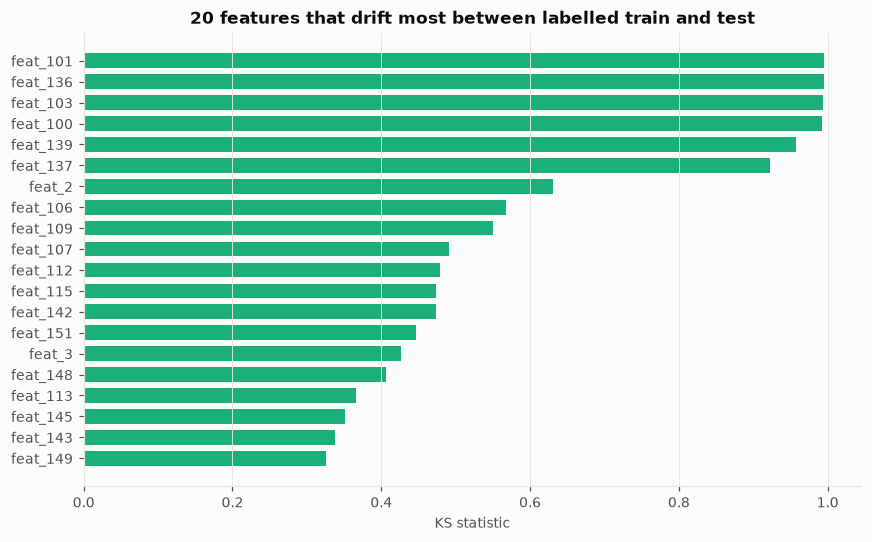

In [8]:
top = drift.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["ks_all_labelled_vs_test"], color=TEST, height=0.7)
ax.set_title("20 features that drift most between labelled train and test")
ax.set_xlabel("KS statistic")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

> **Conclusion.** Most features drift only mildly, with a median KS statistic of 0.11, or 0.07 against the latest train steps. 23 features exceed 0.2. Four features, feat_100, feat_101, feat_103 and feat_136, almost perfectly separate train from test with KS around 0.99.

## 1.4 Feature profile

In [9]:
X_all = train[FEATS]
profile = pd.DataFrame({
    "mean": X_all.mean(), "std": X_all.std(), "min": X_all.min(), "max": X_all.max(),
    "n_unique": X_all.nunique(),
    "pct_mode": X_all.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
})
profile["skew"] = X_all.skew()

near_const = profile[(profile.n_unique <= 1) | (profile.pct_mode >= 0.99)]
print(f"Near-constant features (one value covers ≥99% of rows): {len(near_const)}")
print(f"Features with |skew| > 10: {int((profile["skew"].abs() > 10).sum())}")
print(f"Median unique values per feature: {int(profile.n_unique.median()):,}")
profile.sort_values("pct_mode", ascending=False).head(15)

Near-constant features (one value covers ≥99% of rows): 1
Features with |skew| > 10: 68
Median unique values per feature: 9,820


,mean,std,min,max,n_unique,pct_mode,skew
feat_15,-0.0008,1.1230,-0.0133,119.4776,26,0.9993,92.9140
feat_70,0.0022,1.1036,-0.0170,152.1888,1742,0.9730,77.7195
feat_39,0.0036,1.1092,-6.9960,6.9990,921,0.9648,0.1909
feat_38,0.0039,1.1088,-6.9966,6.9995,1140,0.9648,0.1907
feat_36,-0.0094,0.9397,-0.0230,289.2044,2542,0.9643,230.9830
feat_7,0.0065,0.9560,-0.0616,113.4409,102,0.9470,53.4794
feat_129,0.0027,1.0227,-3.8718,3.8767,4746,0.8743,0.0359
feat_128,0.0026,1.0224,-3.8722,3.8785,6929,0.8742,0.0384
feat_51,-0.0048,1.0325,-3.7454,3.8301,4412,0.8736,-0.3002
feat_116,0.0022,0.9766,-3.6758,3.6670,5127,0.8731,-0.0002


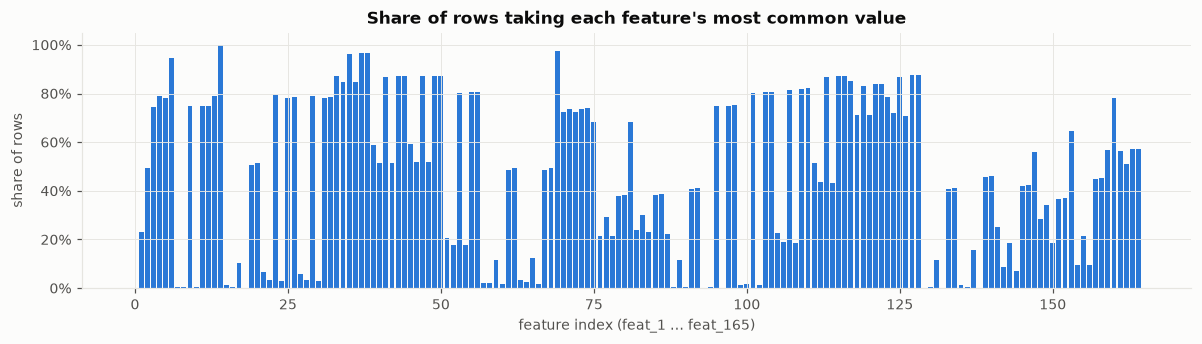

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(range(len(FEATS)), profile["pct_mode"], color=LICIT, width=0.8)
ax.set_title("Share of rows taking each feature's most common value")
ax.set_xlabel("feature index (feat_1 … feat_165)"); ax.set_ylabel("share of rows")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

> **Conclusion.** Only feat_15 is near-constant, with one value covering over 99% of rows. 68 features are heavily skewed, with absolute skew above 10.
>
> Decision: Dropped feat_15.

### 1.4.1 Redundancy between features

In [11]:
corr = X_all.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
for t in (0.90, 0.95, 0.98, 0.999):
    print(f"Feature pairs with |r| > {t}: {int((pairs > t).sum())}")
redundant = sorted({j for (i, j), v in pairs.items() if v > 0.98})
print(f"Features droppable at |r| > 0.98 (keep first of each pair): {len(redundant)}")
pairs.head(10).to_frame("|r|")

Feature pairs with |r| > 0.9: 147
Feature pairs with |r| > 0.95: 103
Feature pairs with |r| > 0.98: 73
Feature pairs with |r| > 0.999: 12
Features droppable at |r| > 0.98 (keep first of each pair): 53


,,|r|
feat_24,feat_30,1.0000
feat_59,feat_65,1.0000
feat_23,feat_29,1.0000
feat_60,feat_66,1.0000
feat_61,feat_67,1.0000
feat_25,feat_31,1.0000
feat_22,feat_28,1.0000
feat_58,feat_64,1.0000
feat_26,feat_32,0.9995
feat_27,feat_33,0.9995


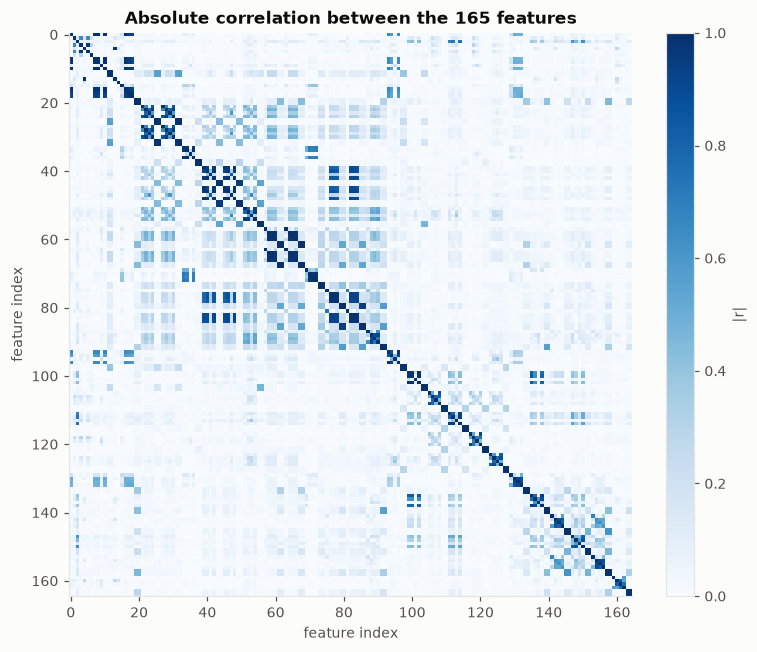

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_title("Absolute correlation between the 165 features")
ax.set_xlabel("feature index"); ax.set_ylabel("feature index"); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, label="|r|")
plt.tight_layout(); plt.show()

> **Conclusion.** 73 feature pairs have absolute correlation above 0.98, and 12 are near-identical. Removing one feature from each pair would cut 53 features. The heatmap shows blocks of related features.
>
> Decision: Prune at 0.98 before computing neighbour aggregates, which multiplies feature count, and before the linear baseline. Pruning also stops tree importance from being split across copies of the same signal, which makes importance-based selection more reliable.

### 1.4.2 How well each feature separates illicit from licit on its own

Best single-feature AUC: 0.857 (feat_53)
Features with single-feature AUC ≥ 0.70: 43


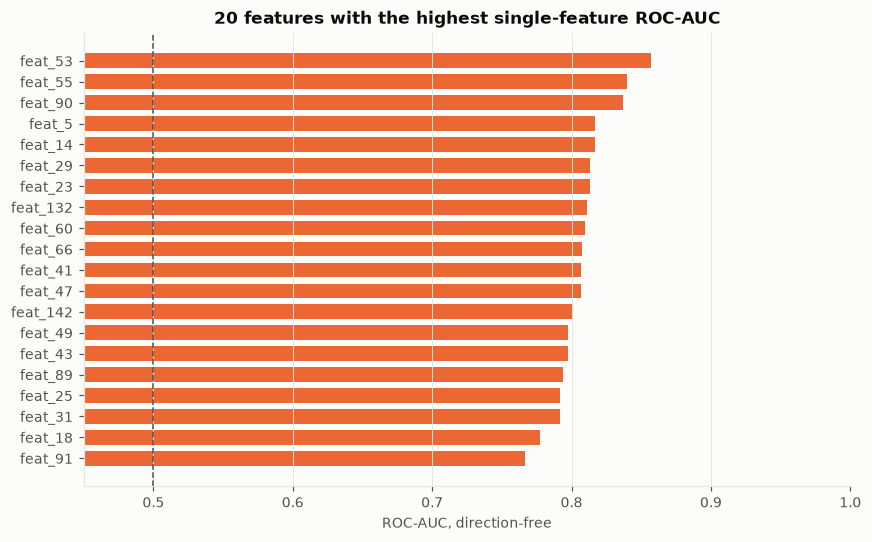

In [13]:
# Univariate ROC-AUC on labelled train. Values far from 0.5 in either direction mean the feature ranks well alone.
uni = pd.Series({f: roc_auc_score(labelled.label, labelled[f]) for f in FEATS})
uni_sep = (uni - 0.5).abs().add(0.5).sort_values(ascending=False)
print(f"Best single-feature AUC: {uni_sep.iloc[0]:.3f} ({uni_sep.index[0]})")
print(f"Features with single-feature AUC ≥ 0.70: {int((uni_sep >= 0.70).sum())}")

top = uni_sep.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=ILLICIT, height=0.7)
ax.axvline(0.5, color=MUTED, lw=1, ls="--")
ax.set_xlim(0.45, 1.0)
ax.set_title("20 features with the highest single-feature ROC-AUC")
ax.set_xlabel("ROC-AUC, direction-free"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

> **Conclusion.** The best single feature reaches ROC-AUC 0.86 on its own, and 43 features reach 0.70. The signal is strong but spread across many features.
>
> Models that combine many moderate signals, such as gradient-boosted trees and random forests, suit this data. 

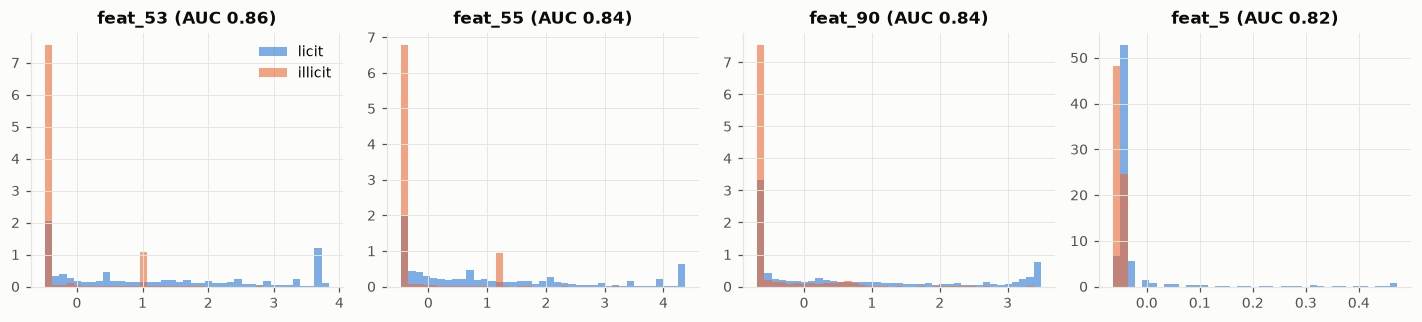

In [14]:
# Distributions of the four most predictive features, licit vs illicit, clipped to the 1st–99th percentile.
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, f in zip(axes, uni_sep.index[:4]):
    lo, hi = labelled[f].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi, 40)
    for lab, colr, name in [(0, LICIT, "licit"), (1, ILLICIT, "illicit")]:
        ax.hist(labelled.loc[labelled.label == lab, f].clip(lo, hi), bins=bins,
                density=True, alpha=0.6, color=colr, label=name)
    ax.set_title(f"{f} (AUC {uni_sep[f]:.2f})")
axes[0].legend()
plt.tight_layout(); plt.show()

> **Conclusion.** For the top features, most illicit transactions pile up at the feature's lowest value, while licit transactions spread across the whole range. Many licit transactions also sit at that low value, so the classes still overlap.
>
> A low value raises risk but does not mean illicit. This supports tree models that combine several such cut-offs.

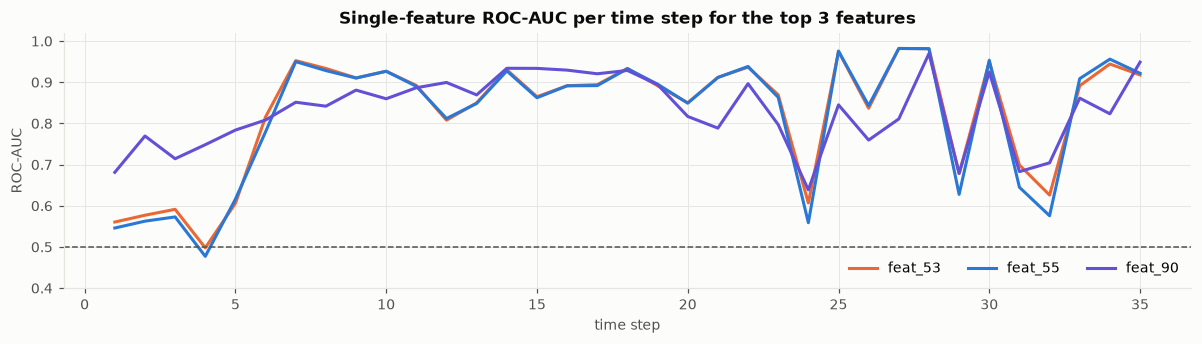

,feat_53,feat_55,feat_90
mean,0.8282,0.8205,0.8310
min,0.4979,0.4772,0.6388
max,0.9821,0.9821,0.9696


In [15]:
# Does a feature's predictive power hold up over time? Single-feature AUC per time step for the top 3 features,
# oriented so that 1.0 always means a perfect ranking in the direction found on all labelled data.
rows = []
for t, g in labelled.groupby("time_step"):
    if g.label.nunique() == 2:
        rows.append({"time_step": t, **{f: roc_auc_score(g.label, g[f] if uni[f] >= 0.5 else -g[f]) for f in uni_sep.index[:3]}})
stab = pd.DataFrame(rows).set_index("time_step")
fig, ax = plt.subplots(figsize=(11, 3.2))
for f, colr in zip(stab.columns, [ILLICIT, LICIT, "#6250d6"]):
    ax.plot(stab.index, stab[f], lw=2, color=colr, label=f)
ax.axhline(0.5, color=MUTED, lw=1, ls="--")
ax.set_title("Single-feature ROC-AUC per time step for the top 3 features")
ax.set_ylim(0.4, 1.02)
ax.set_xlabel("time step"); ax.set_ylabel("ROC-AUC"); ax.legend(ncol=3)
plt.tight_layout(); plt.show()
stab.describe().loc[["mean", "min", "max"]]

> **Conclusion.** The top features point the same way in every step, but their strength varies. They reach 0.85 to 0.98 in most steps, fall to about chance in steps 1 to 5, and dip to 0.56 to 0.70 in steps 24, 29, 31 and 32.
>
> Relying on a few strong features is fragile under drift. Per-step AUC will be reported during validation to expose such weak periods.

## 1.5 Transaction graph

In [16]:
G = nx.from_pandas_edgelist(edges, "txId1", "txId2", create_using=nx.DiGraph)
train_ids, test_ids = set(train.txId), set(test.txId)
known = train_ids | test_ids
graph_nodes = set(G.nodes)

print(f"Edges: {G.number_of_edges():,} ")
print(f"Nodes in edge list: {G.number_of_nodes():,}")
print(f"Nodes in edge list but missing from both files: {len(graph_nodes - known):,}")
print(f"Train nodes with no edges: {len(train_ids - graph_nodes):,} ")
print(f"Test nodes with no edges: {len(test_ids - graph_nodes):,}")

Edges: 234,355 
Nodes in edge list: 203,769
Nodes in edge list but missing from both files: 46,668
Train nodes with no edges: 0 
Test nodes with no edges: 0


> **Conclusion.** The edge list contains 203,769 nodes and 234,355 edges. 46,668 nodes appear in the edge list but in neither file, so their features and labels are unknown. Every train and test node has at least one edge.

In [17]:
# Where do edges go? Classify each endpoint as train, test or missing from both files.
def side(x):
    return np.where(x.isin(train_ids), "train", np.where(x.isin(test_ids), "test", "missing"))
edge_mix = pd.crosstab(pd.Series(side(edges.txId1), name="source"), pd.Series(side(edges.txId2), name="target"))
print("Edges by endpoint group:")
edge_mix

Edges by endpoint group:


target,missing,test,train
source,,,
missing,34192,18206,0
test,6039,12724,0
train,0,0,163194


> **Conclusion.** No edge connects a train node to a test node. Test nodes link only to other test nodes or to transactions missing from both files. Known training labels cannot spread to test nodes through the graph. 

In [18]:
indeg, outdeg = dict(G.in_degree()), dict(G.out_degree())
nodes = pd.DataFrame({"txId": list(known)})
nodes["split"] = np.where(nodes.txId.isin(train_ids), "train", "test")
nodes["in_degree"] = nodes.txId.map(indeg).fillna(0).astype(int)
nodes["out_degree"] = nodes.txId.map(outdeg).fillna(0).astype(int)
nodes["degree"] = nodes.in_degree + nodes.out_degree
# Neighbours that actually have a row in train.csv or test.csv
und = G.to_undirected(as_view=True)
nodes["visible_neighbours"] = [sum(n in known for n in und[t]) if t in und else 0 for t in nodes.txId]
nodes["visible_share"] = nodes.visible_neighbours / nodes.degree.replace(0, np.nan)

nodes.groupby("split")[["in_degree", "out_degree", "degree", "visible_neighbours", "visible_share"]].describe().T

split                           test        train
in_degree          count 15,329.0000 141,772.0000
                   mean       2.0177       1.1511
                   std        8.6463       3.5682
                   min        0.0000       0.0000
                   25%        0.0000       0.0000
                   50%        1.0000       1.0000
                   75%        1.0000       1.0000
                   max      241.0000     284.0000
out_degree         count 15,329.0000 141,772.0000
                   mean       1.2240       1.1511
                   std        1.7862       1.9609
                   min        0.0000       0.0000
                   25%        1.0000       1.0000
                   50%        1.0000       1.0000
                   75%        1.0000       1.0000
                   max       99.0000     472.0000
degree             count 15,329.0000 141,772.0000
                   mean       3.2418       2.3022
                   std        8.8702       4.0451
                   min        1.0000       1.0000
                   25%        1.0000       1.0000
                   50%        2.0000       2.0000
                   75%        2.0000       2.0000
                   max      241.0000     473.0000
visible_neighbours count 15,329.0000 141,772.0000
                   mean       1.6601       2.3022
                   std        3.2022       4.0451
                   min        0.0000       1.0000
                   25%        0.0000       1.0000
                   50%        1.0000       2.0000
                   75%        2.0000       2.0000
                   max       95.0000     473.0000
visible_share      count 15,329.0000 141,772.0000
                   mean       0.6090       1.0000
                   std        0.4196       0.0000
                   min        0.0000       1.0000
                   25%        0.0000       1.0000
                   50%        0.6667       1.0000
                   75%        1.0000       1.0000
                   max        1.0000       1.0000

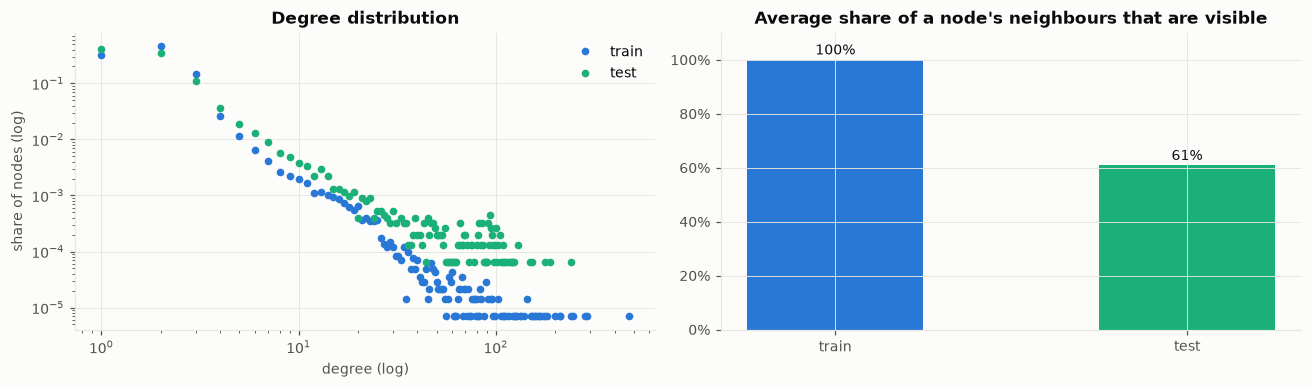

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
for s, colr in [("train", TRAIN), ("test", TEST)]:
    d = nodes.loc[nodes.split == s, "degree"]
    vc = d.value_counts(normalize=True).sort_index()
    ax.loglog(vc.index, vc.values, marker="o", ms=4, lw=0, color=colr, label=s)
ax.set_title("Degree distribution")
ax.set_xlabel("degree (log)"); ax.set_ylabel("share of nodes (log)"); ax.legend()

ax = axes[1]
share = nodes.groupby("split")["visible_share"].mean().reindex(["train", "test"])
ax.bar(share.index, share.values, color=[TEST if i == "test" else TRAIN for i in share.index], width=0.5)
for i, v in enumerate(share.values):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center", color=INK)
ax.set_ylim(0, 1.1)
ax.set_title("Average share of a node's neighbours that are visible")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

> **Conclusion.** Degree distribution is long-tailed. Test nodes have higher average degree, 3.2 versus 2.3, but see only 1.7 neighbours on average versus 2.3 in train. A typical test node sees 61% of its neighbours, while train nodes see all of them.
>
> Decision: Build neighbour aggregates only from neighbours that are rows being scored, labelled training rows for train and test rows for test, the same way for both, and add the visible-neighbour count as a feature.

In [20]:
# Weakly connected components: how fragmented is the graph?
comps = list(nx.weakly_connected_components(G))
sizes = pd.Series([len(c) for c in comps])
print(f"Weakly connected components: {len(comps):,}")
print(f"Largest component: {sizes.max():,} nodes | median size: {int(sizes.median())}")
print(sizes.describe().to_string())

Weakly connected components: 49
Largest component: 7,880 nodes | median size: 4291
count      49.0000
mean    4,158.5510
std     1,592.4706
min     1,089.0000
25%     2,891.0000
50%     4,291.0000
75%     5,121.0000
max     7,880.0000


> **Conclusion.** There are 49 weakly connected components, one per time step, ranging from 1,089 to 7,880 nodes.

In [21]:
# Degree by class: do illicit transactions connect differently from licit ones?
lab_nodes = nodes.merge(labelled[["txId", "label"]], on="txId")
lab_nodes.groupby("label")[["in_degree", "out_degree", "degree"]].agg(["mean", "median", "max"]).rename(index={0: "licit", 1: "illicit"})

in_degree             out_degree             degree            
             mean median  max       mean median  max   mean median  max
label                                                                  
licit      1.8304 1.0000  284     1.1484 1.0000  472 2.9788 2.0000  473
illicit    1.2544 1.0000  173     0.7547 1.0000    2 2.0091 1.0000  173

> **Conclusion.** Illicit transactions have lower degree than licit ones on average. Illicit out-degree never exceeds 2, while licit out-degree reaches 472.
>
> Decision: Add in-degree and out-degree as features.

### 1.5.1 Homophily test

Let *x* be the share of licit nodes and *y* the share of illicit nodes. If labels were placed at random, the expected share of edges joining a licit and an illicit node would be 2xy. The network is homophilic if the observed share *r* is well below 2xy.

In [22]:
lab_map = labelled.set_index("txId")["label"]
le = edges[edges.txId1.isin(lab_map.index) & edges.txId2.isin(lab_map.index)].copy()
le["l1"], le["l2"] = lab_map.loc[le.txId1].to_numpy(), lab_map.loc[le.txId2].to_numpy()

y = labelled.label.mean(); x = 1 - y
r = (le.l1 != le.l2).mean()
homophily = pd.Series({
    "labelled-labelled edges": len(le),
    "licit–licit edges": int(((le.l1 == 0) & (le.l2 == 0)).sum()),
    "illicit–illicit edges": int(((le.l1 == 1) & (le.l2 == 1)).sum()),
    "cross-label edges": int((le.l1 != le.l2).sum()),
    "expected cross share 2xy": round(2 * x * y, 4),
    "observed cross share r": round(r, 4),
})
print(homophily.to_string())
print("\nHomophilic:", r < 2 * x * y)

labelled-labelled edges    23,900.0000
licit–licit edges          21,772.0000
illicit–illicit edges         857.0000
cross-label edges           1,271.0000
expected cross share 2xy        0.2061
observed cross share r          0.0532

Homophilic: True


> **Conclusion.** The observed share of edges joining a licit and an illicit node is 0.053 < 0.206 expected by chance. The network is strongly homophilic.

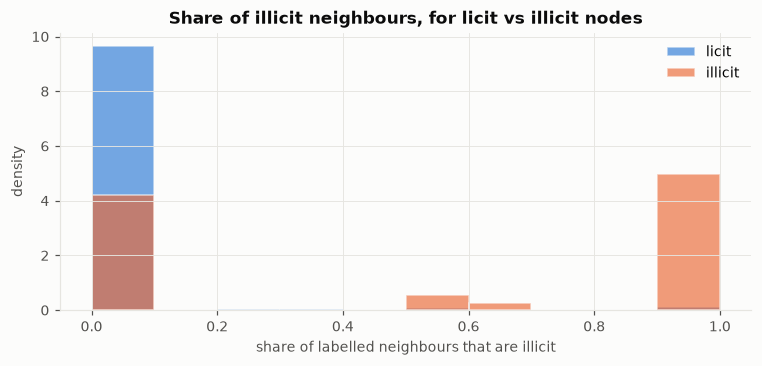

label
licit     0.0217
illicit   0.5424
Name: illicit_neighbour_share, dtype: float64
Labelled nodes with at least one labelled neighbour: 24,436 of 31,235


In [23]:
# Share of a labelled node's labelled neighbours that are illicit.
und_l = pd.concat([le.rename(columns={"txId1": "a", "txId2": "b", "l2": "nb"})[["a", "nb"]],
                   le.rename(columns={"txId2": "a", "txId1": "b", "l1": "nb"})[["a", "nb"]]])
nb_rate = und_l.groupby("a")["nb"].mean().rename("illicit_neighbour_share")
gba = lab_nodes.set_index("txId").join(nb_rate, how="inner")

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, 1, 11)
for lab, colr, name in [(0, LICIT, "licit"), (1, ILLICIT, "illicit")]:
    ax.hist(gba.loc[gba.label == lab, "illicit_neighbour_share"], bins=bins, density=True,
            alpha=0.65, color=colr, label=name, edgecolor="#fcfcfb")
ax.set_title("Share of illicit neighbours, for licit vs illicit nodes")
ax.set_xlabel("share of labelled neighbours that are illicit"); ax.set_ylabel("density"); ax.legend()
plt.tight_layout(); plt.show()
print(gba.groupby("label")["illicit_neighbour_share"].mean().rename(index={0: "licit", 1: "illicit"}))
print(f"Labelled nodes with at least one labelled neighbour: {len(gba):,} of {len(lab_nodes):,}")

> **Conclusion.** On average, 54% of an illicit node's labelled neighbours are illicit, against 2% for a licit node. 78% of labelled nodes have at least one labelled neighbour.
>
> Decision: Add neighbour-score feature, and the 22% of nodes without labelled neighbours need a missing-value indicator instead of a default score of zero.

# 2. Data Preprocessing and Feature Engineering
| Step | What it does | Rationale|
|---|---|---|
| 2.1 | Separate labelled training rows and set up time-based validation folds | 78% of train is unlabelled, and the label mix drifts over time |
| 2.2 | Drop near-constant feature and prune near-duplicate features | feat_15 is near-constant; 73 feature pairs correlate above 0.98 |
| 2.3 | Build 3 versions of the 4 time-proxy features | They track time step almost perfectly and test values fall outside the training range |
| 2.4 | Add structural graph features from the full edge list | Degree differs by class, and the edge list is complete for test nodes |
| 2.5 | Average key features over visible neighbours | The graph is homophilic, but test nodes see only part of their neighbourhood |
| 2.6 | Define two-stage neighbour-score feature | No edge joins train and test, so labels cannot spread directly |
| 2.7 | Assemble the final feature matrices | Input for section 3 |

## 2.1 Labelled rows and validation folds

In [24]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

RANDOM_STATE = 42

# Only labelled rows train the classifier. Unlabelled rows stay in `train` for graph structure.
train_lab = train[train.label.notna()].copy()
train_lab["label"] = train_lab["label"].astype(int)
train_lab = train_lab.reset_index(drop=True)
test_df = test.copy().reset_index(drop=True)

# Forward-chaining folds: train on all steps up to a cut-off, validate on the next five steps.
FOLDS = [(20, 25), (25, 30), (30, 35)]
fold_table = pd.DataFrame([{
    "fold": k + 1, "train steps": f"1–{cut}", "validation steps": f"{cut + 1}–{end}",
    "train rows": int((train_lab.time_step <= cut).sum()),
    "validation rows": int(train_lab.time_step.between(cut + 1, end).sum()),
    "validation illicit rate": train_lab.loc[train_lab.time_step.between(cut + 1, end), "label"].mean(),
} for k, (cut, end) in enumerate(FOLDS)])

# Feature-selection statistics use only steps 1–20, the training part of the first fold,
# so no fold's validation labels influence which features are chosen.
SEL = train_lab[train_lab.time_step <= 20]
print(f"Labelled training rows: {len(train_lab):,} | test rows: {len(test_df):,}")
print(f"Rows used for feature-selection statistics (steps 1–20): {len(SEL):,}")
fold_table

Labelled training rows: 31,235 | test rows: 15,329
Rows used for feature-selection statistics (steps 1–20): 18,889


,fold,train steps,validation steps,train rows,validation rows,validation illicit rate
0,1,1–20,21–25,18889,5311,0.1066
1,2,1–25,26–30,24200,2705,0.2281
2,3,1–30,31–35,26905,4330,0.1594


> **Conclusion.** There are 31,235 labelled training rows. The three folds validate on 5,311, 2,705 and 4,330 rows, with illicit rates from 11% to 23%. Feature-selection statistics use only steps 1–20 (18,889 rows), which means no validation label shapes the choice of features.

## 2.2 Feature pruning

In [25]:
CLOCK = ["feat_100", "feat_101", "feat_103", "feat_136"]       # time-proxy features, handled in 2.3
NEAR_CONST = profile.index[(profile.n_unique <= 1) | (profile.pct_mode >= 0.99)].tolist()

# Rank remaining features by single-feature ROC-AUC on steps 1–20 (direction-free).
cand = [f for f in FEATS if f not in CLOCK + NEAR_CONST]
sel_auc = pd.Series({f: abs(roc_auc_score(SEL.label, SEL[f]) - 0.5) + 0.5 for f in cand}).sort_values(ascending=False)

# Greedy pruning: walk features from strongest to weakest and keep one only if its absolute
# correlation with every feature already kept is at most 0.98. The stronger of each near-duplicate pair survives.
CORR_MAX = 0.98
corr_c = train[cand].corr().abs()
KEPT = []
for f in sel_auc.index:
    if all(corr_c.at[f, k] <= CORR_MAX for k in KEPT):
        KEPT.append(f)
PRUNED_OUT = sorted(set(cand) - set(KEPT), key=lambda f: int(f.split("_")[1]))

print(f"Near-constant features dropped: {NEAR_CONST}")
print(f"Time-proxy features set aside for 2.3: {CLOCK}")
print(f"Correlation-pruned features: {len(PRUNED_OUT)}")
print(f"Features kept: {len(KEPT)} of {len(FEATS)}")
print(f"Max abs correlation among kept features: {corr_c.loc[KEPT, KEPT].where(~np.eye(len(KEPT), dtype=bool)).max().max():.3f}")

Near-constant features dropped: ['feat_15']
Time-proxy features set aside for 2.3: ['feat_100', 'feat_101', 'feat_103', 'feat_136']
Correlation-pruned features: 50
Features kept: 110 of 165
Max abs correlation among kept features: 0.979


> **Conclusion.** feat_15 was dropped as near-constant. Correlation pruning removed 50 more features, leaving 110 of 165, and no kept pair correlates above 0.979. The four time-proxy features were set aside for 2.3.
>
> The model now sees one copy of each signal, which keeps feature importance readable and halves the cost of neighbour aggregation.

## 2.3 Time-proxy features

Section 1 showed 4 features that rise with time step almost perfectly. 3 versions are built:

- **raw**: the features as given.
- **dropped**: the features removed.
- **detrended**: each value minus the median of its own time step. This removes the time trend and keeps only how a transaction differs from others in the same step. The median is taken over the rows we score: labelled rows in train, and all rows in test. 

In [26]:
def detrend_clock(df, ref_mask):
    """Subtract each time step's median (over reference rows) from the time-proxy features."""
    med = df.loc[ref_mask].groupby("time_step")[CLOCK].median()
    out = df[CLOCK] - med.reindex(df["time_step"]).to_numpy()
    return out.add_suffix("_dt")

clock_dt_train = detrend_clock(train_lab, np.ones(len(train_lab), dtype=bool))
clock_dt_test = detrend_clock(test_df, np.ones(len(test_df), dtype=bool))
CLOCK_DT = clock_dt_train.columns.tolist()

check = pd.DataFrame({
    "KS raw: train vs test": [ks_2samp(train_lab[f], test_df[f]).statistic for f in CLOCK],
    "KS detrended: train vs test": [ks_2samp(clock_dt_train[f + "_dt"], clock_dt_test[f + "_dt"]).statistic for f in CLOCK],
    "Spearman raw vs time step": [train_lab[[f, "time_step"]].corr("spearman").iloc[0, 1] for f in CLOCK],
    "Spearman detrended vs time step": [pd.concat([clock_dt_train[f + "_dt"], train_lab.time_step], axis=1).corr("spearman").iloc[0, 1] for f in CLOCK],
    "AUC raw (steps 1–20)": [abs(roc_auc_score(SEL.label, SEL[f]) - 0.5) + 0.5 for f in CLOCK],
    "AUC detrended (steps 1–20)": [abs(roc_auc_score(SEL.label, clock_dt_train.loc[SEL.index, f + "_dt"]) - 0.5) + 0.5 for f in CLOCK],
}, index=CLOCK)
check

,KS raw: train vs test,KS detrended: train vs test,Spearman raw vs time step,Spearman detrended vs time step,AUC raw (steps 1–20),AUC detrended (steps 1–20)
feat_100,0.9921,0.0815,0.9828,-0.0467,0.7643,0.5816
feat_101,0.9954,0.0462,0.9977,-0.0178,0.7584,0.5506
feat_103,0.9943,0.0797,0.9897,-0.0551,0.7628,0.5739
feat_136,0.9944,0.0718,0.9926,-0.0244,0.7644,0.5954


> **Conclusion.** Detrending works as intended. The train-versus-test KS statistic falls from about 0.99 to between 0.05 and 0.08, and correlation with time step falls from about 0.99 to near zero. Single-feature AUC also falls, from about 0.76 to between 0.55 and 0.60.
>
> The raw versions would let a model learn which periods were fraud-heavy, a pattern that cannot carry into test. 

## 2.4 Structural graph features

| Feature | Meaning | 
|---|---|
| `in_degree`, `out_degree`, `degree` | Degree centrality: No. of predecessor, successor and total linked transactions |
| `is_source`, `is_sink` | No incoming edges, or no outgoing edges |
| `pagerank_fwd` | PageRank following the direction of fund flow |
| `pagerank_bwd` | PageRank on the reversed graph, so importance flows back to where funds came from |
| `clustering` | Local clustering coefficient on the undirected graph |
| `avg_nb_degree` | Average degree of a transaction's neighbours |

These are computed using the full edge list, which includes the transactions missing from both files.
PageRank is computed within each time step's graph and multiplied by that graph's size.

In [27]:
UG = G.to_undirected(as_view=False)
pr_fwd, pr_bwd = {}, {}
for comp in nx.weakly_connected_components(G):
    sub = G.subgraph(comp)
    n = len(comp)
    pr_fwd.update({k: v * n for k, v in nx.pagerank(sub, alpha=0.85).items()})
    pr_bwd.update({k: v * n for k, v in nx.pagerank(sub.reverse(copy=False), alpha=0.85).items()})
clust = nx.clustering(UG)
avg_nb_deg = nx.average_neighbor_degree(UG)

def structural_features(df):
    s = pd.DataFrame({"txId": df.txId})
    s["in_degree"] = s.txId.map(indeg).fillna(0)
    s["out_degree"] = s.txId.map(outdeg).fillna(0)
    s["degree"] = s.in_degree + s.out_degree
    s["is_source"] = (s.in_degree == 0).astype(int)
    s["is_sink"] = (s.out_degree == 0).astype(int)
    s["pagerank_fwd"] = s.txId.map(pr_fwd)
    s["pagerank_bwd"] = s.txId.map(pr_bwd)
    s["clustering"] = s.txId.map(clust)
    s["avg_nb_degree"] = s.txId.map(avg_nb_deg)
    return s.drop(columns="txId").reset_index(drop=True)

struct_train, struct_test = structural_features(train_lab), structural_features(test_df)
STRUCT = struct_train.columns.tolist()

sel_idx = SEL.index
struct_check = pd.DataFrame({
    "AUC (steps 1–20)": [abs(roc_auc_score(SEL.label, struct_train.loc[sel_idx, f]) - 0.5) + 0.5 for f in STRUCT],
    "mean, licit": [struct_train.loc[train_lab.label == 0, f].mean() for f in STRUCT],
    "mean, illicit": [struct_train.loc[train_lab.label == 1, f].mean() for f in STRUCT],
    "KS train vs test": [ks_2samp(struct_train[f], struct_test[f]).statistic for f in STRUCT],
}, index=STRUCT)
struct_check

,AUC (steps 1–20),"mean, licit","mean, illicit",KS train vs test
in_degree,0.5551,1.8304,1.2544,0.0623
out_degree,0.6144,1.1484,0.7547,0.0403
degree,0.6688,2.9788,2.0091,0.0281
is_source,0.5242,0.3179,0.2560,0.0451
is_sink,0.5475,0.2610,0.3068,0.0403
pagerank_fwd,0.5739,1.0793,0.8595,0.1255
pagerank_bwd,0.7217,0.7600,0.6063,0.1799
clustering,0.5153,0.0094,0.0002,0.0105
avg_nb_degree,0.6488,16.2447,13.1000,0.1684


> **Conclusion.** Illicit transactions have lower degree, lower PageRank and fewer well-connected neighbours. Total degree, backward PageRank and average neighbour degree are the strongest structural signals, with AUC 0.65 to 0.72. All structural features have low train-versus-test drift, with KS of 0.18 or less.
>
> Structural features are weaker alone than the strongest anonymised features, which reach about 0.86.

## 2.5 Neighbour aggregates over visible neighbours

For each transaction, the mean and maximum of key features are taken over its **visible** neighbours, along with how many neighbours are visible.

A neighbour counts as visible only if it is a row we score: a labelled train row for train transactions, or a test row for test transactions. The provided data supports treating these as the same kind of neighbour. Transactions missing from both files occur only in the test steps, at about 3,300 a step and 76% of each step's transactions, close to the 3,200 unlabelled training transactions a step and their 79% share. Below, this rule makes train and test visible-neighbour counts match closely, while counting every train neighbour would give train transactions far richer neighbourhoods than test transactions have.

Transactions with no visible neighbour get missing values. The gradient-boosting models used here handle missing values natively, so "no visible neighbour" is learned as its own case.

The features aggregated are the 15 strongest pruned features by single-feature AUC on steps 1–20.

In [28]:
NB_COLS = KEPT[:15]

def neighbour_aggregates(df, cols):
    """Mean and max of `cols` over neighbours that are also rows of `df` (the visible set: rows we score)."""
    ids = set(df.txId)
    e = edges[edges.txId1.isin(ids) & edges.txId2.isin(ids)]
    pairs = pd.concat([
        pd.DataFrame({"node": e.txId1.to_numpy(), "nb": e.txId2.to_numpy()}),
        pd.DataFrame({"node": e.txId2.to_numpy(), "nb": e.txId1.to_numpy()}),
    ])
    vals = df.set_index("txId")[cols]
    agg = pd.DataFrame(vals.loc[pairs.nb].to_numpy(), columns=cols)
    agg["node"] = pairs.node.to_numpy()
    g = agg.groupby("node")
    feats = pd.concat([g.size().rename("nb_visible"),
                       g.mean().add_prefix("nbmean_"), g.max().add_prefix("nbmax_")], axis=1)
    out = df[["txId"]].join(feats, on="txId").drop(columns="txId").reset_index(drop=True)
    out["nb_visible"] = out["nb_visible"].fillna(0)
    return out

nbagg_train, nbagg_test = neighbour_aggregates(train_lab, NB_COLS), neighbour_aggregates(test_df, NB_COLS)
NBAGG = nbagg_train.columns.tolist()

vis = pd.DataFrame({
    "train (labelled)": nbagg_train.nb_visible.describe(),
    "test": nbagg_test.nb_visible.describe(),
}).T[["mean", "50%", "75%", "max"]]
vis["share with no visible neighbour"] = [(nbagg_train.nb_visible == 0).mean(), (nbagg_test.nb_visible == 0).mean()]
print(f"Neighbour-aggregate features: {len(NBAGG)}")
print(f"KS of visible-neighbour count, train vs test: {ks_2samp(nbagg_train.nb_visible, nbagg_test.nb_visible).statistic:.3f}")
vis

Neighbour-aggregate features: 31
KS of visible-neighbour count, train vs test: 0.036


,mean,50%,75%,max,share with no visible neighbour
train (labelled),1.5303,1.0000,2.0000,453.0000,0.2177
test,1.6601,1.0000,2.0000,95.0000,0.2538


> **Conclusion.** Under the visible-neighbour definition, train and test look alike. The mean is 1.5 versus 1.7 neighbours, the share with no visible neighbour is 22% versus 25%, and the KS statistic is 0.04.

In [29]:
# For comparison: the same count if train transactions could see all their train neighbours, labelled or not.
all_ids = set(train.txId)
e_all = edges[edges.txId1.isin(all_ids) & edges.txId2.isin(all_ids)]
cnt_all = pd.concat([e_all.txId1, e_all.txId2]).value_counts()
naive = train_lab.txId.map(cnt_all).fillna(0)
print(f"Mean visible neighbours if unlabelled train rows counted: {naive.mean():.2f}")
print(f"KS vs test under that naive definition: {ks_2samp(naive, nbagg_test.nb_visible).statistic:.3f}")

top_nb = pd.Series({f: abs(roc_auc_score(SEL.label, nbagg_train.loc[sel_idx, f].fillna(-999)) - 0.5) + 0.5
                    for f in NBAGG}).sort_values(ascending=False)
print("\nStrongest neighbour features by single-feature AUC (steps 1–20; missing treated as its own value):")
print(top_nb.head(8).round(3).to_string())

Mean visible neighbours if unlabelled train rows counted: 2.87
KS vs test under that naive definition: 0.254

Strongest neighbour features by single-feature AUC (steps 1–20; missing treated as its own value):
nbmax_feat_89    0.8060
nbmax_feat_91    0.8060
nbmean_feat_89   0.8040
nbmean_feat_91   0.8040
nbmax_feat_90    0.8030
nbmean_feat_90   0.8010
nbmax_feat_55    0.7830
nbmean_feat_55   0.7800


> **Conclusion.** Counting unlabelled train neighbours too would raise the train mean to 2.9 and the KS statistic against test to 0.25. Neighbour aggregates reach single-feature AUC of up to 0.81.
>
> This confirms that the visible-only rule is necessary. Without it, train transactions would see roughly twice the neighbourhood test transactions see.

## 2.6 Two-stage neighbour score

Labels cannot travel from train to test through the graph, because no edge joins them. The workaround is collective inference in two stages:

1. A first-stage model, trained only on earlier steps, scores every transaction in the later steps.
2. For each transaction, the mean and maximum **score** of its visible neighbours become features for a second-stage model.

This is guilt-by-association, with predicted risk standing in for unknown labels. To avoid leakage, first-stage scores must always come from a model that never saw the rows being scored. The builder below is applied inside each validation fold in section 3. 

In [30]:
def neighbour_score_features(df, scores):
    """Mean and max of first-stage scores over visible neighbours (rows of `df`), plus a missing flag."""
    ids = set(df.txId)
    e = edges[edges.txId1.isin(ids) & edges.txId2.isin(ids)]
    pairs = pd.concat([
        pd.DataFrame({"node": e.txId1.to_numpy(), "nb": e.txId2.to_numpy()}),
        pd.DataFrame({"node": e.txId2.to_numpy(), "nb": e.txId1.to_numpy()}),
    ])
    pairs["s"] = pairs.nb.map(scores)
    g = pairs.dropna(subset=["s"]).groupby("node")["s"]
    out = df[["txId"]].join(pd.concat([g.mean().rename("nbscore_mean"), g.max().rename("nbscore_max")], axis=1), on="txId")
    out["nbscore_missing"] = out["nbscore_mean"].isna().astype(int)
    return out.drop(columns="txId").reset_index(drop=True)

def hgb():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                          class_weight="balanced", random_state=RANDOM_STATE)

## 2.7 Final feature set

The base set is the 110 pruned anonymised features from 2.2, with the four time-proxy features dropped (2.3). The engineered graph features from 2.4 to 2.6 are not part of the base set. They are kept as add-ons and retested with the tuned model in section 3.

In [31]:
# All candidate feature columns side by side: raw features, detrended time proxies (2.3), structural (2.4) and neighbour aggregates (2.5).
# Section 3 draws the base set and every add-on from these two frames.
FULL_TRAIN = pd.concat([train_lab[FEATS], clock_dt_train, struct_train, nbagg_train], axis=1)
FULL_TEST = pd.concat([test_df[FEATS], clock_dt_test, struct_test, nbagg_test], axis=1)

FINAL_FEATURES = list(KEPT)                       # 110 pruned anonymised features, time proxies dropped
X_train = FULL_TRAIN[FINAL_FEATURES].copy()
y_train = train_lab["label"].copy()
X_test = FULL_TEST[FINAL_FEATURES].copy()
groups_train = train_lab["time_step"].copy()     # used for time-based folds only, never as a feature

assert list(X_train.columns) == list(X_test.columns)
assert np.isfinite(X_train.select_dtypes("number").fillna(0).to_numpy()).all()
assert np.isfinite(X_test.select_dtypes("number").fillna(0).to_numpy()).all()

comp = pd.Series({
    "raw anonymised features": sum(f in FEATS for f in FINAL_FEATURES),
    "time-proxy features": sum(f in CLOCK + CLOCK_DT for f in FINAL_FEATURES),
    "structural graph features (add-on, 2.4)": sum(f in STRUCT for f in FINAL_FEATURES),
    "neighbour-aggregate features (add-on, 2.5)": sum(f in NBAGG for f in FINAL_FEATURES),
}, name="count in base set")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape} | illicit share in y_train: {y_train.mean():.2%}")
comp.to_frame()

X_train: (31235, 110) | X_test: (15329, 110) | illicit share in y_train: 11.67%


,count in base set
raw anonymised features,110
time-proxy features,0
"structural graph features (add-on, 2.4)",0
"neighbour-aggregate features (add-on, 2.5)",0


> **Conclusion.** The final matrices are X_train with 31,235 rows and X_test with 15,329 rows, each with the same 110 pruned anonymised features as the base set. Time step is kept separately for building folds and is never a model input.

# 3. Model Development and Validation

This section trains and validates models on the 110-feature base set from section 2.

| Step | What it does |
|---|---|
| 3.1 | Shared tools: metrics, fold loop, per-step scoring |
| 3.2 | Baselines: logistic regression, random forest and untuned LightGBM |
| 3.3 | Hyperparameter tuning of LightGBM with Optuna |
| 3.4 | Tuned model per fold and per time step, with an overfitting check |
| 3.5 | Ablations: seed noise, class weight, recency weighting, training window, and graph features with the tuned model |
| 3.6 | Fit on all training steps and test predictions |

All comparisons use the three forward-chaining folds from 2.1. Folds 2 and 3 score above 0.99 for most models, so results are always shown per fold, not only as a mean.

## 3.1 Shared tools

In [32]:
import time, os, pickle
import lightgbm as lgb
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler

optuna.logging.set_verbosity(optuna.logging.WARNING)
LGB_THREADS = 4
BASE_FEATURES = list(FINAL_FEATURES)     # 110 pruned features from section 2
TS = train_lab["time_step"].to_numpy()
Y = train_lab["label"].to_numpy()

def precision_at_top(y, p, frac=0.10):
    """Share of illicit transactions among the top `frac` highest-scored ones: what an investigator with limited capacity would see."""
    k = max(1, int(round(len(p) * frac)))
    return y[np.argsort(-p)[:k]].mean()

def score(y, p):
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p), "prec_top10": precision_at_top(y, p)}

def fold_masks(cut, end, min_step=1):
    return (TS <= cut) & (TS >= min_step), (TS > cut) & (TS <= end)

def run_cv(make_model, cols, name, min_step=1, sample_weight_fn=None, extra_fn=None, keep_preds=False):
    """Fit on each fold's training steps and score its validation steps.
    sample_weight_fn(time_steps) -> weights; extra_fn(tr_mask, va_mask) -> (extra_tr, extra_va) feature frames."""
    rows, preds = [], []
    for k, (cut, end) in enumerate(FOLDS):
        tr, va = fold_masks(cut, end, min_step)
        Xtr, Xva = FULL_TRAIN.loc[tr, cols].reset_index(drop=True), FULL_TRAIN.loc[va, cols].reset_index(drop=True)
        if extra_fn is not None:
            etr, eva = extra_fn(tr, va)
            Xtr, Xva = pd.concat([Xtr, etr], axis=1), pd.concat([Xva, eva], axis=1)
        w = sample_weight_fn(TS[tr]) if sample_weight_fn is not None else None
        m = make_model()
        m.fit(Xtr, Y[tr], sample_weight=w) if w is not None else m.fit(Xtr, Y[tr])
        p_va, p_tr = m.predict_proba(Xva)[:, 1], m.predict_proba(Xtr)[:, 1]
        rows.append({"model": name, "fold": k + 1, **score(Y[va], p_va), "train_roc_auc": roc_auc_score(Y[tr], p_tr)})
        if keep_preds:
            preds.append(pd.DataFrame({"fold": k + 1, "time_step": TS[va], "y": Y[va], "p": p_va}))
    out = pd.DataFrame(rows)
    return (out, pd.concat(preds)) if keep_preds else out

def per_step_auc(pred_df):
    return pred_df.groupby("time_step").apply(lambda g: roc_auc_score(g.y, g.p) if g.y.nunique() == 2 else np.nan)

def summarise(df):
    s = df.pivot_table(index="model", columns="fold", values="roc_auc", sort=False)
    s.columns = [f"fold {c} ROC-AUC" for c in s.columns]
    g = df.groupby("model", sort=False)
    s["mean ROC-AUC"], s["mean PR-AUC"], s["mean prec@top10%"] = g.roc_auc.mean(), g.pr_auc.mean(), g.prec_top10.mean()
    return s

# 2 slow steps (3.3 tuning, 3.5 ablations) save their results here and reload them on re-runs.
# Delete the folder to recompute everything from scratch.
CACHE_DIR = "artifacts"
os.makedirs(CACHE_DIR, exist_ok=True)

def cached(name, compute):
    path = f"{CACHE_DIR}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as fh:
            print(f"Loaded cached result: {path}")
            return pickle.load(fh)
    result = compute()
    with open(path, "wb") as fh:
        pickle.dump(result, fh)
    return result

print(f"Base features: {len(BASE_FEATURES)} | folds: {FOLDS}")

Base features: 110 | folds: [(20, 25), (25, 30), (30, 35)]


## 3.2 Baselines

- **Logistic regression** on quantile-transformed features, with balanced class weights. It shows how far a linear model gets, and the transform handles the heavy skew found in 1.4.
- **Random forest** with 500 trees and balanced class weights. It is a common, strong baseline for tabular fraud data.
- **LightGBM with default settings**, no class weighting. It is the starting point for tuning.

In [33]:
def make_lr():
    return make_pipeline(QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=RANDOM_STATE),
                         StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))

def make_rf():
    return RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=1,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)

def make_lgb_default(seed=RANDOM_STATE):
    return lgb.LGBMClassifier(random_state=seed, n_jobs=LGB_THREADS, verbose=-1)

t0 = time.time()
base_res = pd.concat([
    run_cv(make_lr, BASE_FEATURES, "Logistic regression"),
    run_cv(make_rf, BASE_FEATURES, "Random forest"),
    run_cv(make_lgb_default, BASE_FEATURES, "LightGBM, default"),
])
print(f"Baselines done in {time.time() - t0:.0f}s")
summarise(base_res).round(4)

Baselines done in 18s


,fold 1 ROC-AUC,fold 2 ROC-AUC,fold 3 ROC-AUC,mean ROC-AUC,mean PR-AUC,mean prec@top10%
model,,,,,,
Logistic regression,0.9259,0.9428,0.9624,0.9437,0.8339,0.8925
Random forest,0.8932,0.9939,0.9981,0.9617,0.9394,0.9490
"LightGBM, default",0.9549,0.9961,0.9979,0.9830,0.9511,0.9521


> **Conclusion.** Untuned LightGBM is the strongest baseline, with mean ROC-AUC 0.983. Random forest reaches 0.962 and logistic regression 0.944. Random forest matches LightGBM on folds 2 and 3 but falls to 0.893 on fold 1. Logistic regression is weakest on every fold, especially in PR-AUC, 0.83 against 0.95.
>
> The gap to logistic regression shows that the signal is nonlinear, which supports tree ensembles. LightGBM is chosen for tuning. Random forest stays as a candidate for ensembling in section 4, because its errors may differ from LightGBM's.

## 3.3 Hyperparameter tuning

Optuna's tree-structured Parzen estimator searches 50 LightGBM configurations. Each trial is scored by mean ROC-AUC over the three folds.

The number of trees is tuned directly instead of using early stopping. Early stopping would pick the stopping point on the validation fold, which would make validation scores optimistic.

Tuning uses neutral settings: no class weighting, no recency weighting and all training steps. Those choices are tested one at a time in 3.5, so each one's effect stays visible.

In [34]:
def lgb_from_params(params, seed=RANDOM_STATE, **overrides):
    p = dict(params); p.update(overrides)
    return lgb.LGBMClassifier(**p, subsample_freq=1, random_state=seed, n_jobs=LGB_THREADS, verbose=-1)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1500, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
        "max_depth": trial.suggest_categorical("max_depth", [-1, 4, 6, 8, 12]),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
    }
    res = run_cv(lambda: lgb_from_params(params), BASE_FEATURES, "trial")
    for k, v in enumerate(res.roc_auc):
        trial.set_user_attr(f"fold{k + 1}", v)
    return res.roc_auc.mean()

N_TRIALS = 50

def run_study():
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    st.enqueue_trial({"n_estimators": 100, "learning_rate": 0.1, "num_leaves": 31, "max_depth": -1,
                      "min_child_samples": 20, "subsample": 1.0, "colsample_bytree": 1.0,
                      "reg_lambda": 1e-3, "reg_alpha": 1e-3})   # trial 0 is close to LightGBM's defaults
    st.optimize(objective, n_trials=N_TRIALS)
    return st

t0 = time.time()
study = cached(f"optuna_study_{N_TRIALS}trials", run_study)
BEST_PARAMS = study.best_params
print(f"Tuning done in {time.time() - t0:.0f}s | best mean ROC-AUC: {study.best_value:.4f} (trial {study.best_trial.number})")
pd.Series(BEST_PARAMS, name="best value").to_frame()

Loaded cached result: artifacts/optuna_study_50trials.pkl
Tuning done in 0s | best mean ROC-AUC: 0.9850 (trial 36)


,best value
n_estimators,350.0000
learning_rate,0.1251
num_leaves,12.0000
max_depth,-1.0000
min_child_samples,15.0000
subsample,0.9175
colsample_bytree,0.6101
reg_lambda,0.0110
reg_alpha,0.0023


> **Conclusion.** Tuning raised mean ROC-AUC from 0.981 for the near-default first trial to 0.985 for trial 36. The best configuration uses small trees, with 12 leaves, a fairly high learning rate of 0.125, 350 trees, and about 60% of features per tree.
>
> Small trees with feature subsampling suit drifting data. Each tree learns a simple rule, and no single feature can dominate. The tuned parameters are used for every later step.

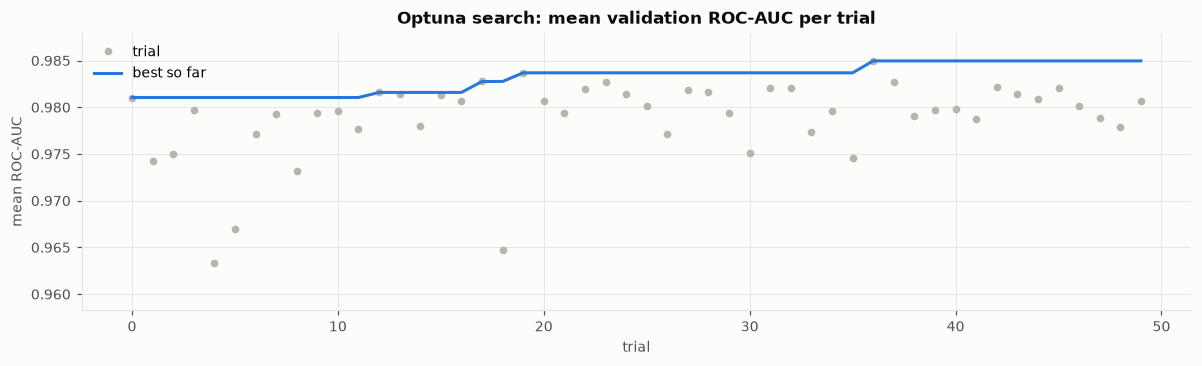

,number,value,user_attrs_fold1,user_attrs_fold2,user_attrs_fold3
36,36,0.9850,0.9605,0.9959,0.9985
19,19,0.9837,0.9566,0.9961,0.9984
17,17,0.9828,0.9542,0.9958,0.9983
23,23,0.9827,0.9548,0.9951,0.9983
37,37,0.9827,0.9540,0.9956,0.9984
42,42,0.9822,0.9536,0.9951,0.9979
31,31,0.9821,0.9519,0.9957,0.9985
32,32,0.9820,0.9528,0.9955,0.9978
45,45,0.9820,0.9523,0.9957,0.9980
22,22,0.9819,0.9520,0.9955,0.9983


In [35]:
hist = study.trials_dataframe(attrs=("number", "value", "user_attrs"))
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(hist.number, hist.value, lw=0, marker="o", ms=4, color=UNKNOWN, label="trial")
ax.plot(hist.number, hist.value.cummax(), lw=2, color=LICIT, label="best so far")
ax.set_title("Optuna search: mean validation ROC-AUC per trial")
ax.set_xlabel("trial"); ax.set_ylabel("mean ROC-AUC"); ax.legend()
ax.set_ylim(max(0.9, hist.value.min() - 0.005), hist.value.max() + 0.003)
plt.tight_layout(); plt.show()

# Do the top trials agree with each other? Spread across the 10 best trials, per fold.
top10 = hist.sort_values("value", ascending=False).head(10)
top10[["number", "value", "user_attrs_fold1", "user_attrs_fold2", "user_attrs_fold3"]].round(4)

> **Conclusion.** The 10 best trials agree closely on folds 2 and 3, all between 0.995 and 0.999. They differ mainly on fold 1, from 0.952 to 0.961. The best trial gained most of its lead on fold 1.
>
> Tuning was in effect optimising fold 1, the only fold with room to improve. The winning trial's score is therefore somewhat optimistic, because it was selected as the maximum over 50 tries. The seed-averaged score in 3.5, 0.984, is the fairer estimate.

## 3.4 Tuned model per fold and per time step

In [36]:
tuned_res, tuned_pred = run_cv(lambda: lgb_from_params(BEST_PARAMS), BASE_FEATURES, "LightGBM, tuned", keep_preds=True)
_, rf_pred = run_cv(make_rf, BASE_FEATURES, "Random forest", keep_preds=True)
_, lgbd_pred = run_cv(make_lgb_default, BASE_FEATURES, "LightGBM, default", keep_preds=True)

comparison = summarise(pd.concat([base_res, tuned_res]))
fit_check = pd.concat([base_res, tuned_res]).groupby("model", sort=False).agg(
    mean_train_roc_auc=("train_roc_auc", "mean"), mean_val_roc_auc=("roc_auc", "mean"))
fit_check["gap"] = fit_check.mean_train_roc_auc - fit_check.mean_val_roc_auc
display(comparison.round(4))
print("Overfitting check: training vs validation ROC-AUC")
fit_check.round(4)

,fold 1 ROC-AUC,fold 2 ROC-AUC,fold 3 ROC-AUC,mean ROC-AUC,mean PR-AUC,mean prec@top10%
model,,,,,,
Logistic regression,0.9259,0.9428,0.9624,0.9437,0.8339,0.8925
Random forest,0.8932,0.9939,0.9981,0.9617,0.9394,0.9490
"LightGBM, default",0.9549,0.9961,0.9979,0.9830,0.9511,0.9521
"LightGBM, tuned",0.9605,0.9959,0.9985,0.9850,0.9536,0.9528


Overfitting check: training vs validation ROC-AUC


,mean_train_roc_auc,mean_val_roc_auc,gap
model,,,
Logistic regression,0.9909,0.9437,0.0472
Random forest,1.0000,0.9617,0.0383
"LightGBM, default",1.0000,0.9830,0.0170
"LightGBM, tuned",1.0000,0.9850,0.0150


> **Conclusion.** Tuned LightGBM is best on mean ROC-AUC, 0.985, mean PR-AUC, 0.954, and precision in the top 10%, 0.953. Every tree model fits its training data perfectly, but tuned LightGBM has the smallest gap between training and validation scores, 0.015.
>
> The smaller validation gap shows that tuning, through shallower trees and feature subsampling, reduced overfitting compared with the default model and random forest.

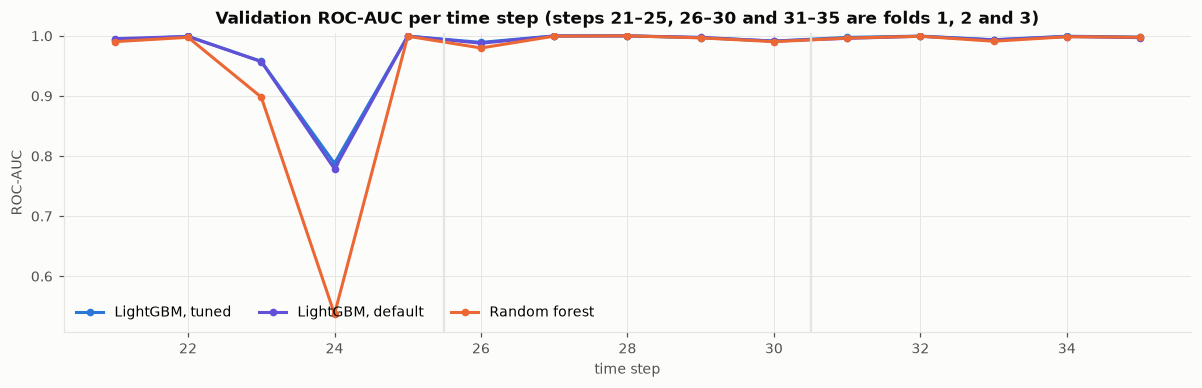

time_step,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
"LightGBM, tuned",0.9930,0.9990,0.9580,0.7880,1.0000,0.9890,1.0000,1.0000,0.9970,0.9910,0.9970,1.0000,0.9940,0.9990,0.9980
"LightGBM, default",0.9950,0.9990,0.9570,0.7790,1.0000,0.9880,1.0000,1.0000,0.9980,0.9910,0.9960,0.9990,0.9930,0.9990,0.9970
Random forest,0.9900,0.9980,0.8980,0.5370,0.9990,0.9800,1.0000,1.0000,0.9970,0.9900,0.9960,0.9990,0.9910,0.9990,0.9980


In [37]:
steps = pd.DataFrame({
    "LightGBM, tuned": per_step_auc(tuned_pred),
    "LightGBM, default": per_step_auc(lgbd_pred),
    "Random forest": per_step_auc(rf_pred),
})
fig, ax = plt.subplots(figsize=(11, 3.6))
for col, colr in zip(steps.columns, [LICIT, "#6250d6", ILLICIT]):
    ax.plot(steps.index, steps[col], lw=2, marker="o", ms=4, color=colr, label=col)
for cut, _ in FOLDS[1:]:
    ax.axvline(cut + 0.5, color=GRID, lw=1.5)
ax.set_title("Validation ROC-AUC per time step (steps 21–25, 26–30 and 31–35 are folds 1, 2 and 3)")
ax.set_xlabel("time step"); ax.set_ylabel("ROC-AUC"); ax.legend(ncol=3, loc="lower left")
ax.set_ylim(max(0.5, steps.min().min() - 0.03), 1.005)
plt.tight_layout(); plt.show()
steps.T.round(3)

> **Conclusion.** Validation ROC-AUC is at or above 0.99 in 13 of 15 steps. The exceptions are step 23, at 0.96, and step 24, at 0.79 for LightGBM and only 0.54 for random forest. Fold 1's lower score comes almost entirely from step 24.

## 3.5 Ablations

Each ablation changes **one** setting of the tuned model and keeps everything else fixed. Every variant runs with three random seeds, and its validation predictions are averaged across seeds.

**Decision rule: a paired bootstrap.** Validation rows are resampled 500 times within each fold. For each resample, the variant's and the base's ROC-AUC are computed on the same rows, giving a distribution of the gain. A variant is adopted only if:

1. the 95% interval for its mean gain across folds lies entirely above zero, and
2. no single fold is significantly worse, meaning that fold's 95% interval does not lie entirely below zero.

Seed variation alone cannot set the threshold. If the tuned model uses every row and feature, changing the seed changes nothing, and the noise estimate would be zero.

In [38]:
SEEDS = [42, 7, 2024]
n_pos, n_neg = int(Y.sum()), int((Y == 0).sum())
RATIO = n_neg / n_pos

def linear_recency(ts):
    return ts / ts.max()

def exp_recency(ts, half_life=10):
    return 0.5 ** ((ts.max() - ts) / half_life)

def nbscore_extra(tr, va, params=None):
    """Two-stage neighbour score built inside the fold (section 2.6).
    Training rows get out-of-fold first-stage scores (models that never saw their time steps);
    validation rows are scored by a first-stage model fitted on all training rows."""
    params = params or BEST_PARAMS
    tr_df, va_df = train_lab.loc[tr].reset_index(drop=True), train_lab.loc[va].reset_index(drop=True)
    steps_tr = np.sort(tr_df.time_step.unique())
    oof = pd.Series(np.nan, index=tr_df.txId.to_numpy())
    for grp in np.array_split(steps_tr, 5):
        m_in = tr_df.time_step.isin(grp).to_numpy()
        m1 = lgb_from_params(params).fit(tr_df.loc[~m_in, BASE_FEATURES], tr_df.label[~m_in])
        oof.loc[tr_df.txId[m_in].to_numpy()] = m1.predict_proba(tr_df.loc[m_in, BASE_FEATURES])[:, 1]
    m_all = lgb_from_params(params).fit(tr_df[BASE_FEATURES], tr_df.label)
    va_scores = pd.Series(m_all.predict_proba(va_df[BASE_FEATURES])[:, 1], index=va_df.txId.to_numpy())
    return neighbour_score_features(tr_df, oof), neighbour_score_features(va_df, va_scores)

ABLATIONS = {
    "Tuned base":                         dict(),
    "Class weight 2.8 (sqrt ratio)":      dict(overrides={"scale_pos_weight": np.sqrt(RATIO)}),
    "Class weight 7.6 (full ratio)":      dict(overrides={"scale_pos_weight": RATIO}),
    "Recency weight, linear":             dict(sample_weight_fn=linear_recency),
    "Recency weight, half-life 10 steps": dict(sample_weight_fn=exp_recency),
    "Training window steps 7–35":         dict(min_step=7),
    "+ time-proxy, detrended":            dict(cols=BASE_FEATURES + CLOCK_DT),
    "+ structural features":              dict(cols=BASE_FEATURES + STRUCT),
    "+ neighbour aggregates":             dict(cols=BASE_FEATURES + NBAGG),
    "+ two-stage neighbour score":        dict(extra_fn=nbscore_extra),
}

def run_config(cfg, name):
    """Run one configuration over all seeds. Returns per-seed fold scores and seed-averaged validation predictions."""
    rows, preds = [], []
    for seed in SEEDS:
        r, pr = run_cv(lambda: lgb_from_params(BEST_PARAMS, seed=seed, **cfg.get("overrides", {})),
                       cfg.get("cols", BASE_FEATURES), name, min_step=cfg.get("min_step", 1),
                       sample_weight_fn=cfg.get("sample_weight_fn"), extra_fn=cfg.get("extra_fn"), keep_preds=True)
        r["seed"] = seed
        rows.append(r); preds.append(pr.reset_index(drop=True))
    avg = preds[0].copy()
    avg["p"] = np.mean([q.p.to_numpy() for q in preds], axis=0)
    return pd.concat(rows), avg

def run_ablations():
    rows, preds = [], {}
    for name, cfg in ABLATIONS.items():
        r, pr = run_config(cfg, name)
        rows.append(r); preds[name] = pr
    return pd.concat(rows), preds

t0 = time.time()
abl, abl_preds = cached(f"ablations_v2_{N_TRIALS}trials_{len(SEEDS)}seeds", run_ablations)
print(f"Ablations done in {time.time() - t0:.0f}s")

Loaded cached result: artifacts/ablations_v2_50trials_3seeds.pkl
Ablations done in 0s


In [39]:
N_BOOT = 500
rng = np.random.default_rng(RANDOM_STATE)
base_p = abl_preds["Tuned base"]
y_val, fold_id = base_p.y.to_numpy(), base_p.fold.to_numpy()
fold_rows = [np.where(fold_id == k)[0] for k in (1, 2, 3)]
BOOT = [[rng.choice(ix, len(ix), replace=True) for ix in fold_rows] for _ in range(N_BOOT)]

def fold_aucs(p, idx_sets):
    return np.array([roc_auc_score(y_val[ix], p[ix]) for ix in idx_sets])

def paired_bootstrap(p_var, p_base):
    """Distribution of per-fold ROC-AUC gains (variant minus base) over bootstrap resamples, shape (N_BOOT, 3)."""
    return np.array([fold_aucs(p_var, b) - fold_aucs(p_base, b) for b in BOOT])

pb = base_p.p.to_numpy()
base_fold_auc = fold_aucs(pb, fold_rows)
recs, BOOT_DELTAS = [], {}
for name, pr in abl_preds.items():
    pv = pr.p.to_numpy()
    assert (pr.y.to_numpy() == y_val).all()            # same validation rows, same order
    fa = fold_aucs(pv, fold_rows)
    d = paired_bootstrap(pv, pb) if name != "Tuned base" else np.zeros((N_BOOT, 3))
    BOOT_DELTAS[name] = d
    mean_d = d.mean(axis=1)
    fold_hi = np.quantile(d, 0.975, axis=0)
    recs.append({"model": name, **{f"fold {k + 1} ROC-AUC": fa[k] for k in range(3)},
                 "mean ROC-AUC": fa.mean(), "Δ mean vs base": fa.mean() - base_fold_auc.mean(),
                 "95% CI low": np.quantile(mean_d, 0.025), "95% CI high": np.quantile(mean_d, 0.975),
                 "worst fold Δ": (fa - base_fold_auc).min(),
                 "fold significantly worse": bool((fold_hi < 0).any()),
                 "seed std": abl[abl.model == name].groupby("seed").roc_auc.mean().std(),
                 "mean PR-AUC":
                     np.mean([average_precision_score(y_val[ix], pv[ix]) for ix in fold_rows])})
abl_table = pd.DataFrame(recs).set_index("model")
passes = (abl_table["95% CI low"] > 0) & ~abl_table["fold significantly worse"]
abl_table["adopt"] = np.where(abl_table.index == "Tuned base", "base", np.where(passes, "yes", "no"))
print(f"Scores use seed-averaged predictions ({len(SEEDS)} seeds); intervals from {N_BOOT} paired bootstrap resamples.")
abl_table.round(4)

Scores use seed-averaged predictions (3 seeds); intervals from 500 paired bootstrap resamples.


,fold 1 ROC-AUC,fold 2 ROC-AUC,fold 3 ROC-AUC,mean ROC-AUC,Δ mean vs base,95% CI low,95% CI high,worst fold Δ,fold significantly worse,seed std,mean PR-AUC,adopt
model,,,,,,,,,,,,
Tuned base,0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,0.0000,False,0.0018,0.9530,base
Class weight 2.8 (sqrt ratio),0.9519,0.9965,0.9986,0.9823,-0.0015,-0.0021,-0.0008,-0.0042,True,0.0023,0.9525,no
Class weight 7.6 (full ratio),0.9553,0.9959,0.9983,0.9832,-0.0006,-0.0011,-0.0001,-0.0009,True,0.0008,0.9525,no
"Recency weight, linear",0.9473,0.9965,0.9983,0.9807,-0.0031,-0.0039,-0.0023,-0.0088,True,0.0012,0.9511,no
"Recency weight, half-life 10 steps",0.9496,0.9965,0.9984,0.9815,-0.0023,-0.0030,-0.0017,-0.0065,True,0.0023,0.9513,no
Training window steps 7–35,0.9457,0.9960,0.9983,0.9800,-0.0038,-0.0049,-0.0028,-0.0104,True,0.0006,0.9502,no
"+ time-proxy, detrended",0.9479,0.9960,0.9985,0.9808,-0.0030,-0.0038,-0.0022,-0.0082,True,0.0010,0.9512,no
+ structural features,0.9412,0.9964,0.9985,0.9787,-0.0051,-0.0065,-0.0038,-0.0150,True,0.0027,0.9503,no
+ neighbour aggregates,0.9501,0.9965,0.9987,0.9818,-0.0020,-0.0028,-0.0012,-0.0060,True,0.0018,0.9521,no


> **Conclusion.** No ablation improved on the tuned base. All nine variants lowered mean ROC-AUC by 0.0006 to 0.0051, and every 95% interval lies below zero. In every case the loss falls on fold 1, while folds 2 and 3 change by at most 0.0003. Structural features hurt most, and class weight 7.6 hurt least.
>
> The tuned base is kept unchanged. Two caveats apply. First, the hyperparameters were tuned for the base settings, which gives the base an advantage over every variant. Second, the bootstrap resamples rows, not time steps, so it understates uncertainty that comes from a single hard step such as step 24. These results therefore show that no variant helps on these folds, not that every variant would hurt on test.

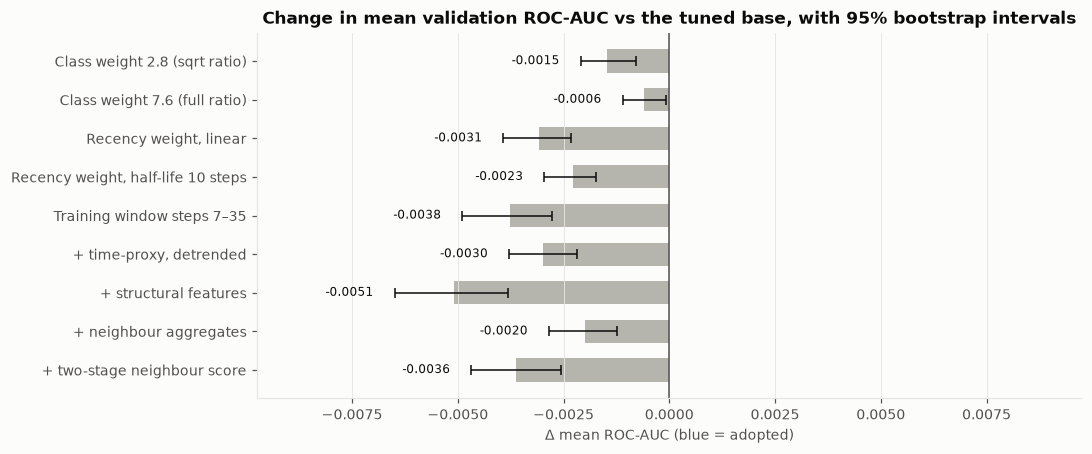

In [40]:
d = abl_table.drop(index="Tuned base")[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [LICIT if a == "yes" else UNKNOWN for a in d["adopt"]]
ax.barh(d.index, d["Δ mean vs base"], color=colors, height=0.6)
ax.errorbar(d["Δ mean vs base"], d.index,
            xerr=[d["Δ mean vs base"] - d["95% CI low"], d["95% CI high"] - d["Δ mean vs base"]],
            fmt="none", ecolor=INK, capsize=3, lw=1)
ax.axvline(0, color=MUTED, lw=1)
for i, (v, hi, lo) in enumerate(zip(d["Δ mean vs base"], d["95% CI high"], d["95% CI low"])):
    ax.text(hi + 0.0005 if v >= 0 else lo - 0.0005, i, f"{v:+.4f}", va="center",
            ha="left" if v >= 0 else "right", color=INK, fontsize=8)
ax.set_title("Change in mean validation ROC-AUC vs the tuned base, with 95% bootstrap intervals")
ax.set_xlabel("Δ mean ROC-AUC (blue = adopted)"); ax.grid(axis="y", visible=False)
lim = max(d["95% CI high"].abs().max(), d["95% CI low"].abs().max()) * 1.5
ax.set_xlim(-lim, lim)
plt.tight_layout(); plt.show()

> **Conclusion.** The chart shows each variant's loss with its 95% interval. All intervals sit to the left of zero, and none overlaps it except class weight 7.6, which only just clears it.
>
> Graph features were unhelpful with the tuned model: structural features, neighbour aggregates and the two-stage neighbour score all lowered fold 1. This supports the explanation that the provided anonymised features already capture the neighbourhood information.
>
> **Configuration carried forward.** No setting passed the bootstrap test, so section 3 keeps tuned LightGBM on the 110 pruned features, with no class weighting, no recency weighting and all training steps.

## 3.6 Fit on all training steps and test predictions

The configuration is refitted on all labelled steps 1–35 and averaged over the three seeds. The number of trees stays as tuned. The final training set is about 16% larger than fold 3's, which is too small a change to justify rescaling it.

In [41]:
X_fit = FULL_TRAIN[BASE_FEATURES].reset_index(drop=True)
X_pred = FULL_TEST[BASE_FEATURES].reset_index(drop=True)
y_fit = Y

test_preds, final_models = [], []
for seed in SEEDS:
    m = lgb_from_params(BEST_PARAMS, seed=seed).fit(X_fit, y_fit)
    final_models.append(m); test_preds.append(m.predict_proba(X_pred)[:, 1])
test_pred = np.mean(test_preds, axis=0)

os.makedirs("submissions", exist_ok=True)
sub = pd.DataFrame({"index": test_df["index"].to_numpy(), "target": test_pred})
SUB_PATH = "submissions/tuned_lgbm.csv"
sub.to_csv(SUB_PATH, index=False)

print(f"Training rows: {len(X_fit):,} | features: {X_fit.shape[1]} | seeds averaged: {len(SEEDS)}")
print(f"Saved {SUB_PATH}: {len(sub):,} rows, columns {list(sub.columns)}")
print(f"Correlation of test predictions between seeds: {np.corrcoef(test_preds).min():.4f} (lowest pair)")
sub.target.describe().to_frame("predicted probability").T.round(4)

Training rows: 31,235 | features: 110 | seeds averaged: 3
Saved submissions/tuned_lgbm.csv: 15,329 rows, columns ['index', 'target']
Correlation of test predictions between seeds: 0.9912 (lowest pair)


,count,mean,std,min,25%,50%,75%,max
predicted probability,"15,329.0000",0.0425,0.1915,0.0000,0.0000,0.0000,0.0003,1.0000


> **Conclusion.** The tuned model was refitted on all 31,235 labelled rows and averaged over 3 seeds, whose test predictions correlate at 0.99 or more. The predictions are very skewed: the median is close to 0, while the mean is 0.043.

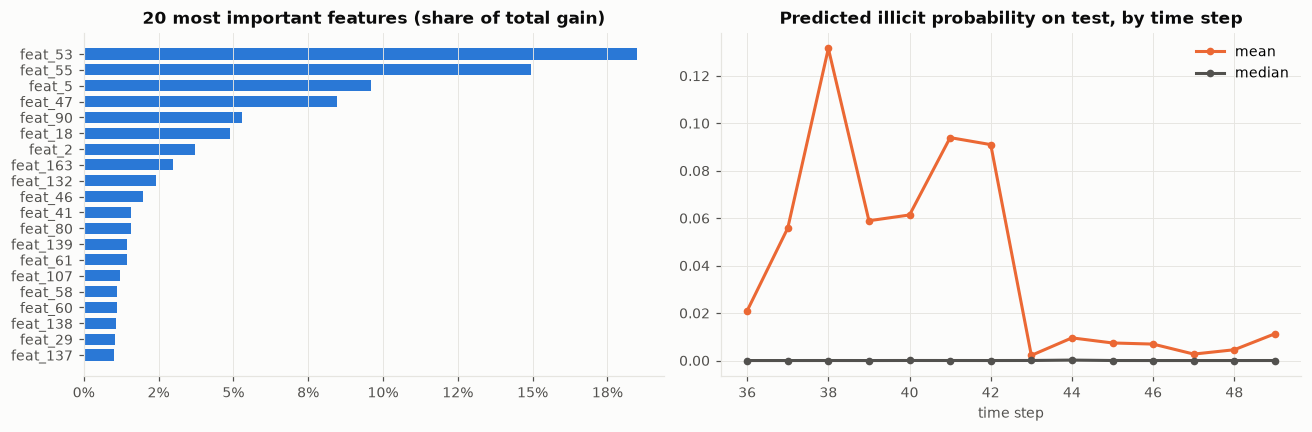

Top 10 features hold 73% of total gain


time_step,36,37,38,39,40,41,42,43,44,45,46,47,48,49
mean,0.0210,0.0560,0.1320,0.0590,0.0610,0.0940,0.0910,0.0020,0.0100,0.0070,0.0070,0.0030,0.0050,0.0110
median,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [42]:
imp = pd.DataFrame({"feature": X_fit.columns,
                    "gain": np.mean([m.booster_.feature_importance("gain") for m in final_models], axis=0)})
imp["share"] = imp.gain / imp.gain.sum()
imp = imp.sort_values("share", ascending=False)

pred_by_step = pd.DataFrame({"time_step": test_df.time_step, "p": test_pred}).groupby("time_step").p.agg(["mean", "median"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t20 = imp.head(20)[::-1]
axes[0].barh(t20.feature, t20.share, color=LICIT, height=0.7)
axes[0].set_title("20 most important features (share of total gain)")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[0].grid(axis="y", visible=False)
axes[1].plot(pred_by_step.index, pred_by_step["mean"], lw=2, marker="o", ms=4, color=ILLICIT, label="mean")
axes[1].plot(pred_by_step.index, pred_by_step["median"], lw=2, marker="o", ms=4, color=MUTED, label="median")
axes[1].set_title("Predicted illicit probability on test, by time step")
axes[1].set_xlabel("time step"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Top 10 features hold {imp.share.head(10).sum():.0%} of total gain")
pred_by_step.T.round(3)

> **Conclusion.** The top 10 features carry 73% of the model's total gain. On test, average predicted risk falls sharply from step 43 onward: it is 0.02 to 0.13 in steps 36 to 42 and 0.002 to 0.011 in steps 43 to 49.
>
> The sharp drop at step 43 suggests that transactions in those steps differ from anything in training, so the model may be missing new kinds of illicit behaviour there. ROC-AUC ranks all test transactions together, so systematically low scores in late steps could pull illicit cases there below licit ones from earlier steps. Section 4 should test ways to reduce this, such as ranking predictions within each time step.

## 3.7 Summary of model development

| Question | Answer | Evidence |
|---|---|---|
| Best baseline | Untuned LightGBM | Mean ROC-AUC 0.983, against 0.962 for random forest and 0.944 for logistic regression |
| Effect of tuning | Small gain, mostly on fold 1 | 0.981 to 0.985 for the best single seed; 0.984 averaged over 3 seeds |
| Tuned configuration | 350 trees of 12 leaves, learning rate 0.125, 60% of features per tree | Optuna, 50 trials |
| Class weighting | Not used | Both weights lowered fold 1 ROC-AUC |
| Recency weighting | Not used | Both schemes lowered fold 1 ROC-AUC |
| Dropping steps 1–6 | Not used | Lowered fold 1 ROC-AUC by 0.010 |
| Graph features with the tuned model | Not used | All lowered fold 1 ROC-AUC; structural features most |
| Hardest period | Step 24 | ROC-AUC 0.79 for LightGBM and 0.54 for random forest |
| Submission | `submissions/tuned_lgbm.csv` | Tuned LightGBM, 3 seeds, all labelled steps |

**Main risk going into section 4.** Validation is close to its ceiling on two of three folds, so it cannot separate strong models well. On test, predicted risk drops sharply from step 43. Section 4 should compare model families and ensembles, and check how ranking predictions within each time step changes the result.


# 4. Model Exploration and Final Strategy

Section 3's tuned LightGBM scored 0.984 on validation but **0.950 on the public leaderboard**. The gap points to drift that the validation folds understate. This section explores ways to close it.

| Stage | Question | Sections |
|---|---|---|
| 1 | Are other models better? | 4.2 other model families and ensembles · 4.3 LightGBM variants · 4.4 tuning on the long-horizon splits |
| 2 | Can drift be corrected? | 4.5 drift corrections |
| 3 | Does the graph add stable signal? | 4.6 community detection · 4.7 graph signal in models |
| 4 | Can the unfamiliar illicit cases be found? | 4.8 unsupervised novelty scores |
| 5 | How should the final model be chosen? | 4.9 choosing the final model |

**Two validation designs.** The three short folds of section 2.1 retrain every five steps. The **long-horizon splits** (defined in 4.1) train once and score the next 14 steps pooled, as the test set does.

**Decision rules.** On the short folds, as in 3.5: a change is adopted only if the paired-bootstrap 95% interval for its mean ROC-AUC gain lies above zero and no fold is significantly worse. On the long-horizon design: a change must raise the four-split mean and improve at least 3 of the 4 splits. The public leaderboard (30% of the test set, about 270 illicit cases) is used sparingly, for probes of close candidates. A probe replaces the current model only if it clearly beats it.

## 4.1 Shared tools and reference predictions

In [43]:
import xgboost as xgb
import catboost as cb
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold, cross_val_predict

VAL = abl_preds["Tuned base"][["fold", "time_step", "y"]].reset_index(drop=True)
VAL_STEP = VAL.time_step.to_numpy()
assert (VAL.y.to_numpy() == y_val).all()

def fold_rank(p):
    """Rank predictions within each validation fold, scaled to (0, 1]. Each fold stands in for one test set."""
    r = np.empty_like(p, dtype=float)
    for ix in fold_rows:
        r[ix] = rankdata(p[ix]) / len(ix)
    return r

def compare(preds, ref_name):
    """Per-fold ROC-AUC for each prediction vector, with a paired-bootstrap interval for the gain over `ref_name`."""
    ref = preds[ref_name]
    rows = []
    for name, p in preds.items():
        fa = fold_aucs(p, fold_rows)
        d = paired_bootstrap(p, ref) if name != ref_name else np.zeros((N_BOOT, 3))
        md_ = d.mean(axis=1)
        rows.append({"model": name, **{f"fold {k + 1}": fa[k] for k in range(3)}, "mean ROC-AUC": fa.mean(),
                     "Δ vs ref": fa.mean() - fold_aucs(ref, fold_rows).mean(),
                     "95% CI low": np.quantile(md_, 0.025), "95% CI high": np.quantile(md_, 0.975),
                     "fold significantly worse": bool((np.quantile(d, 0.975, axis=0) < 0).any()),
                     "mean PR-AUC": np.mean([average_precision_score(y_val[ix], p[ix]) for ix in fold_rows]),
                     "step 24 ROC-AUC": roc_auc_score(y_val[VAL_STEP == 24], p[VAL_STEP == 24])})
    t = pd.DataFrame(rows).set_index("model")
    t["adopt"] = np.where(t.index == ref_name, "reference",
                          np.where((t["95% CI low"] > 0) & ~t["fold significantly worse"], "yes", "no"))
    return t

def fold_data(k, cols=None):
    cut, end = FOLDS[k]
    tr, va = fold_masks(cut, end)
    cols = cols or BASE_FEATURES
    return (FULL_TRAIN.loc[tr, cols].reset_index(drop=True), Y[tr],
            FULL_TRAIN.loc[va, cols].reset_index(drop=True), tr, va)

def fit_predict(make, Xtr, ytr, Xva, w=None, seeds=SEEDS):
    """Average of predicted probabilities over seeds."""
    ps = []
    for s in seeds:
        m = make(s)
        m.fit(Xtr, ytr, sample_weight=w) if w is not None else m.fit(Xtr, ytr)
        ps.append(m.predict_proba(Xva)[:, 1])
    return np.mean(ps, axis=0)

def cv_member(make, prep=None, seeds=SEEDS):
    """Validation predictions aligned with VAL. prep(k) -> (Xtr, ytr, Xva, w) overrides the default fold data."""
    out = []
    for k in range(len(FOLDS)):
        if prep is None:
            Xtr, ytr, Xva, _, _ = fold_data(k); w = None
        else:
            Xtr, ytr, Xva, w = prep(k)
        out.append(fit_predict(make, Xtr, ytr, Xva, w, seeds))
    return np.concatenate(out)

def make_rf_seed(s):
    return RandomForestClassifier(n_estimators=500, max_features="sqrt", class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=s)

OOF = {"LightGBM (tuned)": abl_preds["Tuned base"].p.to_numpy()}
OOF["Random forest"] = cached("oof_rf_3seeds", lambda: cv_member(make_rf_seed))
_, lr_p = run_cv(make_lr, BASE_FEATURES, "Logistic regression", keep_preds=True)
OOF["Logistic regression"] = lr_p.p.to_numpy()
print("Reference predictions:", list(OOF))

Loaded cached result: artifacts/oof_rf_3seeds.pkl


Reference predictions: ['LightGBM (tuned)', 'Random forest', 'Logistic regression']


**Long-horizon splits.** The test set asks one model to score 14 later steps without retraining. These four splits do the same inside the training period. Every learned component of a model, such as adversaries, first-stage scores and Isolation Forests, is fitted only on a split's training steps. `lh_add` records each model's predictions on all four splits as the sections below build them; 4.9 compares them with the public scores.

In [44]:
# Long-horizon validation design: four splits, each training once and scoring the next 14 steps pooled.
import re
LH_SPLITS = [(15, 29), (17, 31), (19, 33), (21, 35)]
LH_MASKS = {f"{c}->{e}": (TS <= c, (TS > c) & (TS <= e)) for c, e in LH_SPLITS}
LH_Y = {k: Y[va] for k, (tr, va) in LH_MASKS.items()}
LH_PREDS = {k: {} for k in LH_MASKS}                       # model name -> scored-row predictions, per split
LH_RES = {k: {"preds": LH_PREDS[k], "y": LH_Y[k], "steps": TS[va]} for k, (tr, va) in LH_MASKS.items()}
N_ORD = 3                                                  # default-LightGBM models are averaged over 3 column orderings
n_test = len(test_df)

def rank01(p):
    return rankdata(p) / len(p)

def ordered_avg(Xtr, ytr, Xva, n):
    """Default LightGBM averaged over n column orderings (rank-averaged). LightGBM breaks ties between equally good
    splits by column position, and single fits vary more the further ahead they predict."""
    cols = list(Xtr.columns); ps = []
    for i in range(n):
        o = list(np.random.default_rng(i).permutation(cols))
        ps.append(rankdata(make_lgb_default().fit(Xtr[o], ytr).predict_proba(Xva[o])[:, 1]) / len(Xva))
    return np.mean(ps, axis=0), ps

def xdef(mask, src="train"):
    """The 110 base features for a row mask of the labelled training rows (or all test rows)."""
    base = FULL_TRAIN if src == "train" else FULL_TEST
    return (base.loc[mask] if mask is not None else base)[BASE_FEATURES].reset_index(drop=True)

cat = lambda *parts: pd.concat([p.reset_index(drop=True) for p in parts], axis=1)
tuned = lambda s: lgb_from_params(BEST_PARAMS, seed=s)

def lh_add(name, fn):
    """Long-horizon predictions of one model on every split: fn(train_mask, scored_mask, split_key), cached."""
    slug = re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_").lower()
    for k, (tr, va) in LH_MASKS.items():
        LH_PREDS[k][name] = cached(f"lh_{slug}_{k.replace('->', '_')}", lambda tr=tr, va=va, k=k: fn(tr, va, k))

def lh_auc(names):
    """Per-split ROC-AUC and the four-split mean for the named models."""
    t = pd.DataFrame({k: {n: roc_auc_score(LH_Y[k], LH_PREDS[k][n]) for n in names} for k in LH_MASKS})
    t["long-horizon mean"] = t.mean(axis=1)
    return t

def check_submission(path):
    """A file is uploadable only if it has one finite probability in [0, 1] for every test index, each exactly once."""
    s = pd.read_csv(path)
    ok = (list(s.columns) == ["index", "target"] and len(s) == len(test_df) and s["index"].is_unique
          and set(s["index"]) == set(test_df["index"]) and np.isfinite(s.target).all() and s.target.between(0, 1).all())
    if not ok:
        raise ValueError(f"Submission file failed checks: {path}")
    return True

pd.DataFrame({"train steps": [f"1 to {c}" for c, _ in LH_SPLITS], "scored steps": [f"{c + 1} to {e}" for c, e in LH_SPLITS],
              "scored rows": [int(LH_MASKS[k][1].sum()) for k in LH_MASKS]}, index=list(LH_MASKS))

,train steps,scored steps,scored rows
15->29,1 to 15,16 to 29,10867
17->31,1 to 17,18 to 31,10760
19->33,1 to 19,20 to 33,11390
21->35,1 to 21,22 to 35,11705


## Stage 1: Are other models better?

## 4.2 Other model families and ensembles

Both are gradient-boosted tree libraries, like LightGBM, but they grow trees differently. XGBoost grows trees level by level, and CatBoost builds symmetric trees with ordered boosting. Those differences can make their errors only partly overlap with LightGBM's, which is what an ensemble needs. Each gets 25 Optuna trials on the same folds and objective as LightGBM, and is then scored with three seeds.

In [45]:
def make_xgb(params, seed):
    return xgb.XGBClassifier(**params, tree_method="hist", eval_metric="logloss",
                             n_jobs=LGB_THREADS, random_state=seed, verbosity=0)

def make_cat(params, seed):
    return cb.CatBoostClassifier(**params, bootstrap_type="Bernoulli", thread_count=LGB_THREADS,
                                 random_seed=seed, verbose=0, allow_writing_files=False)

def xgb_space(t):
    return {"n_estimators": t.suggest_int("n_estimators", 100, 1000, step=50),
            "learning_rate": t.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "max_depth": t.suggest_int("max_depth", 2, 8),
            "min_child_weight": t.suggest_float("min_child_weight", 1, 20, log=True),
            "subsample": t.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": t.suggest_float("colsample_bytree", 0.2, 1.0),
            "reg_lambda": t.suggest_float("reg_lambda", 1e-3, 10.0, log=True)}

def cat_space(t):
    return {"iterations": t.suggest_int("iterations", 200, 1200, step=100),
            "learning_rate": t.suggest_float("learning_rate", 0.02, 0.3, log=True),
            "depth": t.suggest_int("depth", 3, 8),
            "l2_leaf_reg": t.suggest_float("l2_leaf_reg", 1, 20, log=True),
            "rsm": t.suggest_float("rsm", 0.3, 1.0),
            "subsample": t.suggest_float("subsample", 0.6, 1.0)}

def tune(space, make, n_trials=25):
    def obj(t):
        params = space(t)
        return fold_aucs(cv_member(lambda s: make(params, s), seeds=[RANDOM_STATE]), fold_rows).mean()
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    st.optimize(obj, n_trials=n_trials)
    return st

t0 = time.time()
xgb_study = cached("optuna_xgb_25trials", lambda: tune(xgb_space, make_xgb))
cat_study = cached("optuna_cat_25trials", lambda: tune(cat_space, make_cat))
XGB_PARAMS, CAT_PARAMS = xgb_study.best_params, cat_study.best_params
OOF["XGBoost (tuned)"] = cached("oof_xgb_3seeds", lambda: cv_member(lambda s: make_xgb(XGB_PARAMS, s)))
OOF["CatBoost (tuned)"] = cached("oof_cat_3seeds", lambda: cv_member(lambda s: make_cat(CAT_PARAMS, s)))
print(f"Done in {time.time() - t0:.0f}s")
print("XGBoost best params:", {k: round(v, 4) if isinstance(v, float) else v for k, v in XGB_PARAMS.items()})
print("CatBoost best params:", {k: round(v, 4) if isinstance(v, float) else v for k, v in CAT_PARAMS.items()})
family = compare(OOF, "LightGBM (tuned)")
family.round(4)

Loaded cached result: artifacts/optuna_xgb_25trials.pkl
Loaded cached result: artifacts/optuna_cat_25trials.pkl
Loaded cached result: artifacts/oof_xgb_3seeds.pkl
Loaded cached result: artifacts/oof_cat_3seeds.pkl
Done in 0s
XGBoost best params: {'n_estimators': 400, 'learning_rate': 0.2329, 'max_depth': 8, 'min_child_weight': 11.9899, 'subsample': 0.9934, 'colsample_bytree': 0.4524, 'reg_lambda': 0.2366}
CatBoost best params: {'iterations': 700, 'learning_rate': 0.1677, 'depth': 4, 'l2_leaf_reg': 4.667, 'rsm': 0.7147, 'subsample': 0.6186}


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt
model,,,,,,,,,,,
LightGBM (tuned),0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,False,0.9530,0.7723,reference
Random forest,0.8985,0.9939,0.9980,0.9635,-0.0203,-0.0245,-0.0163,True,0.9399,0.5685,no
Logistic regression,0.9259,0.9428,0.9624,0.9437,-0.0401,-0.0440,-0.0364,True,0.8339,0.7137,no
XGBoost (tuned),0.9399,0.9948,0.9976,0.9774,-0.0063,-0.0080,-0.0049,True,0.9459,0.7071,no
CatBoost (tuned),0.9188,0.9944,0.9986,0.9706,-0.0132,-0.0161,-0.0104,True,0.9442,0.6554,no


> **Conclusion.** Tuned XGBoost reaches mean ROC-AUC 0.977 and tuned CatBoost 0.971, both below tuned LightGBM's 0.984. All the gap is on fold 1, where XGBoost scores 0.940 and CatBoost 0.919 against LightGBM's 0.956. On folds 2 and 3, all three are within 0.002 of each other.
>
> LightGBM stays the strongest single model. The other libraries are kept as possible ensemble members, because an ensemble can help even when its members are individually weaker. On step 24, the hardest step, LightGBM scores 0.77, XGBoost 0.71, CatBoost 0.66 and random forest 0.57.

**Rank-averaged ensembles.** Each model's predictions are converted to ranks within the fold, and the ranks are averaged. Ranks put every model on the same scale, which matters because the models' probabilities are calibrated differently. ROC-AUC depends only on ranking, so nothing is lost. Every combination of two to four of the tree models is tested. Logistic regression is left out because it is weaker.

In [46]:
from itertools import combinations
TREE_MODELS = ["LightGBM (tuned)", "XGBoost (tuned)", "CatBoost (tuned)", "Random forest"]
ens_preds = {"LightGBM (tuned)": OOF["LightGBM (tuned)"]}
for r in range(2, len(TREE_MODELS) + 1):
    for combo in combinations(TREE_MODELS, r):
        name = " + ".join(c.split(" (")[0] for c in combo)
        ens_preds[name] = np.mean([fold_rank(OOF[c]) for c in combo], axis=0)
ens_table = compare(ens_preds, "LightGBM (tuned)").sort_values("mean ROC-AUC", ascending=False)

passing = ens_table[ens_table.adopt == "yes"]
BEST_ENS = passing["mean ROC-AUC"].idxmax() if len(passing) else "LightGBM (tuned)"
MEMBERS = [m for m in TREE_MODELS if m.split(" (")[0] in BEST_ENS.split(" + ")] if BEST_ENS != "LightGBM (tuned)" else ["LightGBM (tuned)"]
print(f"Chosen approach after 4.2: {BEST_ENS} | members: {MEMBERS}")
ens_table.round(4)

Chosen approach after 4.2: LightGBM (tuned) | members: ['LightGBM (tuned)']


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt
model,,,,,,,,,,,
LightGBM (tuned),0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,False,0.9530,0.7723,reference
LightGBM + XGBoost,0.9503,0.9961,0.9982,0.9816,-0.0022,-0.0030,-0.0016,True,0.9506,0.7485,no
LightGBM + XGBoost + CatBoost,0.9423,0.9958,0.9985,0.9789,-0.0049,-0.0060,-0.0038,True,0.9489,0.7233,no
LightGBM + CatBoost,0.9402,0.9960,0.9986,0.9783,-0.0055,-0.0068,-0.0042,True,0.9488,0.7196,no
LightGBM + XGBoost + Random forest,0.9391,0.9962,0.9985,0.9779,-0.0059,-0.0072,-0.0046,True,0.9485,0.6975,no
LightGBM + XGBoost + CatBoost + Random forest,0.9356,0.9960,0.9986,0.9767,-0.0070,-0.0086,-0.0055,True,0.9481,0.6891,no
LightGBM + Random forest,0.9340,0.9961,0.9985,0.9762,-0.0076,-0.0093,-0.0059,True,0.9476,0.6764,no
XGBoost + CatBoost,0.9327,0.9950,0.9983,0.9753,-0.0084,-0.0103,-0.0066,True,0.9462,0.6901,no
LightGBM + CatBoost + Random forest,0.9311,0.9960,0.9987,0.9752,-0.0085,-0.0104,-0.0068,True,0.9475,0.6737,no


> **Conclusion.** No ensemble beat LightGBM alone. The best, LightGBM plus XGBoost, lost 0.002 in mean ROC-AUC, and adding random forest or CatBoost lost more. Every ensemble was significantly worse on fold 1 and level on folds 2 and 3. Ensembling does not help here. LightGBM's edge comes from handling the drifting step 24 better, and averaging with weaker models on that step only dilutes it. The chosen approach stays tuned LightGBM on its own.

## 4.3 LightGBM variants: feature set, seeds and default settings

2 refinements that validation never tested with the tuned model:

1. **Feature set.** Section 2 chose the 110 pruned features using an untuned model. Here the tuned LightGBM is tested on all 161 features that are not time proxies, and on 160 that also drop the near-constant feat_15. The 161-feature set is tested both with section 3's hyperparameters and re-tuned with 30 Optuna trials. The re-tuning starts from section 3's best configuration, so it can only match or improve on it.
2. **Seed count.** Averaging 10 seeds instead of 3 reduces the randomness from LightGBM's row and column sampling.

The decision rule from 3.5 applies to the feature set. The seed count uses a different yardstick. The paired bootstrap resamples validation rows while holding predictions fixed, so it cannot see seed-to-seed randomness. A different set of seeds can therefore look "significantly" better or worse purely by luck. Ten seeds are kept unless they score worse than three by more than twice the base model's seed standard deviation from 3.5. Averaging more seeds lowers variance and has no plausible real downside.

In [47]:
FEATS_161 = [f for f in FEATS if f not in CLOCK]
FEATS_160 = [f for f in FEATS_161 if f not in NEAR_CONST]
SEEDS_10 = [42, 7, 2024, 1, 2, 3, 4, 5, 6, 8]

def cv_lgb(params, cols, seeds):
    return cv_member(lambda s: lgb_from_params(params, seed=s),
                     prep=lambda k: (*fold_data(k, cols)[:3], None), seeds=seeds)

def lgb_space(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 1500, step=50),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
            "max_depth": trial.suggest_categorical("max_depth", [-1, 4, 6, 8, 12]),
            "min_child_samples": trial.suggest_int("min_child_samples", 10, 200, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True)}

def retune_161():
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    st.enqueue_trial(BEST_PARAMS)        # start from section 3's best configuration
    st.optimize(lambda t: fold_aucs(cv_lgb(lgb_space(t), FEATS_161, [RANDOM_STATE]), fold_rows).mean(), n_trials=30)
    return st

t0 = time.time()
study_161 = cached("optuna_lgb_161feats_30trials", retune_161)
PARAMS_161 = study_161.best_params
refine = {"Tuned base: 110 features, 3 seeds": OOF["LightGBM (tuned)"]}
refine["161 features, section 3 params, 3 seeds"] = cached("oof_lgb161_base_3seeds", lambda: cv_lgb(BEST_PARAMS, FEATS_161, SEEDS))
refine["160 features (no feat_15), section 3 params, 3 seeds"] = cached("oof_lgb160_base_3seeds", lambda: cv_lgb(BEST_PARAMS, FEATS_160, SEEDS))
refine["161 features, re-tuned, 3 seeds"] = cached("oof_lgb161_retuned_3seeds", lambda: cv_lgb(PARAMS_161, FEATS_161, SEEDS))
refine["110 features, 10 seeds"] = cached("oof_lgb110_10seeds", lambda: cv_lgb(BEST_PARAMS, BASE_FEATURES, SEEDS_10))
print(f"Done in {time.time() - t0:.0f}s | re-tuned best single-seed ROC-AUC on 161 features: {study_161.best_value:.4f} "
      f"(section 3 configuration: {study_161.trials[0].value:.4f})")
print("Re-tuned parameters:", {k: round(v, 4) if isinstance(v, float) else v for k, v in PARAMS_161.items()})
refine_table = compare(refine, "Tuned base: 110 features, 3 seeds")
refine_table.round(4)

Loaded cached result: artifacts/optuna_lgb_161feats_30trials.pkl
Loaded cached result: artifacts/oof_lgb161_base_3seeds.pkl
Loaded cached result: artifacts/oof_lgb160_base_3seeds.pkl
Loaded cached result: artifacts/oof_lgb161_retuned_3seeds.pkl
Loaded cached result: artifacts/oof_lgb110_10seeds.pkl
Done in 0s | re-tuned best single-seed ROC-AUC on 161 features: 0.9830 (section 3 configuration: 0.9790)
Re-tuned parameters: {'n_estimators': 500, 'learning_rate': 0.0195, 'num_leaves': 34, 'max_depth': 12, 'min_child_samples': 157, 'subsample': 0.9861, 'colsample_bytree': 0.5434, 'reg_lambda': 0.0022, 'reg_alpha': 0.205}


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt
model,,,,,,,,,,,
"Tuned base: 110 features, 3 seeds",0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,False,0.9530,0.7723,reference
"161 features, section 3 params, 3 seeds",0.9465,0.9970,0.9986,0.9807,-0.0031,-0.0041,-0.0022,True,0.9517,0.7289,no
"160 features (no feat_15), section 3 params, 3 seeds",0.9465,0.9970,0.9987,0.9807,-0.0030,-0.0040,-0.0022,True,0.9516,0.7289,no
"161 features, re-tuned, 3 seeds",0.9532,0.9967,0.9984,0.9828,-0.0010,-0.0015,-0.0004,True,0.9515,0.7766,no
"110 features, 10 seeds",0.9536,0.9968,0.9986,0.9830,-0.0008,-0.0010,-0.0005,True,0.9527,0.7598,no


> **Conclusion.** No feature-set variant beat the 110 pruned features. With section 3's hyperparameters, all 161 features lost 0.003, almost all of it on step 24, which fell from 0.77 to 0.73. Dropping feat_15 changed nothing. Re-tuning for 161 features recovered most of the gap, ending 0.001 below, and was slightly better on step 24. Averaging 10 seeds instead of 3 scored 0.0008 lower.
>
> Correlation pruning is confirmed with the tuned model, at least with section 3's hyperparameters. The re-tuned 161-feature model is close enough to count as a genuine alternative, so it is written as a leaderboard probe. Its gap of 0.001 is smaller than the seed noise of 0.0018.

In [48]:
# Seed count: the paired bootstrap holds predictions fixed, so it cannot see seed-to-seed randomness.
# Keep 10 seeds unless they are worse than 3 by more than twice the base model's seed standard deviation (3.5).
SEED_NOISE = 2 * abl_table.loc["Tuned base", "seed std"]
delta_10 = refine_table.loc["110 features, 10 seeds", "Δ vs ref"]
print(f"10 seeds vs 3 seeds: Δ mean ROC-AUC {delta_10:+.4f}; seed-noise threshold ±{SEED_NOISE:.4f}; "
      f"10 seeds kept: {delta_10 > -SEED_NOISE}")

10 seeds vs 3 seeds: Δ mean ROC-AUC -0.0008; seed-noise threshold ±0.0036; 10 seeds kept: True


> **Conclusion.** The feature set stays at 110. The seed count changes to 10: they scored 0.0008 below 3 seeds, well inside the seed-noise threshold of ±0.0036, so the 10-seed score of 0.9830 is the more honest estimate.
>
> **Leaderboard results.** Tuned LightGBM with 10 seeds scored 0.94969 publicly, a tie with 3 seeds (0.95034). The re-tuned 161-feature model scored 0.94616.

In [49]:
# Long-horizon predictions of the tuned models (used in 4.9).
lh_add("Tuned LightGBM, 3 seeds", lambda tr, va, k: fit_predict(tuned, xdef(tr), Y[tr], xdef(va), None, SEEDS))
lh_add("Tuned LightGBM, 10 seeds", lambda tr, va, k: fit_predict(tuned, xdef(tr), Y[tr], xdef(va), None, SEEDS_10))
lh_add("161 features, re-tuned", lambda tr, va, k: fit_predict(lambda s: lgb_from_params(PARAMS_161, seed=s),
       FULL_TRAIN.loc[tr, FEATS_161].reset_index(drop=True), Y[tr], FULL_TRAIN.loc[va, FEATS_161].reset_index(drop=True), None, SEEDS))
lh_auc(["Tuned LightGBM, 3 seeds", "Tuned LightGBM, 10 seeds", "161 features, re-tuned"]).round(4)

Loaded cached result: artifacts/lh_tuned_lightgbm_3_seeds_15_29.pkl
Loaded cached result: artifacts/lh_tuned_lightgbm_3_seeds_17_31.pkl
Loaded cached result: artifacts/lh_tuned_lightgbm_3_seeds_19_33.pkl
Loaded cached result: artifacts/lh_tuned_lightgbm_3_seeds_21_35.pkl
Loaded cached result: artifacts/lh_tuned_lightgbm_10_seeds_15_29.pkl
Loaded cached result: artifacts/lh_tuned_lightgbm_10_seeds_17_31.pkl
Loaded cached result: artifacts/lh_tuned_lightgbm_10_seeds_19_33.pkl
Loaded cached result: artifacts/lh_tuned_lightgbm_10_seeds_21_35.pkl
Loaded cached result: artifacts/lh_161_features_re_tuned_15_29.pkl
Loaded cached result: artifacts/lh_161_features_re_tuned_17_31.pkl
Loaded cached result: artifacts/lh_161_features_re_tuned_19_33.pkl
Loaded cached result: artifacts/lh_161_features_re_tuned_21_35.pkl


,15->29,17->31,19->33,21->35,long-horizon mean
"Tuned LightGBM, 3 seeds",0.9189,0.9252,0.8952,0.9072,0.9116
"Tuned LightGBM, 10 seeds",0.9136,0.9243,0.9220,0.9073,0.9168
"161 features, re-tuned",0.9026,0.9191,0.8991,0.9118,0.9082


**Default settings.** Tuning optimised the short folds, which are decided almost entirely by step 24 (3.4). If it over-fitted that one step, an untuned model may generalise further ahead. Three variants are compared with tuned LightGBM:

1. **Default LightGBM**: 100 trees of 31 leaves at learning rate 0.1, every feature in every tree.
2. **Default LightGBM trained more slowly**: 1,000 trees at learning rate 0.03, everything else at its defaults.
3. **Tuned LightGBM with the four raw time-proxy features restored**.

In [50]:
def make_lgb_slow(seed=RANDOM_STATE):
    return lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.03, random_state=seed, n_jobs=LGB_THREADS, verbose=-1)

t0 = time.time()
p_default_val = cached("oof_lgb_default", lambda: cv_member(lambda s: make_lgb_default(s), seeds=[RANDOM_STATE]))
default_val = {
    "Tuned LightGBM, 3 seeds": OOF["LightGBM (tuned)"],
    "Default LightGBM": p_default_val,
    "Default LightGBM, 1,000 trees at learning rate 0.03": cached("oof_lgb_slow", lambda: cv_member(lambda s: make_lgb_slow(s), seeds=[RANDOM_STATE])),
    "Tuned LightGBM + raw time-proxy features": cached("oof_lgb_clockraw_3seeds", lambda: cv_lgb(BEST_PARAMS, BASE_FEATURES + CLOCK, SEEDS)),
}
# Default LightGBM on the short folds averaged over 3 column orderings, the reference for later long-horizon-era comparisons.
default_ref_folds = cached("dcp419_folds_ref", lambda: np.concatenate([ordered_avg(xdef(fold_masks(c, e)[0]), Y[fold_masks(c, e)[0]],
                                                                                 xdef(fold_masks(c, e)[1]), N_ORD)[0] for c, e in FOLDS]))
p_default_test = cached("test_lgb_default", lambda: fit_predict(lambda s: make_lgb_default(s), xdef(None), Y, xdef(None, "test"), None, [RANDOM_STATE]))
lh_add("Default LightGBM", lambda tr, va, k: ordered_avg(xdef(tr), Y[tr], xdef(va), N_ORD)[0])
print(f"Done in {time.time() - t0:.0f}s")
default_table = compare(default_val, "Tuned LightGBM, 3 seeds")
default_table["within seed noise"] = default_table["Δ vs ref"].abs() < SEED_NOISE
default_table = default_table.join(lh_auc(["Tuned LightGBM, 3 seeds", "Default LightGBM"])["long-horizon mean"])
default_table.round(4)

Loaded cached result: artifacts/oof_lgb_default.pkl
Loaded cached result: artifacts/oof_lgb_slow.pkl
Loaded cached result: artifacts/oof_lgb_clockraw_3seeds.pkl
Loaded cached result: artifacts/dcp419_folds_ref.pkl
Loaded cached result: artifacts/test_lgb_default.pkl
Loaded cached result: artifacts/lh_default_lightgbm_15_29.pkl
Loaded cached result: artifacts/lh_default_lightgbm_17_31.pkl
Loaded cached result: artifacts/lh_default_lightgbm_19_33.pkl
Loaded cached result: artifacts/lh_default_lightgbm_21_35.pkl
Done in 0s


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt,within seed noise,long-horizon mean
model,,,,,,,,,,,,,
"Tuned LightGBM, 3 seeds",0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,False,0.9530,0.7723,reference,True,0.9116
Default LightGBM,0.9549,0.9961,0.9979,0.9830,-0.0008,-0.0016,-0.0000,True,0.9511,0.7786,no,True,0.9207
"Default LightGBM, 1,000 trees at learning rate 0.03",0.9525,0.9962,0.9982,0.9823,-0.0015,-0.0023,-0.0007,True,0.9521,0.7536,no,True,NaN
Tuned LightGBM + raw time-proxy features,0.9518,0.9961,0.9983,0.9821,-0.0017,-0.0024,-0.0011,True,0.9519,0.7441,no,True,NaN


> **Conclusion.** Default LightGBM scores 0.0008 below tuned LightGBM on the short folds, within seed noise, and slightly higher on step 24, at 0.779. On the long-horizon splits it is clearly better: 0.921 against 0.912. The slower default model scores 0.0015 below tuned and worse on step 24, at 0.754. Restoring the raw time proxies costs 0.0017, mostly through step 24, which falls from 0.772 to 0.744.
>
> Tuning bought nothing on the short folds beyond noise and cost ground far ahead in time. Extra fitting capacity, from tuning or from slower training, goes to the past. The time-proxy result confirms the section 2 decision to drop them.
>
> Tuning had over-fitted to step 24. Default LightGBM is the main model.

## 4.4 Tuning LightGBM on the long-horizon splits

Section 3 tuned LightGBM on the short folds, and the tuned model lost to default settings on the long-horizon splits and publicly, because the short folds are decided almost entirely by step 24. The long-horizon design tracks the leaderboard better (4.9), so this section tunes the main model on it instead.

**Search.** 20 Optuna trials (TPE sampler, fixed seed), with default LightGBM enqueued as trial 0 so it is the baseline. Only four parameters move, all around the defaults and mostly regularising: number of leaves (8 to 63), minimum rows per leaf (5 to 100), share of columns per tree (0.4 to 1.0) and number of trees (50 to 400), with the learning rate fixed at 0.1. The objective is the mean ROC-AUC over the four long-horizon splits, each averaged over 3 column orderings.

**Decision rule.** The best trial replaces default LightGBM as the main model only if it:
1. raises the long-horizon mean by at least 0.002,
2. improves at least 3 of the 4 splits, and
3. does not lower the short-fold mean by more than seed noise (0.0036).

If it passes, its rank average with the community risk model is checked against the final model in 4.9.

In [51]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def make_lgb(params, seed=RANDOM_STATE):
    return lgb.LGBMClassifier(**params, random_state=seed, n_jobs=LGB_THREADS, verbose=-1)

def ordered_avg_p(params, Xtr, ytr, Xva, n=N_ORD):
    """ordered_avg (4.1) for any LightGBM settings."""
    cols = list(Xtr.columns); ps = []
    for i in range(n):
        o = list(np.random.default_rng(i).permutation(cols))
        ps.append(rankdata(make_lgb(params).fit(Xtr[o], ytr).predict_proba(Xva[o])[:, 1]) / len(Xva))
    return np.mean(ps, axis=0)

LH_DATA = {f"{c}->{e}": (xdef(TS <= c), Y[TS <= c], xdef((TS > c) & (TS <= e)), Y[(TS > c) & (TS <= e)]) for c, e in LH_SPLITS}
DEFAULT_P = {"num_leaves": 31, "min_child_samples": 20, "colsample_bytree": 1.0, "n_estimators": 100}

def lh_scores(params):
    return {k: roc_auc_score(yva, ordered_avg_p(params, Xtr, ytr, Xva)) for k, (Xtr, ytr, Xva, yva) in LH_DATA.items()}

def run_lh_tuning(n_trials=20):
    def objective(trial):
        params = {"num_leaves": trial.suggest_int("num_leaves", 8, 63, log=True),
                  "min_child_samples": trial.suggest_int("min_child_samples", 5, 100, log=True),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                  "n_estimators": trial.suggest_int("n_estimators", 50, 400, step=25)}
        s = lh_scores(params)
        for k, v in s.items():
            trial.set_user_attr(k, v)
        return float(np.mean(list(s.values())))
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.enqueue_trial(DEFAULT_P)
    study.optimize(objective, n_trials=n_trials)
    return study.trials_dataframe(attrs=("number", "value", "params", "user_attrs")), study.best_params

t0 = time.time()
LHT_TRIALS, LHT_BEST = cached("lhtune418_20trials", run_lh_tuning)
print(f"Done in {time.time() - t0:.0f}s")
print("Best settings:", LHT_BEST)
print(f"Default LightGBM (trial 0): long-horizon mean {LHT_TRIALS.loc[0, 'value']:.4f}; "
      f"20 trials range {LHT_TRIALS.value.min():.4f} to {LHT_TRIALS.value.max():.4f}")
LHT_TRIALS.sort_values("value", ascending=False).head(8).round(4)

Loaded cached result: artifacts/lhtune418_20trials.pkl
Done in 0s
Best settings: {'num_leaves': 26, 'min_child_samples': 31, 'colsample_bytree': 0.8030369068946918, 'n_estimators': 200}
Default LightGBM (trial 0): long-horizon mean 0.9207; 20 trials range 0.8983 to 0.9259


,number,value,params_colsample_bytree,params_min_child_samples,params_n_estimators,params_num_leaves,user_attrs_15->29,user_attrs_17->31,user_attrs_19->33,user_attrs_21->35
12,12,0.9259,0.8030,31,200,26,0.9232,0.9299,0.9225,0.9281
1,1,0.9242,0.8392,86,250,17,0.9243,0.9436,0.9179,0.9108
5,5,0.9221,0.6592,23,150,14,0.9276,0.9356,0.9164,0.9090
14,14,0.9220,0.8984,23,200,31,0.9311,0.9280,0.9131,0.9157
8,8,0.9216,0.7645,5,100,27,0.9284,0.9296,0.9135,0.9147
6,6,0.9215,0.5753,7,175,28,0.9082,0.9258,0.9315,0.9204
11,11,0.9214,0.8824,81,275,18,0.9276,0.9322,0.9148,0.9111
17,17,0.9209,0.7127,41,275,11,0.9265,0.9376,0.9117,0.9078


> **Conclusion.** Trial 0 reproduces default LightGBM's long-horizon mean, 0.9207, so the search starts from the right baseline. The 20 trials range from 0.898 to 0.926. The best, trial 12, uses 26 leaves, at least 31 rows per leaf, 80% of columns per tree and 200 trees: slightly smaller, more regularised trees than the defaults, but more of them. The runner-up, 0.924, is similar in kind (17 leaves, 86 rows per leaf, 84% of columns, 250 trees).
>
> The top trials agree on the direction, larger leaves and some column sampling.

In [52]:
# The best trial against default LightGBM on both designs, and the decision rule.
best_p = {**DEFAULT_P, **LHT_BEST}
lht_folds = cached("lhtune418_best_folds", lambda: np.concatenate([ordered_avg_p(best_p, xdef(fold_masks(c, e)[0]), Y[fold_masks(c, e)[0]],
                                                                                 xdef(fold_masks(c, e)[1])) for c, e in FOLDS]))
REF_LHT = "Default LightGBM"
BEST_LHT = "LightGBM tuned on the long-horizon splits"
lht_table = compare({REF_LHT: default_ref_folds, BEST_LHT: lht_folds}, REF_LHT)[["fold 1", "fold 2", "fold 3", "mean ROC-AUC", "Δ vs ref", "95% CI low", "95% CI high", "step 24 ROC-AUC"]]
best_row = LHT_TRIALS.sort_values("value", ascending=False).iloc[0]
split_cols = [f"user_attrs_{k}" for k in LH_DATA]
lht_lh = pd.DataFrame({REF_LHT: LHT_TRIALS.loc[0, split_cols].astype(float).to_numpy(), BEST_LHT: best_row[split_cols].astype(float).to_numpy()},
                      index=list(LH_DATA)).T
lht_table = lht_table.join(lht_lh.add_prefix("long horizon "))
lht_table["long-horizon mean"] = lht_lh.mean(axis=1)
lht_table["long-horizon Δ"] = lht_table["long-horizon mean"] - lht_table.loc[REF_LHT, "long-horizon mean"]
lht_table["splits improved (of 4)"] = (lht_lh.sub(lht_lh.loc[REF_LHT], axis=1) > 0).sum(axis=1)
r = lht_table.loc[BEST_LHT]
LHT_PASS = bool(r["long-horizon Δ"] >= 0.002 and r["splits improved (of 4)"] >= 3 and r["Δ vs ref"] > -SEED_NOISE)
print("Best trial passes the rule:", LHT_PASS)
lht_table.round(4)

Loaded cached result: artifacts/lhtune418_best_folds.pkl


Best trial passes the rule: True


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,step 24 ROC-AUC,long horizon 15->29,long horizon 17->31,long horizon 19->33,long horizon 21->35,long-horizon mean,long-horizon Δ,splits improved (of 4)
model,,,,,,,,,,,,,,,
Default LightGBM,0.9549,0.9960,0.9979,0.9829,0.0000,0.0000,0.0000,0.7792,0.9436,0.9184,0.9178,0.9030,0.9207,0.0000,0
LightGBM tuned on the long-horizon splits,0.9588,0.9964,0.9984,0.9845,0.0016,0.0010,0.0022,0.7872,0.9232,0.9299,0.9225,0.9281,0.9259,0.0052,3


> **Conclusion.** The best trial passes the rule. It raises the long-horizon mean by 0.0052, from 0.9207 to 0.9259, and improves 3 of the 4 splits; the exception is the earliest split, 15→29, where it loses 0.020. It also improves the short folds, by +0.0016 with a 95% interval of +0.0010 to +0.0022, though the folds were not used to choose it, and step 24 rises from 0.779 to 0.787. Tuning on the design that matches the test setting gives the opposite result to tuning on the short folds in section 3: it helps on both designs. 

## Stage 2: Can drift be corrected?

## 4.5 Drift corrections

**Adversarial validation.** An **adversary** is a classifier trained to tell training rows from test rows. If it succeeds easily, the two differ. Its output can be used in two ways:

- **Importance weighting.** Training rows that look like test rows get more weight. The weight is the adversary's odds, p / (1 − p), clipped at the 1st and 99th percentiles and scaled to average 1.
- **Feature dropping.** Remove the features the adversary relies on most, since they shift the most between periods.

First, a global adversary on train versus test measures how much the test period differs. Then, to judge the techniques honestly, the same procedure runs inside each fold: the adversary separates that fold's training rows from its validation rows, using features only, and the resulting model is scored on the validation labels.

In [53]:
ADV_PARAMS = dict(n_estimators=200, learning_rate=0.05, num_leaves=31, colsample_bytree=0.8,
                  n_jobs=LGB_THREADS, verbose=-1, random_state=RANDOM_STATE)

def adversary(Xa, Xb):
    """Out-of-fold P(row is from B) for rows of A, the adversary's ROC-AUC, and its feature importance."""
    X = pd.concat([Xa, Xb], ignore_index=True)
    z = np.r_[np.zeros(len(Xa)), np.ones(len(Xb))]
    oof = cross_val_predict(lgb.LGBMClassifier(**ADV_PARAMS), X, z,
                            cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
    imp = pd.Series(lgb.LGBMClassifier(**ADV_PARAMS).fit(X, z).booster_.feature_importance("gain"), index=X.columns)
    return oof[:len(Xa)], roc_auc_score(z, oof), (imp / imp.sum()).sort_values(ascending=False)

def odds_weights(p):
    w = p / (1 - p)
    w = np.clip(w, *np.quantile(w, [0.01, 0.99]))
    return w / w.mean()

# Global adversary: all labelled training rows vs the test set.
p_tr_global, ADV_AUC, adv_imp = cached("adv_global", lambda: adversary(FULL_TRAIN[BASE_FEATURES], FULL_TEST[BASE_FEATURES]))
W_GLOBAL = odds_weights(p_tr_global)

# Per-fold adversaries: fold training rows vs fold validation rows.
def fold_adv():
    res = []
    for k in range(len(FOLDS)):
        Xtr, _, Xva, _, _ = fold_data(k)
        res.append(adversary(Xtr, Xva))
    return res
FOLD_ADV = cached("adv_folds", fold_adv)

print(f"Adversary ROC-AUC, train vs test: {ADV_AUC:.3f}; per fold: {[round(a[1], 3) for a in FOLD_ADV]}")
print(f"Top features by share of gain: {adv_imp.head(2).round(2).to_dict()}")
print(f"Mean importance weight, steps 33-35: {pd.Series(W_GLOBAL)[TS >= 33].mean():.1f}; steps 1-32: {pd.Series(W_GLOBAL)[TS < 33].mean():.2f}")

Loaded cached result: artifacts/adv_global.pkl
Loaded cached result: artifacts/adv_folds.pkl
Adversary ROC-AUC, train vs test: 1.000; per fold: [1.0, 1.0, 1.0]
Top features by share of gain: {'feat_139': 0.7, 'feat_137': 0.15}
Mean importance weight, steps 33-35: 7.9; steps 1-32: 0.45


> **Conclusion.** The adversary separates training rows from test rows perfectly, with ROC-AUC 1.000, and does almost as well within each fold. It relies mostly on feat_139, which carries 70% of its gain, and feat_137, at 15%. Both are time proxies that section 2 kept, with rank correlations to time step of 0.96 and 0.90. As a result, the importance weights are dominated by the latest training steps: steps 33 to 35 get weights of 4 to 9, while most earlier steps get under 0.5.
>
> Train and test are fully separable, mainly through time-tracking features. Importance weighting in this setting reduces to recency weighting, which section 3 already found unhelpful, and it concentrates the effective training data on very few steps.

In [54]:
def prep_weighted(k):
    Xtr, ytr, Xva, _, _ = fold_data(k)
    return Xtr, ytr, Xva, odds_weights(FOLD_ADV[k][0])

def prep_drop(n_drop):
    def prep(k):
        drop = set(FOLD_ADV[k][2].index[:n_drop])
        cols = [c for c in BASE_FEATURES if c not in drop]
        Xtr, ytr, Xva, _, _ = fold_data(k, cols)
        return Xtr, ytr, Xva, None
    return prep

MAKERS = {"LightGBM (tuned)": lambda s: lgb_from_params(BEST_PARAMS, seed=s),
          "XGBoost (tuned)": lambda s: make_xgb(XGB_PARAMS, s),
          "CatBoost (tuned)": lambda s: make_cat(CAT_PARAMS, s),
          "Random forest": make_rf_seed}

def approach_preds(prep, tag):
    """Validation predictions of the chosen approach (single model or rank ensemble) under a data-preparation variant."""
    ps = [cached(f"oof_{tag}_{m.split(' (')[0]}", lambda m=m: cv_member(MAKERS[m], prep)) for m in MEMBERS]
    return ps[0] if len(ps) == 1 else np.mean([fold_rank(p) for p in ps], axis=0)

APPROACH = BEST_ENS
adv_preds = {APPROACH: ens_preds[APPROACH]}
t0 = time.time()
adv_preds["Adversarial weighting"] = approach_preds(prep_weighted, "advw")
for n in (5, 10, 20):
    adv_preds[f"Drop top {n} drifting features"] = approach_preds(prep_drop(n), f"advdrop{n}")
print(f"Done in {time.time() - t0:.0f}s")
adv_table = compare(adv_preds, APPROACH)
adv_table.round(4)

Loaded cached result: artifacts/oof_advw_LightGBM.pkl
Loaded cached result: artifacts/oof_advdrop5_LightGBM.pkl
Loaded cached result: artifacts/oof_advdrop10_LightGBM.pkl
Loaded cached result: artifacts/oof_advdrop20_LightGBM.pkl
Done in 0s


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt
model,,,,,,,,,,,
LightGBM (tuned),0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,False,0.9530,0.7723,reference
Adversarial weighting,0.9401,0.9956,0.9979,0.9779,-0.0059,-0.0074,-0.0045,True,0.9471,0.6955,no
Drop top 5 drifting features,0.9499,0.9964,0.9986,0.9816,-0.0021,-0.0032,-0.0011,True,0.9512,0.7461,no
Drop top 10 drifting features,0.9503,0.9963,0.9985,0.9817,-0.0021,-0.0030,-0.0012,True,0.9503,0.7475,no
Drop top 20 drifting features,0.9409,0.9960,0.9983,0.9784,-0.0054,-0.0068,-0.0041,True,0.9474,0.7133,no


> **Conclusion.** Every adversarial variant lowered validation ROC-AUC. Weighting cost 0.006 and dropping the top 20 drifting features cost 0.005. Dropping the top 5 or top 10, which removes feat_139 and feat_137, cost 0.002. All losses were on fold 1, and step 24 got worse in every case.
>
> None adopted. The small loss from dropping feat_139 and feat_137 suggests they still carry some within-period signal, even though they mostly track time. Their effect on test cannot be measured on these folds, which is why adversarial weighting was submitted as a leaderboard probe. It scored 0.94767 publicly, below tuned LightGBM's 0.95034.

In [55]:
# Long-horizon predictions of adversarial weighting (used in 4.9): the adversary separates each split's training rows from its scored rows.
lh_add("Adversarial weighting", lambda tr, va, k: fit_predict(tuned, xdef(tr), Y[tr], xdef(va), odds_weights(adversary(xdef(tr), xdef(va))[0]), SEEDS))
lh_auc(["Tuned LightGBM, 3 seeds", "Adversarial weighting"]).round(4)

Loaded cached result: artifacts/lh_adversarial_weighting_15_29.pkl
Loaded cached result: artifacts/lh_adversarial_weighting_17_31.pkl
Loaded cached result: artifacts/lh_adversarial_weighting_19_33.pkl
Loaded cached result: artifacts/lh_adversarial_weighting_21_35.pkl


,15->29,17->31,19->33,21->35,long-horizon mean
"Tuned LightGBM, 3 seeds",0.9189,0.9252,0.8952,0.9072,0.9116
Adversarial weighting,0.9046,0.9090,0.8792,0.9024,0.8988


**Dropping the most drifting features from default LightGBM.** The leaderboard favoured the least-fitted model, default LightGBM (4.3), which points to drift between training and test as the main limit. Section 4.5 found that a classifier separates train from test perfectly, mainly through feat_139 and feat_137, two features that track time almost as closely as the four removed in section 2.

Validation cannot measure the benefit of removing them, because every validation fold sits inside the training period, where these features still look normal. So this probe asks two narrower questions:

1. Does removing them cost anything on validation?
2. Does removing them make train and test harder to tell apart?

Two variants are tested: without feat_139 and feat_137, and without the train-versus-test classifier's top 5 features.

In [56]:
# How each base feature drifts between labelled training rows and the test set.
drift_base = pd.DataFrame({
    "adversary share of gain": adv_imp.reindex(BASE_FEATURES).fillna(0),
    "KS train vs test": [ks_2samp(FULL_TRAIN[f], FULL_TEST[f]).statistic for f in BASE_FEATURES],
    "rank corr. with time step": [pd.concat([FULL_TRAIN[f], FULL_TEST[f]]).reset_index(drop=True)
                                  .corr(pd.concat([train_lab.time_step, test_df.time_step]).reset_index(drop=True), method="spearman")
                                  for f in BASE_FEATURES],
}, index=BASE_FEATURES).sort_values("adversary share of gain", ascending=False)
DROP_SETS = {
    "Default LightGBM without feat_139 and feat_137": ["feat_139", "feat_137"],
    "Default LightGBM without the adversary's top 5 features": drift_base.index[:5].tolist(),
}
for name, cols in DROP_SETS.items():
    print(f"{name}: {cols}")

Default LightGBM without feat_139 and feat_137: ['feat_139', 'feat_137']
Default LightGBM without the adversary's top 5 features: ['feat_139', 'feat_137', 'feat_2', 'feat_138', 'feat_3']


> **Conclusion.** feat_139 and feat_137 dominate the train-versus-test classifier, with 70% and 15% of its gain. They drift almost completely between train and test, with KS statistics of 0.96 and 0.92, and track time step with rank correlations of 0.97 and 0.91. The next three, feat_2, feat_138 and feat_3, matter far less to the classifier, but feat_2 and feat_3 also drift and track time moderately.
>
> feat_139 and feat_137 behave like the four time proxies removed in section 2. They are the obvious candidates to drop, with the top 5 as a broader variant.

In [57]:
def prep_without(cols_out):
    keep = [c for c in BASE_FEATURES if c not in cols_out]
    def prep(k):
        Xtr, ytr, Xva, _, _ = fold_data(k, keep)
        return Xtr, ytr, Xva, None
    return prep

t0 = time.time()
drift_val = {"Default LightGBM": p_default_val}
adv_after = {"Default LightGBM": ADV_AUC}
for name, cols_out in DROP_SETS.items():
    key = "oof_default_drop_" + "_".join(sorted(cols_out))
    drift_val[name] = cached(key, lambda cols_out=cols_out: cv_member(lambda s: make_lgb_default(s), prep=prep_without(cols_out), seeds=[RANDOM_STATE]))
    keep = [c for c in BASE_FEATURES if c not in cols_out]
    adv_after[name] = cached("adv_global_drop_" + "_".join(sorted(cols_out)),
                             lambda keep=keep: adversary(FULL_TRAIN[keep], FULL_TEST[keep]))[1]
print(f"Done in {time.time() - t0:.0f}s")
drift_table = compare(drift_val, "Default LightGBM")
drift_table["train-vs-test adversary ROC-AUC"] = pd.Series(adv_after)
drift_table["within seed noise"] = drift_table["Δ vs ref"].abs() < 2 * abl_table.loc["Tuned base", "seed std"]
drift_table.round(4)

Loaded cached result: artifacts/oof_default_drop_feat_137_feat_139.pkl
Loaded cached result: artifacts/adv_global_drop_feat_137_feat_139.pkl
Loaded cached result: artifacts/oof_default_drop_feat_137_feat_138_feat_139_feat_2_feat_3.pkl
Loaded cached result: artifacts/adv_global_drop_feat_137_feat_138_feat_139_feat_2_feat_3.pkl
Done in 0s


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt,train-vs-test adversary ROC-AUC,within seed noise
model,,,,,,,,,,,,,
Default LightGBM,0.9549,0.9961,0.9979,0.9830,0.0000,0.0000,0.0000,False,0.9511,0.7786,reference,1.0000,True
Default LightGBM without feat_139 and feat_137,0.9454,0.9959,0.9977,0.9796,-0.0033,-0.0043,-0.0025,True,0.9484,0.7497,no,0.9964,True
Default LightGBM without the adversary's top 5 features,0.9583,0.9953,0.9973,0.9836,0.0007,-0.0001,0.0013,True,0.9490,0.7991,no,0.9945,True


> **Conclusion.** Dropping only feat_139 and feat_137 cost 0.0033 on validation, almost all of it on fold 1, where step 24 fell from 0.779 to 0.750. Dropping the classifier's top 5 features tied with default LightGBM, at +0.0007. It gave the best step-24 score of any model in this project, 0.799, but lost a little on folds 2 and 3. Neither drop makes train and test meaningfully harder to tell apart: the classifier still scores 0.996 and 0.995.
>
> Drift is spread across many features, so removing a few cannot remove it. The top-5 variant ties on validation and handles the one shifted validation period best, so it was submitted as a probe.
>
> The top-5 variant scored 0.94547 publicly, 0.0074 below default LightGBM. The drifting features still carry signal on the test set.

In [58]:
# Long-horizon predictions of default LightGBM without the adversary's top 5 features (used in 4.9).
KEEP5 = [c for c in BASE_FEATURES if c not in DROP_SETS["Default LightGBM without the adversary's top 5 features"]]
lh_add("Default, top 5 drifting features dropped", lambda tr, va, k: ordered_avg(FULL_TRAIN.loc[tr, KEEP5].reset_index(drop=True), Y[tr],
                                                                                 FULL_TRAIN.loc[va, KEEP5].reset_index(drop=True), N_ORD)[0])
lh_auc(["Default LightGBM", "Default, top 5 drifting features dropped"]).round(4)

Loaded cached result: artifacts/lh_default_top_5_drifting_features_dropped_15_29.pkl
Loaded cached result: artifacts/lh_default_top_5_drifting_features_dropped_17_31.pkl
Loaded cached result: artifacts/lh_default_top_5_drifting_features_dropped_19_33.pkl
Loaded cached result: artifacts/lh_default_top_5_drifting_features_dropped_21_35.pkl


,15->29,17->31,19->33,21->35,long-horizon mean
Default LightGBM,0.9436,0.9184,0.9178,0.9030,0.9207
"Default, top 5 drifting features dropped",0.9352,0.9253,0.9173,0.9130,0.9227


**Ranking within time steps.** 

The test set is ranked as one pool, so if the model scores a whole time step too low, its illicit transactions sink below licit ones from other steps. Blending in each transaction's rank **within its own time step** limits that damage:

score = (1 − λ) × rank over the whole set + λ × rank within the time step

With λ = 0 the ranking is unchanged. With λ = 1 every step is put on the same scale, which wrongly assumes every step has a similar share of illicit transactions. The blend is tested on each fold, which has five time steps.

In [59]:
def within_step_blend(p, steps, groups, lam):
    """Blend global rank (within each group, i.e. fold or test set) with rank inside each time step."""
    out = np.empty_like(p, dtype=float)
    for ix in groups:
        g = rankdata(p[ix]) / len(ix)
        w = pd.Series(p[ix]).groupby(steps[ix]).rank(pct=True).to_numpy()
        out[ix] = (1 - lam) * g + lam * w
    return out

base_for_blend = ens_preds[APPROACH]
blend_preds = {f"λ = {lam}": within_step_blend(base_for_blend, VAL_STEP, fold_rows, lam) for lam in (0.0, 0.25, 0.5, 0.75, 1.0)}
blend_table = compare(blend_preds, "λ = 0.0")
illicit_rate_spread = pd.Series(y_val).groupby(VAL_STEP).mean()
print(f"Illicit rate across validation steps ranges from {illicit_rate_spread.min():.1%} to {illicit_rate_spread.max():.1%}")
blend_table.round(4)

Illicit rate across validation steps ranges from 4.5% to 29.9%


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt
model,,,,,,,,,,,
λ = 0.0,0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,False,0.9530,0.7723,reference
λ = 0.25,0.9522,0.9961,0.9974,0.9819,-0.0019,-0.0023,-0.0015,True,0.9451,0.7723,no
λ = 0.5,0.9459,0.9942,0.9936,0.9779,-0.0059,-0.0068,-0.0051,True,0.9265,0.7723,no
λ = 0.75,0.9378,0.9906,0.9876,0.9720,-0.0118,-0.0132,-0.0104,True,0.9001,0.7723,no
λ = 1.0,0.9285,0.9850,0.9789,0.9641,-0.0197,-0.0217,-0.0177,True,0.8656,0.7723,no


> **Conclusion.** Within-step ranking lowers ROC-AUC steadily as λ grows: by 0.002 at λ = 0.25, 0.006 at 0.5 and 0.020 at 1.0. PR-AUC falls more, from 0.953 to 0.866. Validation steps have illicit rates from 4.5% to 29.9%, so the global ranking carries real information about which steps are riskier.
>
> Not adopted on validation evidence. Its premise, that whole late steps are scored too low, cannot appear in validation, so it was submitted as a leaderboard probe at λ = 0.5. It scored 0.94358 publicly, the lowest of all submissions.

In [60]:
# Long-horizon predictions of within-step ranking at λ = 0.5 on tuned LightGBM (used in 4.9).
lh_add("Within-step rank, blend 0.5", lambda tr, va, k: within_step_blend(LH_PREDS[k]["Tuned LightGBM, 3 seeds"], TS[va], [np.arange(int(va.sum()))], 0.5))
lh_auc(["Tuned LightGBM, 3 seeds", "Within-step rank, blend 0.5"]).round(4)

Loaded cached result: artifacts/lh_within_step_rank_blend_0_5_15_29.pkl
Loaded cached result: artifacts/lh_within_step_rank_blend_0_5_17_31.pkl
Loaded cached result: artifacts/lh_within_step_rank_blend_0_5_19_33.pkl
Loaded cached result: artifacts/lh_within_step_rank_blend_0_5_21_35.pkl


,15->29,17->31,19->33,21->35,long-horizon mean
"Tuned LightGBM, 3 seeds",0.9189,0.9252,0.8952,0.9072,0.9116
"Within-step rank, blend 0.5",0.9099,0.9136,0.8818,0.8938,0.8998


## Stage 3: Does the graph add stable signal?

## 4.6 Community detection

Section 1.5 showed that fraud clusters in the graph, and the lecture argues that community influence predicts fraud better than individual links. Communities can group transactions that sit several payments apart, which neighbour features cannot see. Each time step is its own disconnected graph (1.5), so every method runs within each step, on the full edge list, including the transactions missing from both files.

| Category | Method | Implementation |
|---|---|---|
| Node-centric | Clique percolation, k = 3 | NetworkX `k_clique_communities`; transactions in no 3-clique become singletons |
| Network-centric | Louvain modularity maximisation | NetworkX `louvain_communities` |
| Network-centric | Label propagation | NetworkX `label_propagation_communities` |
| Network-centric | Modularity maximisation, eigenvector method | Top-k eigenvectors of the modularity matrix B = A − ddᵀ/2m, then k-means, as in the lecture |
| Network-centric | Spectral clustering | Normalised-Laplacian spectral embedding, then cluster assignment |
| Network-centric | Latent space model, multidimensional scaling | Classical MDS of shortest-path distances into 10 dimensions, then k-means |
| Hierarchy-centric | Agglomerative clustering | Ward linkage on the MDS embedding, merging only connected transactions |
| Hierarchy-centric | Divisive clustering, Girvan–Newman | Repeatedly remove the 1% of edges with the highest (sampled) edge betweenness until k components remain |

Methods that need a number of communities, k, use Louvain's count for the same step, capped at 50, so the methods are compared at similar resolution. This section compares the methods on structure and on how strongly fraud concentrates in their communities. Section 4.7 tests them in models.

In [61]:
def detect_communities(method):
    """Communities within each time step's graph (each weakly connected component is one time step)."""
    memb, stats, cid = {}, [], 0
    for comp in nx.weakly_connected_components(G):
        sub = UG.subgraph(comp)
        if method == "louvain":
            comms = nx.community.louvain_communities(sub, seed=RANDOM_STATE)
        else:
            comms = list(nx.community.label_propagation_communities(sub))
        stats.append({"nodes": len(comp), "communities": len(comms), "modularity": nx.community.modularity(sub, comms)})
        for c in comms:
            for n in c:
                memb[n] = cid
            cid += 1
    return memb, pd.DataFrame(stats)

t0 = time.time()
MEMB, COMM_STATS = {}, {}
for method in ("louvain", "label_propagation"):
    MEMB[method], COMM_STATS[method] = cached(f"communities_{method}", lambda method=method: detect_communities(method))
tri = nx.triangles(UG)
in_tri = np.mean([v > 0 for v in tri.values()])
print(f"Detection done in {time.time() - t0:.0f}s")
print(f"Triangles in the whole graph: {sum(tri.values()) // 3:,} | share of transactions in any triangle: {in_tri:.1%}")

desc = pd.DataFrame({
    m: {"communities": int(s.communities.sum()),
        "median size": float(pd.Series(MEMB[m]).value_counts().median()),
        "largest": int(pd.Series(MEMB[m]).value_counts().max()),
        "share of transactions in communities of size 1": float((pd.Series(MEMB[m]).value_counts() == 1).sum() / len(MEMB[m])),
        "mean modularity per time step": float(s.modularity.mean())}
    for m, s in COMM_STATS.items()}).T
desc.round(3)

Loaded cached result: artifacts/communities_louvain.pkl
Loaded cached result: artifacts/communities_label_propagation.pkl


Detection done in 1s
Triangles in the whole graph: 8,623 | share of transactions in any triangle: 3.5%


,communities,median size,largest,share of transactions in communities of size 1,mean modularity per time step
louvain,"2,797.0000",59.0000,977.0000,0.0000,0.9000
label_propagation,"57,192.0000",2.0000,858.0000,0.0000,0.6610


> **Conclusion.** Louvain found 2,797 communities with a median size of 59 and the largest at 977 transactions. Their mean modularity per time step is 0.90, which indicates very strong community structure. Label propagation split the graph much more finely, into 57,192 communities with a median size of 2 and modularity 0.66. The graph has only 8,623 triangles, and only 3.5% of transactions sit in any triangle.

In [63]:
# Community influence: for each labelled training transaction, the share of OTHER labelled members of its
# community that are illicit (leave-one-out), compared with the same measure over direct neighbours (1.5.1).
def loo_illicit_share(memb):
    d = pd.DataFrame({"c": train_lab.txId.map(memb).to_numpy(), "y": Y})
    g = d.groupby("c").y
    s, n = g.transform("sum"), g.transform("count")
    return ((s - d.y) / (n - 1)).where(n > 1)

infl = pd.DataFrame({m: pd.Series(loo_illicit_share(MEMB[m]).to_numpy()).groupby(Y).mean() for m in MEMB}).rename(index={0: "licit", 1: "illicit"})
infl.loc["licit", "direct neighbours (1.5.1)"] = gba.loc[gba.label == 0, "illicit_neighbour_share"].mean()
infl.loc["illicit", "direct neighbours (1.5.1)"] = gba.loc[gba.label == 1, "illicit_neighbour_share"].mean()
cover = {m: float(loo_illicit_share(MEMB[m]).notna().mean()) for m in MEMB}
print("Share of labelled training transactions with at least one other labelled member in their community:",
      {m: f"{v:.0%}" for m, v in cover.items()}, f"| with a labelled direct neighbour: {len(gba) / len(lab_nodes):.0%}")
print("Mean share of illicit among the other labelled members:")
infl.round(3)

Share of labelled training transactions with at least one other labelled member in their community: {'louvain': '100%', 'label_propagation': '81%'} | with a labelled direct neighbour: 78%
Mean share of illicit among the other labelled members:


,louvain,label_propagation,direct neighbours (1.5.1)
licit,0.0550,0.0290,0.0220
illicit,0.5820,0.7590,0.5420


> **Conclusion.** Communities concentrate fraud at least as strongly as direct neighbours, and they reach far more transactions. Within its Louvain community, an illicit transaction's other labelled members are 58% illicit on average, against 5.5% for a licit transaction. For direct neighbours the figures are 54% and 2.2%. Every labelled training transaction has another labelled member in its Louvain community, while only 78% have a labelled direct neighbour.
>
> This supports the idea that community influence is a strong predictor of fraud. A feature that summarises the risk of a transaction's community should carry signal for the 22% of transactions that have no labelled neighbour.

In [62]:
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.sparse.linalg import eigsh, LinearOperator
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering

def adj32(sub, nodes):
    A = sp.csr_matrix(nx.to_scipy_sparse_array(sub, nodelist=nodes, format="csr").astype(float))
    A.indices, A.indptr = A.indices.astype(np.int32), A.indptr.astype(np.int32)
    return A

def mds_embed(A, dims=10):
    D = shortest_path(A, unweighted=True, directed=False).astype(np.float32)
    D **= 2
    D -= D.mean(axis=0, keepdims=True); D -= D.mean(axis=1, keepdims=True); D *= -0.5
    w, V = eigsh(D, k=dims, which="LA")
    return V * np.sqrt(np.clip(w, 0, None))

def girvan_newman_k(sub, k, frac=0.01):
    H = nx.Graph(sub)
    while nx.number_connected_components(H) < k and H.number_of_edges() > 0:
        bc = nx.edge_betweenness_centrality(H, k=min(200, H.number_of_nodes()), seed=RANDOM_STATE)
        H.remove_edges_from(sorted(bc, key=bc.get, reverse=True)[:max(1, int(frac * H.number_of_edges()))])
    return list(nx.connected_components(H))

def detect_all_methods():
    memb = {m: {} for m in ["Clique percolation", "Modularity eigenvectors", "Spectral clustering", "MDS + k-means",
                            "Agglomerative", "Girvan-Newman"]}
    stats, nxt = [], {m: 0 for m in memb}
    def assign(method, groups):
        for g in groups:
            for v in g:
                memb[method][v] = nxt[method]
            nxt[method] += 1
    for comp in nx.weakly_connected_components(G):
        nodes = list(comp); sub = UG.subgraph(nodes); n = len(nodes)
        k = max(2, min(len({MEMB["louvain"][v] for v in nodes}), 50))
        A = adj32(sub, nodes)
        labels_to_groups = lambda lab: [list(np.array(nodes)[lab == c]) for c in np.unique(lab)]
        cpm = list(nx.community.k_clique_communities(sub, 3)); covered = set()
        groups = []
        for c in cpm:
            g = [v for v in c if v not in covered]; covered |= set(g)
            if g: groups.append(g)
        groups += [[v] for v in nodes if v not in covered]
        assign("Clique percolation", groups)
        d = np.asarray(A.sum(axis=1)).ravel(); m2 = d.sum()
        Bop = LinearOperator((n, n), matvec=lambda x: A @ x - d * (d @ x) / m2, dtype=float)
        vecs = eigsh(Bop, k=min(k, n - 2), which="LA")[1]
        assign("Modularity eigenvectors", labels_to_groups(KMeans(k, n_init=4, random_state=RANDOM_STATE).fit_predict(vecs)))
        assign("Spectral clustering", labels_to_groups(SpectralClustering(n_clusters=k, affinity="precomputed", assign_labels="cluster_qr",
                                                                         random_state=RANDOM_STATE).fit_predict(A)))
        S = mds_embed(A)
        assign("MDS + k-means", labels_to_groups(KMeans(k, n_init=4, random_state=RANDOM_STATE).fit_predict(S)))
        assign("Agglomerative", labels_to_groups(AgglomerativeClustering(n_clusters=k, connectivity=A, linkage="ward").fit_predict(S)))
        assign("Girvan-Newman", girvan_newman_k(sub, k))
    return memb

t0 = time.time()
MEMB_ALL = {**cached("communities_all_lecture_methods", detect_all_methods), "Louvain": MEMB["louvain"], "Label propagation": MEMB["label_propagation"]}
print(f"Done in {time.time() - t0:.0f}s")

def method_profile(memb):
    sizes = pd.Series(memb).value_counts()
    mods = []
    for comp in nx.weakly_connected_components(G):
        sub = UG.subgraph(comp)
        groups = pd.Series({v: memb[v] for v in comp}).groupby(lambda v: memb[v]).apply(lambda s: set(s.index)).tolist()
        mods.append(nx.community.modularity(sub, groups))
    loo = loo_illicit_share(memb)
    return {"communities": len(sizes), "median size": float(sizes.median()),
            "share of transactions in communities of size 1": float((sizes == 1).sum() / len(memb)),
            "mean modularity per step": float(np.mean(mods)),
            "illicit share of other labelled members, illicit": float(pd.Series(loo.to_numpy()).groupby(Y).mean().loc[1]),
            "same, licit": float(pd.Series(loo.to_numpy()).groupby(Y).mean().loc[0]),
            "labelled transactions with another labelled member": float(loo.notna().mean())}
PROFILE = pd.DataFrame({m: cached(f"profile_{m.replace(' ', '_')}", lambda m=m: method_profile(MEMB_ALL[m])) for m in MEMB_ALL}).T
PROFILE.round(3)

Loaded cached result: artifacts/communities_all_lecture_methods.pkl


Done in 0s
Loaded cached result: artifacts/profile_Clique_percolation.pkl
Loaded cached result: artifacts/profile_Modularity_eigenvectors.pkl
Loaded cached result: artifacts/profile_Spectral_clustering.pkl
Loaded cached result: artifacts/profile_MDS_+_k-means.pkl
Loaded cached result: artifacts/profile_Agglomerative.pkl
Loaded cached result: artifacts/profile_Girvan-Newman.pkl
Loaded cached result: artifacts/profile_Louvain.pkl
Loaded cached result: artifacts/profile_Label_propagation.pkl


,communities,median size,share of transactions in communities of size 1,mean modularity per step,"illicit share of other labelled members, illicit","same, licit",labelled transactions with another labelled member
Clique percolation,"198,690.0000",1.0000,0.9650,0.0360,NaN,0.0000,0.0220
Modularity eigenvectors,"2,376.0000",16.0000,0.0010,0.3510,0.4100,0.0780,0.9920
Spectral clustering,"2,376.0000",29.0000,0.0000,0.7630,0.4950,0.0670,0.9940
MDS + k-means,"2,376.0000",38.0000,0.0000,0.8020,0.4700,0.0700,0.9960
Agglomerative,"2,376.0000",26.5000,0.0000,0.8560,0.4560,0.0720,0.9960
Girvan-Newman,"2,911.0000",1.0000,0.0090,0.2510,0.2720,0.0960,0.9890
Louvain,"2,797.0000",59.0000,0.0000,0.9000,0.5820,0.0550,0.9950
Label propagation,"57,192.0000",2.0000,0.0000,0.6610,0.7590,0.0290,0.8070


> **Conclusion.** Louvain finds the strongest community structure, with mean modularity 0.90. Agglomerative clustering, MDS with k-means and spectral clustering follow, at 0.86, 0.80 and 0.76. Modularity-eigenvector reaches only 0.35 at this number of communities, and Girvan–Newman 0.25, because it breaks the graph into many tiny pieces. Clique percolation covers almost nothing: 96.5% of transactions sit in no 3-clique, and only 2.2% of labelled transactions share a community with another labelled one. Every method except clique percolation concentrates fraud: an illicit transaction's other labelled members are 27% to 76% illicit, against 3% to 10% for a licit one. Label propagation's small communities concentrate it most, and Louvain's next.
>
> All the partition methods produce usable communities, with Louvain the cleanest by modularity. Clique percolation is unusable on this nearly triangle-free graph.

## 4.7 Graph signal in models

Three ways of using the graph are tested in turn: community features inside one model, community risk as a separate model, and directional neighbour scores.

**Community features in one model.**

Every feature uses the same visibility rule as section 2.5: only members that are rows we score count, so train and test are built alike.

- **Community structure.** Size, internal edge density, conductance (the share of the community's edge ends that leave it), the transaction's share of the community's edges, and the share of members that are rows we score.
- **Member feature means.** The mean of the 15 strongest features over the community's visible members.
- **Community risk score.** The average first-stage score of the *other* visible members, built inside each fold with out-of-fold scores, like the two-stage neighbour score (2.6, 3.5).

They are first tested inside tuned LightGBM for Louvain and label propagation, then every method's risk score is added to default LightGBM.

In [64]:
LABELLED_TYPE = set(train_lab.txId) | set(test_df.txId)   # rows we score: labelled training rows and test rows
deg_u = dict(UG.degree())

def community_features(memb, tag):
    """Structure + member feature means, identical construction for train and test."""
    nodes = pd.DataFrame({"txId": list(memb), "comm": list(memb.values())})
    nodes["deg"] = nodes.txId.map(deg_u).fillna(0)
    nodes["labelled_type"] = nodes.txId.isin(LABELLED_TYPE)
    g = nodes.groupby("comm")
    size, vol, n_lab = g.size(), g.deg.sum(), g.labelled_type.sum()
    e = pd.DataFrame({"c1": edges.txId1.map(memb), "c2": edges.txId2.map(memb)})
    internal = e[e.c1 == e.c2].groupby("c1").size().reindex(size.index, fill_value=0)
    comm = pd.DataFrame({
        f"{tag}_size": size,
        f"{tag}_density": (2 * internal / (size * (size - 1))).where(size > 1, 0.0),
        f"{tag}_conductance": ((vol - 2 * internal) / vol).where(vol > 0, 0.0),
        f"{tag}_labelled_share": n_lab / size,
    })
    vis = pd.concat([train_lab[["txId"] + NB_COLS], test_df[["txId"] + NB_COLS]])
    vis["comm"] = vis.txId.map(memb)
    means = vis.groupby("comm")[NB_COLS].mean().add_prefix(f"{tag}_mean_")
    def build(df):
        c = df.txId.map(memb)
        out = comm.reindex(c).reset_index(drop=True)
        out[f"{tag}_deg_share"] = df.txId.map(deg_u).fillna(0).to_numpy() / pd.Series(vol).reindex(c).to_numpy().clip(min=1)
        return out, means.reindex(c).reset_index(drop=True)
    (s_tr, m_tr), (s_te, m_te) = build(train_lab), build(test_df)
    return s_tr, m_tr, s_te, m_te

CF = {m: community_features(MEMB[m], "lv" if m == "louvain" else "lp") for m in MEMB}

In [65]:
def comm_score_feats(df, scores, memb, tag):
    """Leave-one-out mean first-stage score of the other visible members of each transaction's community."""
    d = pd.DataFrame({"c": df.txId.map(memb).to_numpy(), "s": scores})
    g = d.groupby("c").s
    sm, n = g.transform("sum"), g.transform("count")
    return pd.DataFrame({f"{tag}_risk_mean": ((sm - d.s) / (n - 1)).where(n > 1),
                         f"{tag}_risk_n": n - 1}).reset_index(drop=True)

def stage1_scores(tr_df, other_df):
    """Out-of-fold first-stage scores for tr_df (5 step groups) and scores for other_df from a model on all of tr_df."""
    oof = np.full(len(tr_df), np.nan)
    for grp in np.array_split(np.sort(tr_df.time_step.unique()), 5):
        m_in = tr_df.time_step.isin(grp).to_numpy()
        m1 = lgb_from_params(BEST_PARAMS).fit(tr_df.loc[~m_in, BASE_FEATURES], tr_df.label[~m_in])
        oof[m_in] = m1.predict_proba(tr_df.loc[m_in, BASE_FEATURES])[:, 1]
    m_all = lgb_from_params(BEST_PARAMS).fit(tr_df[BASE_FEATURES], tr_df.label)
    return oof, m_all.predict_proba(other_df[BASE_FEATURES])[:, 1]

STAGE1_FOLD = cached("stage1_scores_folds", lambda: [stage1_scores(train_lab.loc[fold_masks(c, e)[0]].reset_index(drop=True),
                                                                   train_lab.loc[fold_masks(c, e)[1]].reset_index(drop=True)) for c, e in FOLDS])

def variant_parts(method, parts):
    s_tr, m_tr, _, _ = CF[method]
    tag = "lv" if method == "louvain" else "lp"
    def extra(k, tr, va):
        blocks_tr, blocks_va = [], []
        if "struct" in parts:
            blocks_tr.append(s_tr.loc[tr].reset_index(drop=True)); blocks_va.append(s_tr.loc[va].reset_index(drop=True))
        if "means" in parts:
            blocks_tr.append(m_tr.loc[tr].reset_index(drop=True)); blocks_va.append(m_tr.loc[va].reset_index(drop=True))
        if "risk" in parts:
            oof, vs = STAGE1_FOLD[k]
            blocks_tr.append(comm_score_feats(train_lab.loc[tr], oof, MEMB[method], tag))
            blocks_va.append(comm_score_feats(train_lab.loc[va], vs, MEMB[method], tag))
        return pd.concat(blocks_tr, axis=1), pd.concat(blocks_va, axis=1)
    return extra

def cv_with(extra, seeds=SEEDS):
    out = []
    for k, (cut, end) in enumerate(FOLDS):
        tr, va = fold_masks(cut, end)
        etr, eva = extra(k, tr, va)
        Xtr = pd.concat([FULL_TRAIN.loc[tr, BASE_FEATURES].reset_index(drop=True), etr], axis=1)
        Xva = pd.concat([FULL_TRAIN.loc[va, BASE_FEATURES].reset_index(drop=True), eva], axis=1)
        out.append(fit_predict(lambda s: lgb_from_params(BEST_PARAMS, seed=s), Xtr, Y[tr], Xva, None, seeds))
    return np.concatenate(out)

COMM_VARIANTS = {
    "Louvain: structure": ("louvain", ("struct",)),
    "Louvain: structure + member means": ("louvain", ("struct", "means")),
    "Louvain: community risk score": ("louvain", ("risk",)),
    "Louvain: all community features": ("louvain", ("struct", "means", "risk")),
    "Label propagation: structure + member means": ("label_propagation", ("struct", "means")),
}
t0 = time.time()
comm_preds = {"LightGBM (tuned)": OOF["LightGBM (tuned)"]}
for name, (method, parts) in COMM_VARIANTS.items():
    key = "oof_comm_" + name.replace(" ", "").replace(":", "_").replace("+", "p")
    comm_preds[name] = cached(key, lambda method=method, parts=parts: cv_with(variant_parts(method, parts)))
print(f"Done in {time.time() - t0:.0f}s")
comm_table = compare(comm_preds, "LightGBM (tuned)")
comm_table["within seed noise"] = (comm_table["Δ vs ref"].abs() < 2 * abl_table.loc["Tuned base", "seed std"])
comm_table.round(4)

Loaded cached result: artifacts/stage1_scores_folds.pkl
Loaded cached result: artifacts/oof_comm_Louvain_structure.pkl
Loaded cached result: artifacts/oof_comm_Louvain_structurepmembermeans.pkl
Loaded cached result: artifacts/oof_comm_Louvain_communityriskscore.pkl
Loaded cached result: artifacts/oof_comm_Louvain_allcommunityfeatures.pkl
Loaded cached result: artifacts/oof_comm_Labelpropagation_structurepmembermeans.pkl
Done in 0s


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt,within seed noise
model,,,,,,,,,,,,
LightGBM (tuned),0.9561,0.9968,0.9984,0.9838,0.0000,0.0000,0.0000,False,0.9530,0.7723,reference,True
Louvain: structure,0.9365,0.9949,0.9985,0.9766,-0.0071,-0.0088,-0.0056,True,0.9464,0.6591,no,False
Louvain: structure + member means,0.9421,0.9940,0.9985,0.9782,-0.0056,-0.0070,-0.0044,True,0.9454,0.7142,no,False
Louvain: community risk score,0.9614,0.9972,0.9987,0.9858,0.0020,0.0012,0.0028,False,0.9554,0.7820,yes,True
Louvain: all community features,0.9547,0.9961,0.9987,0.9832,-0.0006,-0.0014,0.0002,False,0.9514,0.7629,no,True
Label propagation: structure + member means,0.9503,0.9950,0.9987,0.9813,-0.0024,-0.0035,-0.0014,True,0.9508,0.7623,no,True


> **Conclusion.** The Louvain community risk score is the first idea in this project to pass the decision rule. It raised mean ROC-AUC from 0.9838 to 0.9858, with a 95% interval of +0.0012 to +0.0028. It improved every fold and the hard step 24, from 0.772 to 0.782. Every variant built on community structure lowered the score, by up to 0.007, and hurt step 24 most, down to 0.66. Combining all community features cancelled the gain.
>
> Knowing how risky a transaction's community looks helps. Knowing its community's shape does not, because the shape drifts. The gain of 0.0020 is smaller than the seed-noise threshold of 0.0036, so it is suggestive rather than proven. But it is consistent across all three folds, which makes it the strongest candidate for a submission.

In [66]:
# Test predictions of the Louvain community risk model (tuned LightGBM, 10 seeds, all labelled training rows),
# and first-stage scores for all training rows and the test set, reused in 4.7 to 4.7.
def comm_test_preds(method, parts):
    s_tr, m_tr, s_te, m_te = CF[method]
    tag = "lv" if method == "louvain" else "lp"
    Xtr, Xte = [FULL_TRAIN[BASE_FEATURES].reset_index(drop=True)], [FULL_TEST[BASE_FEATURES].reset_index(drop=True)]
    if "struct" in parts:
        Xtr.append(s_tr); Xte.append(s_te)
    if "means" in parts:
        Xtr.append(m_tr); Xte.append(m_te)
    if "risk" in parts:
        oof, te_s = stage1_scores(train_lab.reset_index(drop=True), test_df)
        Xtr.append(comm_score_feats(train_lab, oof, MEMB[method], tag)); Xte.append(comm_score_feats(test_df, te_s, MEMB[method], tag))
    return fit_predict(lambda s: lgb_from_params(BEST_PARAMS, seed=s), pd.concat(Xtr, axis=1), Y, pd.concat(Xte, axis=1), None, SEEDS_10)

p_risk_val = comm_preds["Louvain: community risk score"]
p_risk_test = cached("test_comm_louvain_community_risk_score_10seeds", lambda: comm_test_preds("louvain", ("risk",)))
oof_all, te_s = cached("stage1_all_train_test", lambda: stage1_scores(train_lab.reset_index(drop=True), test_df))

# Long-horizon predictions: first-stage scores per split, then the three submitted community models (used in 4.9).
LH_STAGE1 = {k: cached(f"lh_stage1_{k.replace('->', '_')}", lambda tr=tr, va=va: stage1_scores(train_lab.loc[tr].reset_index(drop=True),
                                                                                              train_lab.loc[va].reset_index(drop=True)))
             for k, (tr, va) in LH_MASKS.items()}
for k in LH_MASKS:
    LH_RES[k]["stage1"] = LH_STAGE1[k]

def lv_risk(tr, va, k):
    oof, vs = LH_STAGE1[k]
    return comm_score_feats(train_lab.loc[tr], oof, MEMB["louvain"], "lv"), comm_score_feats(train_lab.loc[va], vs, MEMB["louvain"], "lv")

lh_add("Louvain community risk score", lambda tr, va, k: fit_predict(tuned, cat(xdef(tr), lv_risk(tr, va, k)[0]), Y[tr],
                                                                     cat(xdef(va), lv_risk(tr, va, k)[1]), None, SEEDS))
lh_add("Louvain, all community features", lambda tr, va, k: fit_predict(
    tuned, cat(xdef(tr), CF["louvain"][0].loc[tr], CF["louvain"][1].loc[tr], lv_risk(tr, va, k)[0]), Y[tr],
    cat(xdef(va), CF["louvain"][0].loc[va], CF["louvain"][1].loc[va], lv_risk(tr, va, k)[1]), None, SEEDS))
lh_add("Label propagation, structure + means", lambda tr, va, k: fit_predict(
    tuned, cat(xdef(tr), CF["label_propagation"][0].loc[tr], CF["label_propagation"][1].loc[tr]), Y[tr],
    cat(xdef(va), CF["label_propagation"][0].loc[va], CF["label_propagation"][1].loc[va]), None, SEEDS))
lh_auc(["Tuned LightGBM, 3 seeds", "Louvain community risk score", "Louvain, all community features", "Label propagation, structure + means"]).round(4)

Loaded cached result: artifacts/test_comm_louvain_community_risk_score_10seeds.pkl
Loaded cached result: artifacts/stage1_all_train_test.pkl
Loaded cached result: artifacts/lh_stage1_15_29.pkl
Loaded cached result: artifacts/lh_stage1_17_31.pkl
Loaded cached result: artifacts/lh_stage1_19_33.pkl
Loaded cached result: artifacts/lh_stage1_21_35.pkl
Loaded cached result: artifacts/lh_louvain_community_risk_score_15_29.pkl
Loaded cached result: artifacts/lh_louvain_community_risk_score_17_31.pkl
Loaded cached result: artifacts/lh_louvain_community_risk_score_19_33.pkl
Loaded cached result: artifacts/lh_louvain_community_risk_score_21_35.pkl
Loaded cached result: artifacts/lh_louvain_all_community_features_15_29.pkl
Loaded cached result: artifacts/lh_louvain_all_community_features_17_31.pkl
Loaded cached result: artifacts/lh_louvain_all_community_features_19_33.pkl
Loaded cached result: artifacts/lh_louvain_all_community_features_21_35.pkl
Loaded cached result: artifacts/lh_label_propagatio

,15->29,17->31,19->33,21->35,long-horizon mean
"Tuned LightGBM, 3 seeds",0.9189,0.9252,0.8952,0.9072,0.9116
Louvain community risk score,0.9249,0.9304,0.9147,0.9113,0.9204
"Louvain, all community features",0.9125,0.9036,0.9092,0.8999,0.9063
"Label propagation, structure + means",0.9231,0.9257,0.8958,0.8922,0.9092


> **Conclusion.** On the long-horizon splits the Louvain risk score adds little to tuned LightGBM, and the structure-based variants lose ground, as on the short folds.
>
> The risk score is the community signal worth keeping. On its own inside tuned LightGBM it did not survive the leaderboard.
>
> The Louvain risk-score model scored 0.94962 publicly, level with tuned LightGBM (0.95034 with 3 seeds, 0.94969 with 10). Louvain with all community features scored 0.94898, and label propagation with structure and member means 0.94957.

In [67]:
# Community risk score from each method, added to default LightGBM (110 pruned features).
# Short folds: first-stage scores from 4.7 (STAGE1_FOLD). Long-horizon splits: first-stage scores from 4.9 (LH_RES).
def default_plus_risk_folds(memb):
    out = []
    for k, (cut, end) in enumerate(FOLDS):
        tr, va = fold_masks(cut, end)
        oof, vs = STAGE1_FOLD[k]
        Xtr = pd.concat([xdef(tr), comm_score_feats(train_lab.loc[tr], oof, memb, "cm")], axis=1)
        Xva = pd.concat([xdef(va), comm_score_feats(train_lab.loc[va], vs, memb, "cm")], axis=1)
        out.append(ordered_avg(Xtr, Y[tr], Xva, N_ORD)[0])
    return np.concatenate(out)

def default_plus_risk_lh(memb):
    res = {}
    for cut, end in LH_SPLITS:
        tr, va = (TS <= cut), (TS > cut) & (TS <= end)
        oof, vs = LH_RES[f"{cut}->{end}"]["stage1"]
        Xtr = pd.concat([xdef(tr), comm_score_feats(train_lab.loc[tr], oof, memb, "cm")], axis=1)
        Xva = pd.concat([xdef(va), comm_score_feats(train_lab.loc[va], vs, memb, "cm")], axis=1)
        res[f"{cut}->{end}"] = roc_auc_score(Y[va], ordered_avg(Xtr, Y[tr], Xva, N_ORD)[0])
    return res

REF_CM = "Default LightGBM (reference)"
t0 = time.time()
cm_folds = {REF_CM: default_ref_folds}
cm_lh = {REF_CM: {f"{c}->{e}": roc_auc_score(LH_RES[f"{c}->{e}"]["y"], LH_RES[f"{c}->{e}"]["preds"]["Default LightGBM"]) for c, e in LH_SPLITS}}
for m, memb in MEMB_ALL.items():
    key = m.replace(" ", "_").replace("+", "p")
    cm_folds[f"+ {m} risk score"] = cached(f"cm417d_folds_{key}", lambda memb=memb: default_plus_risk_folds(memb))
    cm_lh[f"+ {m} risk score"] = cached(f"cm417d_lh_{key}", lambda memb=memb: default_plus_risk_lh(memb))
print(f"Done in {time.time() - t0:.0f}s")
cm_table = compare(cm_folds, REF_CM)[["fold 1", "fold 2", "fold 3", "mean ROC-AUC", "Δ vs ref", "95% CI low", "95% CI high", "step 24 ROC-AUC"]]
lhdf = pd.DataFrame(cm_lh).T
cm_table = cm_table.join(lhdf.add_prefix("long horizon "))
cm_table["long-horizon mean"] = lhdf.mean(axis=1)
cm_table["long-horizon Δ"] = cm_table["long-horizon mean"] - cm_table.loc[REF_CM, "long-horizon mean"]
cm_table["splits improved (of 4)"] = (lhdf.sub(lhdf.loc[REF_CM], axis=1) > 0).sum(axis=1)
cm_table.sort_values("long-horizon Δ", ascending=False).round(4)

Loaded cached result: artifacts/cm417d_folds_Clique_percolation.pkl
Loaded cached result: artifacts/cm417d_lh_Clique_percolation.pkl
Loaded cached result: artifacts/cm417d_folds_Modularity_eigenvectors.pkl
Loaded cached result: artifacts/cm417d_lh_Modularity_eigenvectors.pkl
Loaded cached result: artifacts/cm417d_folds_Spectral_clustering.pkl
Loaded cached result: artifacts/cm417d_lh_Spectral_clustering.pkl
Loaded cached result: artifacts/cm417d_folds_MDS_p_k-means.pkl
Loaded cached result: artifacts/cm417d_lh_MDS_p_k-means.pkl
Loaded cached result: artifacts/cm417d_folds_Agglomerative.pkl
Loaded cached result: artifacts/cm417d_lh_Agglomerative.pkl
Loaded cached result: artifacts/cm417d_folds_Girvan-Newman.pkl
Loaded cached result: artifacts/cm417d_lh_Girvan-Newman.pkl
Loaded cached result: artifacts/cm417d_folds_Louvain.pkl
Loaded cached result: artifacts/cm417d_lh_Louvain.pkl
Loaded cached result: artifacts/cm417d_folds_Label_propagation.pkl
Loaded cached result: artifacts/cm417d_lh_

,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,step 24 ROC-AUC,long horizon 15->29,long horizon 17->31,long horizon 19->33,long horizon 21->35,long-horizon mean,long-horizon Δ,splits improved (of 4)
model,,,,,,,,,,,,,,,
+ Modularity eigenvectors risk score,0.9405,0.9958,0.9980,0.9781,-0.0048,-0.0061,-0.0037,0.7356,0.9403,0.9290,0.9098,0.9108,0.9225,0.0018,2
+ Girvan-Newman risk score,0.9439,0.9961,0.9980,0.9793,-0.0036,-0.0047,-0.0027,0.7415,0.9327,0.9282,0.9133,0.9102,0.9211,0.0004,2
Default LightGBM (reference),0.9549,0.9960,0.9979,0.9829,0.0000,0.0000,0.0000,0.7792,0.9436,0.9184,0.9178,0.9030,0.9207,0.0000,0
+ Clique percolation risk score,0.9549,0.9960,0.9979,0.9829,-0.0000,-0.0000,0.0000,0.7792,0.9418,0.9184,0.9178,0.9030,0.9202,-0.0004,1
+ Label propagation risk score,0.9524,0.9960,0.9988,0.9824,-0.0006,-0.0013,0.0003,0.7635,0.9306,0.9267,0.8950,0.9155,0.9169,-0.0038,2
+ MDS + k-means risk score,0.9493,0.9947,0.9978,0.9806,-0.0023,-0.0032,-0.0016,0.7576,0.9476,0.9173,0.9041,0.8921,0.9153,-0.0054,1
+ Agglomerative risk score,0.9526,0.9942,0.9982,0.9817,-0.0013,-0.0020,-0.0006,0.7670,0.9126,0.9067,0.9069,0.9097,0.9090,-0.0117,1
+ Louvain risk score,0.9521,0.9913,0.9984,0.9806,-0.0023,-0.0033,-0.0013,0.7730,0.9316,0.9070,0.8822,0.9092,0.9075,-0.0132,1
+ Spectral clustering risk score,0.9442,0.9957,0.9984,0.9794,-0.0035,-0.0046,-0.0024,0.7441,0.8949,0.8960,0.8930,0.8792,0.8907,-0.0299,0


In [68]:
# Decision: a method's risk score is a candidate if it improves the long-horizon mean and at least 3 of the 4 splits
cands = cm_table.drop(index=REF_CM)
ok = (cands["long-horizon Δ"] > 0) & (cands["splits improved (of 4)"] >= 3)
chosen_cm = cands[ok].sort_values("long-horizon Δ", ascending=False).index[:2].tolist()
print("Candidates for submission:", chosen_cm if chosen_cm else "none")
cm_files = {}
for i, name in enumerate(chosen_cm, start=1):
    m = name.replace("+ ", "").replace(" risk score", "")
    memb = MEMB_ALL[m]
    def build_test(memb=memb):
        Xtr = pd.concat([xdef(None), comm_score_feats(train_lab, oof_all, memb, "cm")], axis=1)
        Xte = pd.concat([xdef(None, "test"), comm_score_feats(test_df, te_s, memb, "cm")], axis=1)
        return make_lgb_default().fit(Xtr, Y).predict_proba(Xte)[:, 1]
    p = cached(f"test_cm417d_{m.replace(' ', '_').replace('+', 'p')}", build_test)
    slug = m.lower().replace(" ", "_").replace("+", "").replace("-", "_").replace("__", "_")
    path = f"submissions/default_plus_{slug}_risk.csv"
    pd.DataFrame({"index": test_df["index"].to_numpy(), "target": p}).to_csv(path, index=False)
    check_submission(path)
    cm_files[path] = {"method": m, "long-horizon Δ": cm_table.loc[name, "long-horizon Δ"], "short-fold Δ": cm_table.loc[name, "Δ vs ref"],
                      "rank corr. with default LightGBM submission": pd.Series(p).corr(pd.Series(p_default_test), method="spearman")}
pd.DataFrame(cm_files).T.round(4) if cm_files else "No method met the rule, so no submission file was written."

Candidates for submission: none


'No method met the rule, so no submission file was written.'

> **Conclusion.** No community method meaningfully improves default LightGBM. On the long-horizon design, modularity eigenvectors (+0.0018) and Girvan–Newman (+0.0004) raise the mean slightly, but each improves only 2 of the 4 splits, and both cost 0.004 to 0.005 on the short folds, mostly on step 24. Every other method lowers the long-horizon mean, by up to 0.030 for spectral clustering; Louvain lowers it by 0.013. Clique percolation has no effect: its feature is blank for almost every transaction, so the model is unchanged.
>
> Added as features to default LightGBM, community risk scores make the model lean on a noisy signal, which hurts far ahead in time. The community risk score helps only in the form of 4.7, as a separate tuned model rank-averaged with default LightGBM.

**Community risk as a separate model.** Inside tuned LightGBM the risk score tied publicly. A rank average keeps the main model intact and adds the risk model's view only where the two disagree (rank correlation about 0.97). Two rank averages are tested, one per main model: tuned LightGBM (10 seeds) and default LightGBM, each averaged with the Louvain risk model of 4.7.

In [69]:
p_lgb10_val = refine["110 features, 10 seeds"]
ra_val = {
    "Default LightGBM": p_default_val,
    "Rank average: default + community risk": np.mean([fold_rank(p_default_val), fold_rank(p_risk_val)], axis=0),
    "Tuned LightGBM, 10 seeds": p_lgb10_val,
    "Rank average: tuned + community risk": np.mean([fold_rank(p_lgb10_val), fold_rank(p_risk_val)], axis=0),
}
ra_table = compare(ra_val, "Default LightGBM")
ra_table["within seed noise"] = ra_table["Δ vs ref"].abs() < SEED_NOISE
lh_add("Rank average: tuned + community risk", lambda tr, va, k: (rank01(LH_PREDS[k]["Tuned LightGBM, 10 seeds"]) + rank01(LH_PREDS[k]["Louvain community risk score"])) / 2)
lh_add("Rank average: default + community risk", lambda tr, va, k: (LH_PREDS[k]["Default LightGBM"] + rank01(LH_PREDS[k]["Louvain community risk score"])) / 2)
p_final_test = (rankdata(p_default_test) + rankdata(p_risk_test)) / (2 * n_test)
print(f"Test set: rank corr. of the default + community risk rank average with default LightGBM: "
      f"{pd.Series(p_final_test).corr(pd.Series(p_default_test), method='spearman'):.3f}")
ra_table.join(lh_auc(list(ra_val))["long-horizon mean"]).round(4)

Loaded cached result: artifacts/lh_rank_average_tuned_community_risk_15_29.pkl
Loaded cached result: artifacts/lh_rank_average_tuned_community_risk_17_31.pkl
Loaded cached result: artifacts/lh_rank_average_tuned_community_risk_19_33.pkl
Loaded cached result: artifacts/lh_rank_average_tuned_community_risk_21_35.pkl
Loaded cached result: artifacts/lh_rank_average_default_community_risk_15_29.pkl
Loaded cached result: artifacts/lh_rank_average_default_community_risk_17_31.pkl
Loaded cached result: artifacts/lh_rank_average_default_community_risk_19_33.pkl
Loaded cached result: artifacts/lh_rank_average_default_community_risk_21_35.pkl
Test set: rank corr. of the default + community risk rank average with default LightGBM: 0.971


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,mean PR-AUC,step 24 ROC-AUC,adopt,within seed noise,long-horizon mean
model,,,,,,,,,,,,,
Default LightGBM,0.9549,0.9961,0.9979,0.9830,0.0000,0.0000,0.0000,False,0.9511,0.7786,reference,True,0.9207
Rank average: default + community risk,0.9605,0.9974,0.9986,0.9855,0.0025,0.0020,0.0031,False,0.9554,0.7878,yes,True,0.9240
"Tuned LightGBM, 10 seeds",0.9536,0.9968,0.9986,0.9830,0.0001,-0.0008,0.0009,False,0.9527,0.7598,no,True,0.9168
Rank average: tuned + community risk,0.9588,0.9976,0.9988,0.9851,0.0021,0.0013,0.0029,False,0.9554,0.7747,yes,True,0.9196


> **Conclusion.** Rank-averaging default LightGBM with the community risk model passes the decision rule against default LightGBM. Mean ROC-AUC rises from 0.9830 to 0.9855, with a 95% interval of +0.0020 to +0.0031, every fold improves, and step 24 rises from 0.779 to 0.788. On the long-horizon splits it is the best model here, at 0.924 against 0.921 for default LightGBM. The tuned rank average also improves every fold, but is weaker far ahead (0.920).
>
> The community risk score helps when it is kept in a separate model and combined by rank. The two models make different mistakes: default LightGBM holds up far ahead in time, and the risk model adds guilt by association.
>
> The default rank average scored **0.95292** publicly, a tie with default LightGBM's 0.95291; the tuned rank average scored 0.95025.

**Other community methods as the risk model.** The only form in which a community risk score has helped is the final model's: a **separate tuned risk model** (110 features + the risk score, tuned LightGBM), rank-averaged with default LightGBM (4.7). Only Louvain has been tried in that form. This section tries the other methods in it.

**Variants, fixed before the results.** For each method from 4.7, a separate tuned risk model built exactly like the Louvain one (same first-stage scores, same settings, 3 seeds on validation and 10 on test), rank-averaged with default LightGBM. Plus 1 combined risk model with both the Louvain and label-propagation risk features, the two methods that concentrate fraud most strongly. The Louvain model is rebuilt with the same code as a check: it should reproduce the final model.

**Decision rule.** A variant replaces the final model only if it raises the long-horizon mean and improves at least 3 of the 4 splits. Test files are written for at most the two best that pass, as leaderboard probes.

In [70]:
# A separate tuned risk model per community method, rank-averaged with default LightGBM.
RISK_SETS = {**{m: [(MEMB_ALL[m], "cm")] for m in MEMB_ALL},
             "Louvain + label propagation": [(MEMB_ALL["Louvain"], "lv"), (MEMB_ALL["Label propagation"], "lp")]}

def risk_feats(df, scores, sets):
    return cat(*[comm_score_feats(df, scores, memb, tag) for memb, tag in sets])

def risk_model_preds(sets):
    folds = []
    for k, (cut, end) in enumerate(FOLDS):
        tr, va = fold_masks(cut, end)
        oof, vs = STAGE1_FOLD[k]
        folds.append(fit_predict(tuned, cat(xdef(tr), risk_feats(train_lab.loc[tr], oof, sets)), Y[tr],
                                 cat(xdef(va), risk_feats(train_lab.loc[va], vs, sets)), None, SEEDS))
    lh = {}
    for c, e in LH_SPLITS:
        tr, va = (TS <= c), (TS > c) & (TS <= e)
        oof, vs = LH_RES[f"{c}->{e}"]["stage1"]
        lh[f"{c}->{e}"] = fit_predict(tuned, cat(xdef(tr), risk_feats(train_lab.loc[tr], oof, sets)), Y[tr],
                                      cat(xdef(va), risk_feats(train_lab.loc[va], vs, sets)), None, SEEDS)
    return np.concatenate(folds), lh

t0 = time.time()
RM = {m: cached(f"rm419_{m.replace(' ', '_').replace('+', 'p')}", lambda sets=sets: risk_model_preds(sets)) for m, sets in RISK_SETS.items()}
print(f"Done in {time.time() - t0:.0f}s")

REF_RM = "Final model: default + Louvain risk model"
rm_folds = {REF_RM: (default_ref_folds + fold_rank(p_risk_val)) / 2,
            **{f"Default + {m} risk model": (default_ref_folds + fold_rank(RM[m][0])) / 2 for m in RM}}
rm_lh = {}
for c, e in LH_SPLITS:
    k = f"{c}->{e}"; Pk = LH_RES[k]["preds"]; yk = LH_RES[k]["y"]
    rm_lh[k] = {REF_RM: roc_auc_score(yk, Pk["Rank average: default + community risk"]),
                **{f"Default + {m} risk model": roc_auc_score(yk, (Pk["Default LightGBM"] + rank01(RM[m][1][k])) / 2) for m in RM}}
rm_table = compare(rm_folds, REF_RM)[["fold 1", "fold 2", "fold 3", "mean ROC-AUC", "Δ vs ref", "95% CI low", "95% CI high", "step 24 ROC-AUC"]]
rm_lhdf = pd.DataFrame(rm_lh)
rm_table = rm_table.join(rm_lhdf.add_prefix("long horizon "))
rm_table["long-horizon mean"] = rm_lhdf.mean(axis=1)
rm_table["long-horizon Δ"] = rm_table["long-horizon mean"] - rm_table.loc[REF_RM, "long-horizon mean"]
rm_table["splits improved (of 4)"] = (rm_lhdf.sub(rm_lhdf.loc[REF_RM], axis=1) > 0).sum(axis=1)
rm_table.sort_values("long-horizon Δ", ascending=False).round(4)

Loaded cached result: artifacts/rm419_Clique_percolation.pkl
Loaded cached result: artifacts/rm419_Modularity_eigenvectors.pkl
Loaded cached result: artifacts/rm419_Spectral_clustering.pkl
Loaded cached result: artifacts/rm419_MDS_p_k-means.pkl
Loaded cached result: artifacts/rm419_Agglomerative.pkl
Loaded cached result: artifacts/rm419_Girvan-Newman.pkl
Loaded cached result: artifacts/rm419_Louvain.pkl
Loaded cached result: artifacts/rm419_Label_propagation.pkl
Loaded cached result: artifacts/rm419_Louvain_p_label_propagation.pkl
Done in 0s


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,step 24 ROC-AUC,long horizon 15->29,long horizon 17->31,long horizon 19->33,long horizon 21->35,long-horizon mean,long-horizon Δ,splits improved (of 4)
model,,,,,,,,,,,,,,,
Final model: default + Louvain risk model,0.9606,0.9973,0.9986,0.9855,0.0000,0.0000,0.0000,0.7885,0.9379,0.9284,0.9197,0.9100,0.9240,0.0000,0
Default + Louvain risk model,0.9606,0.9973,0.9986,0.9855,0.0000,0.0000,0.0000,0.7885,0.9379,0.9284,0.9197,0.9100,0.9240,0.0000,0
Default + MDS + k-means risk model,0.9543,0.9968,0.9985,0.9832,-0.0023,-0.0031,-0.0016,0.7695,0.9381,0.9276,0.9155,0.9124,0.9234,-0.0006,2
Default + Louvain + label propagation risk model,0.9595,0.9972,0.9987,0.9851,-0.0004,-0.0007,-0.0000,0.7883,0.9373,0.9279,0.9165,0.9106,0.9231,-0.0009,1
Default + Spectral clustering risk model,0.9569,0.9970,0.9985,0.9841,-0.0014,-0.0019,-0.0009,0.7742,0.9395,0.9259,0.9177,0.9050,0.9220,-0.0020,1
Default + Modularity eigenvectors risk model,0.9554,0.9966,0.9983,0.9834,-0.0021,-0.0026,-0.0016,0.7721,0.9357,0.9245,0.9162,0.9059,0.9206,-0.0034,0
Default + Clique percolation risk model,0.9558,0.9964,0.9984,0.9835,-0.0020,-0.0024,-0.0015,0.7735,0.9373,0.9198,0.9158,0.9091,0.9205,-0.0035,0
Default + Girvan-Newman risk model,0.9565,0.9965,0.9983,0.9838,-0.0017,-0.0023,-0.0013,0.7754,0.9349,0.9243,0.9098,0.9093,0.9196,-0.0044,0
Default + Label propagation risk model,0.9546,0.9968,0.9985,0.9833,-0.0022,-0.0028,-0.0016,0.7732,0.9343,0.9209,0.9093,0.9133,0.9194,-0.0045,1


In [71]:
# Decision and test files for at most the two best variants that pass.
cands = rm_table.drop(index=[REF_RM, "Default + Louvain risk model"])
chosen_rm = cands[(cands["long-horizon Δ"] > 0) & (cands["splits improved (of 4)"] >= 3)].sort_values("long-horizon Δ", ascending=False).index[:2].tolist()
print("Variants that pass the rule:", chosen_rm if chosen_rm else "none")
rm_files = {}
p_final_test = (rankdata(p_default_test) + rankdata(p_risk_test)) / (2 * n_test)
for i, name in enumerate(chosen_rm, start=1):
    m = name.replace("Default + ", "").replace(" risk model", "")
    sets = RISK_SETS[m]
    p_r = cached(f"test_rm419_{m.replace(' ', '_').replace('+', 'p')}",
                 lambda sets=sets: fit_predict(tuned, cat(xdef(None), risk_feats(train_lab, oof_all, sets)), Y,
                                               cat(xdef(None, "test"), risk_feats(test_df, te_s, sets)), None, SEEDS_10))
    p = (rankdata(p_default_test) + rankdata(p_r)) / (2 * n_test)
    slug = m.lower().replace(" + ", "_").replace(" ", "_").replace("-", "_")
    path = f"submissions/default_plus_{slug}_risk_model.csv"
    pd.DataFrame({"index": test_df["index"].to_numpy(), "target": p}).to_csv(path, index=False)
    check_submission(path)
    rm_files[path] = {"variant": name, "long-horizon Δ": rm_table.loc[name, "long-horizon Δ"], "splits improved": rm_table.loc[name, "splits improved (of 4)"],
                      "short-fold Δ": rm_table.loc[name, "Δ vs ref"],
                      "rank corr. with final submission": pd.Series(p).corr(pd.Series(p_final_test), method="spearman")}
pd.DataFrame(rm_files).T.round(4) if rm_files else "No variant met the rule, so no submission file was written."

Variants that pass the rule: none


'No variant met the rule, so no submission file was written.'

> **Conclusion.** The rebuilt Louvain model reproduces the final model exactly (0.9855 on the short folds, 0.9240 on the long-horizon mean), so the comparison is like for like. No other method beats Louvain. MDS with k-means comes closest on the long-horizon mean (−0.0006, 2 of 4 splits better) but loses 0.0023 on the short folds. Combining Louvain with label propagation loses 0.0009 on the long-horizon mean and 0.0004 on the short folds. Label propagation alone, despite concentrating fraud most strongly (4.7), loses 0.0045 and 0.0022: its many small communities give a noisier risk score. Clique percolation, with almost no communities, loses 0.0035, which shows how much of the final model's gain comes from Louvain's communities.
>
> Louvain's communities, large (median 59 transactions) and clean (modularity 0.90), give the most reliable risk score. Smaller or looser communities either add noise or carry less signal.
>
> **Decision.** No variant raised the long-horizon mean on at least 3 of the 4 splits, so no file was written.

**The risk model with default settings.** The second selection (4.7) rank-averages default LightGBM with a community risk model. That risk model uses **tuned** LightGBM, 10 seeds, for both its first-stage scores and its final fit, because it was built before default LightGBM was found to beat the tuned model publicly (4.3). This section tests whether default LightGBM works better in that model too.

**Variants, fixed before the results.**

| Variant | First-stage scores | Risk model | Combined with |
|---|---|---|---|
| Reference (second selection) | Tuned LightGBM | Tuned LightGBM, 10 seeds | Default LightGBM, rank average |
| A | Tuned LightGBM | Default LightGBM | Default LightGBM, rank average |
| B | Default LightGBM | Default LightGBM | Default LightGBM, rank average |

Default LightGBM models are averaged over 3 column orderings on validation, as in 4.9. Every first-stage model is fitted only on the training steps of each fold or split, with out-of-fold scores from 5 groups of whole time steps.

**Decision rule.** A variant replaces the reference if it raises the long-horizon mean and improves at least 3 of the 4 splits. Test files are written for both variants, single fits on all training steps.

In [72]:
# Community risk model with default LightGBM: first-stage scores from tuned (A) or default (B) LightGBM.
def stage1_default(tr_df, other_df):
    """As stage1_scores (4.7), but with default LightGBM."""
    oof = np.full(len(tr_df), np.nan)
    for grp in np.array_split(np.sort(tr_df.time_step.unique()), 5):
        m_in = tr_df.time_step.isin(grp).to_numpy()
        oof[m_in] = make_lgb_default().fit(tr_df.loc[~m_in, BASE_FEATURES], tr_df.label[~m_in]).predict_proba(tr_df.loc[m_in, BASE_FEATURES])[:, 1]
    return oof, make_lgb_default().fit(tr_df[BASE_FEATURES], tr_df.label).predict_proba(other_df[BASE_FEATURES])[:, 1]

def risk_default(tr, va, s1):
    oof, vs = s1
    Xtr = pd.concat([xdef(tr), comm_score_feats(train_lab.loc[tr], oof, MEMB["louvain"], "lv")], axis=1)
    Xva = pd.concat([xdef(va), comm_score_feats(train_lab.loc[va], vs, MEMB["louvain"], "lv")], axis=1)
    return ordered_avg(Xtr, Y[tr], Xva, N_ORD)[0]

lab = lambda m: train_lab.loc[m].reset_index(drop=True)
t0 = time.time()
S1D_FOLD = cached("stage1_default_folds", lambda: [stage1_default(lab(fold_masks(c, e)[0]), lab(fold_masks(c, e)[1])) for c, e in FOLDS])
S1D_LH = cached("stage1_default_lh", lambda: {f"{c}->{e}": stage1_default(lab(TS <= c), lab((TS > c) & (TS <= e))) for c, e in LH_SPLITS})
R_FOLD = {v: cached(f"r418_folds_{v}", lambda s1=s1: np.concatenate([risk_default(*fold_masks(c, e), s1[k]) for k, (c, e) in enumerate(FOLDS)]))
          for v, s1 in {"A": STAGE1_FOLD, "B": S1D_FOLD}.items()}
R_LH = {v: cached(f"r418_lh_{v}", lambda get=get: {f"{c}->{e}": risk_default(TS <= c, (TS > c) & (TS <= e), get(f"{c}->{e}")) for c, e in LH_SPLITS})
        for v, get in {"A": lambda k: LH_RES[k]["stage1"], "B": lambda k: S1D_LH[k]}.items()}
print(f"Done in {time.time() - t0:.0f}s")

REF_RA = "Reference: default + tuned risk model (second selection)"
NAMES = {"A": "A: default + default risk model, tuned first stage", "B": "B: default + default risk model, default first stage"}
ra_folds = {"Default LightGBM": default_ref_folds,
            REF_RA: (default_ref_folds + fold_rank(p_risk_val)) / 2,
            **{NAMES[v]: (default_ref_folds + R_FOLD[v]) / 2 for v in R_FOLD},
            "Risk model alone: tuned (4.7)": p_risk_val,
            **{f"Risk model alone: {v}": R_FOLD[v] for v in R_FOLD}}
ra_lh = {}
for c, e in LH_SPLITS:
    k = f"{c}->{e}"; P = LH_RES[k]["preds"]; y = LH_RES[k]["y"]
    vals = {"Default LightGBM": P["Default LightGBM"], REF_RA: P["Rank average: default + community risk"],
            **{NAMES[v]: (P["Default LightGBM"] + R_LH[v][k]) / 2 for v in R_LH},
            "Risk model alone: tuned (4.7)": P["Louvain community risk score"], **{f"Risk model alone: {v}": R_LH[v][k] for v in R_LH}}
    ra_lh[k] = {n: roc_auc_score(y, p) for n, p in vals.items()}
ra_tab = compare(ra_folds, REF_RA)[["fold 1", "fold 2", "fold 3", "mean ROC-AUC", "Δ vs ref", "95% CI low", "95% CI high", "step 24 ROC-AUC"]]
ra_lhdf = pd.DataFrame(ra_lh)
ra_tab = ra_tab.join(ra_lhdf.add_prefix("long horizon "))
ra_tab["long-horizon mean"] = ra_lhdf.mean(axis=1)
ra_tab["long-horizon Δ"] = ra_tab["long-horizon mean"] - ra_tab.loc[REF_RA, "long-horizon mean"]
ra_tab["splits improved (of 4)"] = (ra_lhdf.sub(ra_lhdf.loc[REF_RA], axis=1) > 0).sum(axis=1)
ra_tab.round(4)

Loaded cached result: artifacts/stage1_default_folds.pkl
Loaded cached result: artifacts/stage1_default_lh.pkl
Loaded cached result: artifacts/r418_folds_A.pkl
Loaded cached result: artifacts/r418_folds_B.pkl
Loaded cached result: artifacts/r418_lh_A.pkl
Loaded cached result: artifacts/r418_lh_B.pkl
Done in 0s


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,step 24 ROC-AUC,long horizon 15->29,long horizon 17->31,long horizon 19->33,long horizon 21->35,long-horizon mean,long-horizon Δ,splits improved (of 4)
model,,,,,,,,,,,,,,,
Default LightGBM,0.9549,0.9960,0.9979,0.9829,-0.0026,-0.0032,-0.0020,0.7792,0.9436,0.9184,0.9178,0.9030,0.9207,-0.0033,1
Reference: default + tuned risk model (second selection),0.9606,0.9973,0.9986,0.9855,0.0000,0.0000,0.0000,0.7885,0.9379,0.9284,0.9197,0.9100,0.9240,0.0000,0
"A: default + default risk model, tuned first stage",0.9545,0.9955,0.9985,0.9828,-0.0027,-0.0033,-0.0021,0.7782,0.9403,0.9154,0.9017,0.9077,0.9163,-0.0077,1
"B: default + default risk model, default first stage",0.9539,0.9948,0.9984,0.9824,-0.0031,-0.0038,-0.0025,0.7780,0.9400,0.9132,0.9127,0.9014,0.9168,-0.0072,1
Risk model alone: tuned (4.7),0.9614,0.9972,0.9987,0.9858,0.0003,-0.0002,0.0008,0.7820,0.9249,0.9304,0.9147,0.9113,0.9204,-0.0036,2
Risk model alone: A,0.9521,0.9913,0.9984,0.9806,-0.0049,-0.0059,-0.0039,0.7730,0.9316,0.9070,0.8822,0.9092,0.9075,-0.0165,0
Risk model alone: B,0.9512,0.9893,0.9984,0.9796,-0.0059,-0.0070,-0.0047,0.7711,0.9312,0.9037,0.9054,0.8966,0.9092,-0.0148,0


> **Conclusion.** Rebuilding the risk model with default LightGBM makes the rank average worse on both designs. Variant A loses 0.0077 on the long-horizon mean and 0.0027 on the short folds; variant B loses 0.0072 and 0.0031. Each improves only 1 of the 4 splits, so neither meets the rule. Both now score below plain default LightGBM on the long-horizon mean, 0.916 and 0.917 against 0.921. The risk models alone show why: the tuned risk model scores 0.920 on the long-horizon mean, the default versions 0.908 and 0.909. Using default LightGBM for the first-stage scores (B instead of A) makes almost no difference.
>
> The tuned risk model is kept. Its smaller trees (12 leaves) and column sampling (61% per tree) appear to use the community risk score more cautiously than default LightGBM, whose larger trees over-rely on it, as in 4.7. Default settings suit the main model, which must generalise far ahead in time; the risk model's role is narrower, and tuned settings suit it. The second selection is unchanged.

**Neighbour scores and collective classification.** The final model's graph signal sits in a separate tuned risk model (4.7), because the same signal added directly to default LightGBM hurts (4.7). This section adds richer neighbour scores to that risk model.

**Neighbour-score features.** For each transaction, the first-stage scores of its *visible* neighbours (labelled training rows and test rows, as for the community risk score), separately over incoming and outgoing edges: mean, maximum, sum, and the number of neighbours scoring above the training scores' 97th and 90th percentiles. The cut-offs come from the training scores of each fold, because fixed cut-offs such as 0.5 would almost never be reached in the late test steps, where predicted risk is 0.002 to 0.011.

**Collective classification.** Round 1 builds these features from the first-stage scores of 4.7. Round 2 trains tuned LightGBM on the base features, the Louvain risk features and the round-1 neighbour features, out of fold over 5 groups of whole time steps, and rebuilds the neighbour features from its scores. Every edge joins two transactions of the same time step, so a neighbour's score never comes from a model that saw that step's labels.

**Variants, fixed before the results.** All are rank-averaged with default LightGBM, like the final model.

| Variant | Default-LightGBM part | Risk-model part (tuned LightGBM) |
|---|---|---|
| Reference (final model) | 110 features | 110 features + Louvain risk |
| V1 | 110 features | + round-1 neighbour features |
| V2 | 110 features | + round-2 neighbour features |
| V3 | + round-1 neighbour features | 110 features + Louvain risk |

Seeds and column orderings match the reference: 3 seeds for the risk model on validation and 10 on test; 3 column orderings for default LightGBM on validation and one fit on test.

**Decision rule.** A variant replaces the final model only if it raises the long-horizon mean and improves at least 3 of the 4 splits. A test file is written only for a variant that passes.

In [73]:
# Directional neighbour-score features and a second round of collective classification.
EDGE_IN = edges.rename(columns={"txId1": "nb", "txId2": "tx"})[["tx", "nb"]]   # incoming: transactions it spends from
EDGE_OUT = edges.rename(columns={"txId1": "tx", "txId2": "nb"})[["tx", "nb"]]  # outgoing: transactions spending its outputs

def nb_feats(df, score_map, cuts, tag):
    """Mean, max, sum and two threshold counts of visible neighbours' scores, by edge direction."""
    out = pd.DataFrame(index=pd.Index(df.txId.to_numpy()))
    for d, E in (("in", EDGE_IN), ("out", EDGE_OUT)):
        e = E[E.tx.isin(out.index)].assign(s=lambda x: x.nb.map(score_map)).dropna(subset=["s"])
        g = e.groupby("tx").s
        out[f"{tag}_{d}_mean"], out[f"{tag}_{d}_max"], out[f"{tag}_{d}_sum"] = g.mean(), g.max(), g.sum()
        out[f"{tag}_{d}_n_top3"] = (e.s >= cuts[0]).groupby(e.tx).sum()
        out[f"{tag}_{d}_n_top10"] = (e.s >= cuts[1]).groupby(e.tx).sum()
    for c in out.columns:
        if c.endswith(("_sum", "_n_top3", "_n_top10")):
            out[c] = out[c].fillna(0)
    return out.reset_index(drop=True)

def oof_by_steps(Xtr, ytr, steps, Xva):
    """Tuned LightGBM scores: out of fold over 5 groups of whole time steps for training rows, full fit for the rest."""
    oof = np.full(len(Xtr), np.nan)
    for grp in np.array_split(np.sort(np.unique(steps)), 5):
        m_in = np.isin(steps, grp)
        oof[m_in] = tuned(RANDOM_STATE).fit(Xtr[~m_in], ytr[~m_in]).predict_proba(Xtr[m_in])[:, 1]
    return oof, tuned(RANDOM_STATE).fit(Xtr, ytr).predict_proba(Xva)[:, 1]

def collective_sets(tr_df, va_df, Xb_tr, Xb_va, s1):
    """Louvain risk features, round-1 and round-2 neighbour features for training and scored rows."""
    oof1, vs1 = s1
    smap = lambda o, v: {**dict(zip(tr_df.txId, o)), **dict(zip(va_df.txId, v))}
    lv = (comm_score_feats(tr_df, oof1, MEMB["louvain"], "lv"), comm_score_feats(va_df, vs1, MEMB["louvain"], "lv"))
    c1, m1 = np.quantile(oof1, [0.97, 0.90]), smap(oof1, vs1)
    n1 = (nb_feats(tr_df, m1, c1, "n1"), nb_feats(va_df, m1, c1, "n1"))
    oof2, vs2 = oof_by_steps(cat(Xb_tr, lv[0], n1[0]), tr_df.label.to_numpy(), tr_df.time_step.to_numpy(), cat(Xb_va, lv[1], n1[1]))
    c2, m2 = np.quantile(oof2, [0.97, 0.90]), smap(oof2, vs2)
    n2 = (nb_feats(tr_df, m2, c2, "n2"), nb_feats(va_df, m2, c2, "n2"))
    return {"lv": lv, "n1": n1, "n2": n2}

def collective_variants(tr, va, s1):
    tr_df, va_df = train_lab.loc[tr].reset_index(drop=True), train_lab.loc[va].reset_index(drop=True)
    Xb_tr, Xb_va, ytr = xdef(tr), xdef(va), Y[tr]
    S = collective_sets(tr_df, va_df, Xb_tr, Xb_va, s1)
    return {"V1 risk": fit_predict(tuned, cat(Xb_tr, *[S[k][0] for k in ("lv", "n1")]), ytr, cat(Xb_va, *[S[k][1] for k in ("lv", "n1")]), None, SEEDS),
            "V2 risk": fit_predict(tuned, cat(Xb_tr, *[S[k][0] for k in ("lv", "n2")]), ytr, cat(Xb_va, *[S[k][1] for k in ("lv", "n2")]), None, SEEDS),
            "V3 default": ordered_avg(cat(Xb_tr, S["n1"][0]), ytr, cat(Xb_va, S["n1"][1]), N_ORD)[0]}

t0 = time.time()
CC_FOLD = cached("cc417_folds", lambda: [collective_variants(*fold_masks(c, e), STAGE1_FOLD[k]) for k, (c, e) in enumerate(FOLDS)])
CC_LH = cached("cc417_lh", lambda: {f"{c}->{e}": collective_variants(TS <= c, (TS > c) & (TS <= e), LH_RES[f"{c}->{e}"]["stage1"]) for c, e in LH_SPLITS})
print(f"Done in {time.time() - t0:.0f}s")

REF_CC = "Final model: default + tuned Louvain risk model"
CC_NAMES = {"V1": "V1: risk model + round-1 neighbour scores", "V2": "V2: risk model + round-2 neighbour scores",
            "V3": "V3: round-1 neighbour scores in default LightGBM"}
risk_v = lambda key: np.concatenate([f[key] for f in CC_FOLD])
cc_folds = {REF_CC: (default_ref_folds + fold_rank(p_risk_val)) / 2,
            CC_NAMES["V1"]: (default_ref_folds + fold_rank(risk_v("V1 risk"))) / 2,
            CC_NAMES["V2"]: (default_ref_folds + fold_rank(risk_v("V2 risk"))) / 2,
            CC_NAMES["V3"]: (risk_v("V3 default") + fold_rank(p_risk_val)) / 2}
cc_lh = {}
for c, e in LH_SPLITS:
    k = f"{c}->{e}"; Pk = LH_RES[k]["preds"]; V = CC_LH[k]
    vals = {REF_CC: Pk["Rank average: default + community risk"],
            CC_NAMES["V1"]: (Pk["Default LightGBM"] + rank01(V["V1 risk"])) / 2,
            CC_NAMES["V2"]: (Pk["Default LightGBM"] + rank01(V["V2 risk"])) / 2,
            CC_NAMES["V3"]: (V["V3 default"] + rank01(Pk["Louvain community risk score"])) / 2}
    cc_lh[k] = {n: roc_auc_score(LH_RES[k]["y"], p) for n, p in vals.items()}
cc_table = compare(cc_folds, REF_CC)[["fold 1", "fold 2", "fold 3", "mean ROC-AUC", "Δ vs ref", "95% CI low", "95% CI high", "step 24 ROC-AUC"]]
cc_lhdf = pd.DataFrame(cc_lh)
cc_table = cc_table.join(cc_lhdf.add_prefix("long horizon "))
cc_table["long-horizon mean"] = cc_lhdf.mean(axis=1)
cc_table["long-horizon Δ"] = cc_table["long-horizon mean"] - cc_table.loc[REF_CC, "long-horizon mean"]
cc_table["splits improved (of 4)"] = (cc_lhdf.sub(cc_lhdf.loc[REF_CC], axis=1) > 0).sum(axis=1)
cc_table.round(4)

Loaded cached result: artifacts/cc417_folds.pkl
Loaded cached result: artifacts/cc417_lh.pkl
Done in 0s


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,step 24 ROC-AUC,long horizon 15->29,long horizon 17->31,long horizon 19->33,long horizon 21->35,long-horizon mean,long-horizon Δ,splits improved (of 4)
model,,,,,,,,,,,,,,,
Final model: default + tuned Louvain risk model,0.9606,0.9973,0.9986,0.9855,0.0000,0.0000,0.0000,0.7885,0.9379,0.9284,0.9197,0.9100,0.9240,0.0000,0
V1: risk model + round-1 neighbour scores,0.9593,0.9973,0.9987,0.9851,-0.0004,-0.0008,-0.0001,0.7867,0.9330,0.9290,0.9125,0.8977,0.9180,-0.0059,1
V2: risk model + round-2 neighbour scores,0.9580,0.9973,0.9986,0.9847,-0.0008,-0.0012,-0.0005,0.7797,0.9332,0.9223,0.9175,0.8919,0.9162,-0.0078,0
V3: round-1 neighbour scores in default LightGBM,0.9568,0.9973,0.9989,0.9843,-0.0012,-0.0016,-0.0007,0.7729,0.9362,0.9359,0.9128,0.9107,0.9239,-0.0001,2


In [74]:
# Decision and test files: only variants that raise the long-horizon mean on at least 3 of 4 splits.
cands = cc_table.drop(index=REF_CC)
chosen_cc = cands[(cands["long-horizon Δ"] > 0) & (cands["splits improved (of 4)"] >= 3)].sort_values("long-horizon Δ", ascending=False).index.tolist()
print("Variants that pass the rule:", chosen_cc if chosen_cc else "none")
cc_files = {}
if chosen_cc:
    def cc_test():
        S = collective_sets(train_lab.reset_index(drop=True), test_df, xdef(None), xdef(None, "test"), (oof_all, te_s))
        Xb_tr, Xb_te = xdef(None), xdef(None, "test")
        return {"V1": fit_predict(tuned, cat(Xb_tr, S["lv"][0], S["n1"][0]), Y, cat(Xb_te, S["lv"][1], S["n1"][1]), None, SEEDS_10),
                "V2": fit_predict(tuned, cat(Xb_tr, S["lv"][0], S["n2"][0]), Y, cat(Xb_te, S["lv"][1], S["n2"][1]), None, SEEDS_10),
                "V3": make_lgb_default().fit(cat(Xb_tr, S["n1"][0]), Y).predict_proba(cat(Xb_te, S["n1"][1]))[:, 1]}
    p_cc = cached("test_cc417", cc_test)
    p_final_test = (rankdata(p_default_test) + rankdata(p_risk_test)) / (2 * n_test)
    for name in chosen_cc:
        v = name.split(":")[0]
        p = (rankdata(p_default_test) + rankdata(p_cc[v])) / (2 * n_test) if v != "V3" else (rankdata(p_cc[v]) + rankdata(p_risk_test)) / (2 * n_test)
        path = f"submissions/{v.lower()}_collective.csv"
        pd.DataFrame({"index": test_df["index"].to_numpy(), "target": p}).to_csv(path, index=False)
        check_submission(path)
        cc_files[path] = {"variant": name, "long-horizon Δ": cc_table.loc[name, "long-horizon Δ"],
                          "short-fold Δ": cc_table.loc[name, "Δ vs ref"],
                          "rank corr. with final submission": pd.Series(p).corr(pd.Series(p_final_test), method="spearman")}
pd.DataFrame(cc_files).T.round(4) if cc_files else "No variant met the rule, so no submission file was written."

Variants that pass the rule: none


'No variant met the rule, so no submission file was written.'

> **Conclusion.** No variant beats the final model. Directional and count neighbour scores inside the risk model lower the long-horizon mean by 0.006 (V1, round 1) and 0.008 (V2, round 2), worst on the latest split, 21→35, where they lose 0.012 and 0.018. On the short folds they cost 0.0004 and 0.0008, mostly on step 24. The second round makes things worse, not better. V3, the same features in default LightGBM, ties on the long-horizon mean (−0.0001, 2 of 4 splits better) and costs 0.0012 on the short folds. Neighbour scores repeat what the provided aggregated features and the Louvain risk score already carry, and the extra copies over-fit the training period: each round of stacking fits the past more closely and loses further ahead. Collective classification is not adopted.
>
> **Decision.** No variant raised the long-horizon mean on at least 3 of the 4 splits, so no file was written.

## Stage 4: Can the unfamiliar illicit cases be found?

## 4.8 Unsupervised novelty scores

Default LightGBM's average predicted risk falls from 0.02 to 0.13 in test steps 36 to 42 to 0.002 to 0.011 in steps 43 to 49 (3.6), and far from the training period it scores only about 0.75 on steps 24 and 29. Both suggest that part of the illicit activity far from training follows patterns no training label describes. A supervised model cannot learn a pattern it has never seen; an unsupervised score can still flag a transaction as *unusual*.

**Score.** An Isolation Forest, fitted without labels on all training-period transactions up to each cut-off, measures how easily a transaction is separated from the rest.

**2 uses:** a 10% rank blend with default LightGBM, score = 0.9 × LightGBM rank + 0.1 × novelty rank, and the Isolation Forest score as an extra LightGBM feature. Both are scored on the short folds and on a long-horizon split that trains on steps 1 to 21 and scores 22 to 35 pooled.

In [75]:
from sklearn.ensemble import IsolationForest

def iso_fit_score(cut, X_list):
    """Isolation Forest fitted on all training transactions up to `cut` (labelled or not); higher = more unusual."""
    ref = train.loc[train.time_step <= cut, BASE_FEATURES]
    m = IsolationForest(n_estimators=300, max_samples=4096, random_state=RANDOM_STATE, n_jobs=-1).fit(ref)
    return [-m.score_samples(X) for X in X_list]

LH_CUT, LH_END = 21, 35
LH_MASK = (TS > LH_CUT) & (TS <= LH_END)
def iso_for_splits():
    """Isolation Forest scores for every validation row of the three folds (VAL order) and for the long-horizon split."""
    out = np.concatenate([iso_fit_score(c, [train_lab.loc[fold_masks(c, e)[1], BASE_FEATURES]])[0] for c, e in FOLDS])
    return out, iso_fit_score(LH_CUT, [train_lab.loc[LH_MASK, BASE_FEATURES]])[0]

t0 = time.time()
ISO_VAL, ISO_LH = cached("novelty_iso_validation", iso_for_splits)
p_default_lh = cached("lh_default_preds", lambda: make_lgb_default().fit(FULL_TRAIN.loc[TS <= LH_CUT, BASE_FEATURES], Y[TS <= LH_CUT])
                      .predict_proba(FULL_TRAIN.loc[LH_MASK, BASE_FEATURES])[:, 1])
print(f"Done in {time.time() - t0:.0f}s")
pd.DataFrame({name: {**{f"fold {k + 1}": roc_auc_score(y_val[ix], s[ix]) for k, ix in enumerate(fold_rows)},
                     "long horizon, pooled": roc_auc_score(Y[LH_MASK], s_lh)}
              for name, s, s_lh in [("Isolation Forest", ISO_VAL, ISO_LH),
                                    ("Default LightGBM (for reference)", p_default_val, p_default_lh)]}).T.round(4)

Loaded cached result: artifacts/novelty_iso_validation.pkl
Loaded cached result: artifacts/lh_default_preds.pkl
Done in 0s


,fold 1,fold 2,fold 3,"long horizon, pooled"
Isolation Forest,0.0976,0.1201,0.1470,0.1246
Default LightGBM (for reference),0.9549,0.9961,0.9979,0.8961


> **Conclusion.** The Isolation Forest does not find illicit transactions by flagging the unusual. It scores 0.10 to 0.15 ROC-AUC, far below the 0.5 of random guessing, so illicit transactions are systematically *less* unusual than licit ones. Read in reverse, it is a strong "typicality" signal. Illicit transactions in this dataset form tight, repetitive clusters, while legitimate activity is more varied. A blend that lifts *unusual* transactions pushes in the wrong direction; a tree model can use the score in whichever direction helps.

In [76]:
def blend(p_model, p_nov, groups, w):
    out = np.empty(len(p_model))
    for ix in groups:
        out[ix] = (1 - w) * rankdata(p_model[ix]) / len(ix) + w * rankdata(p_nov[ix]) / len(ix)
    return out

lh_idx = [np.arange(LH_MASK.sum())]
lh_steps = TS[LH_MASK]
def lh_summary(p):
    s = pd.DataFrame({"y": Y[LH_MASK], "p": p, "t": lh_steps})
    per = s.groupby("t").apply(lambda g: roc_auc_score(g.y, g.p))
    return roc_auc_score(s.y, s.p), per.loc[24], per.loc[29]

# Isolation Forest score as a LightGBM feature: training rows are scored by the same detector (no labels involved).
def iso_feature_cv():
    out = []
    for cut, end in FOLDS:
        tr, va = fold_masks(cut, end)
        s_tr, s_va = iso_fit_score(cut, [train_lab.loc[tr, BASE_FEATURES], train_lab.loc[va, BASE_FEATURES]])
        Xtr = FULL_TRAIN.loc[tr, BASE_FEATURES].reset_index(drop=True).assign(iso_score=s_tr)
        Xva = FULL_TRAIN.loc[va, BASE_FEATURES].reset_index(drop=True).assign(iso_score=s_va)
        out.append(make_lgb_default().fit(Xtr, Y[tr]).predict_proba(Xva)[:, 1])
    trm = TS <= LH_CUT
    s_tr, s_lh = iso_fit_score(LH_CUT, [train_lab.loc[trm, BASE_FEATURES], train_lab.loc[LH_MASK, BASE_FEATURES]])
    lh = make_lgb_default().fit(FULL_TRAIN.loc[trm, BASE_FEATURES].reset_index(drop=True).assign(iso_score=s_tr), Y[trm]) \
        .predict_proba(FULL_TRAIN.loc[LH_MASK, BASE_FEATURES].reset_index(drop=True).assign(iso_score=s_lh))[:, 1]
    return np.concatenate(out), lh

iso_feat_val, iso_feat_lh = cached("iso_feature_cv", iso_feature_cv)
unsup_val = {"Default LightGBM": p_default_val, "Blend: LightGBM + 10% Isolation Forest": blend(p_default_val, ISO_VAL, fold_rows, 0.1),
             "LightGBM + Isolation Forest feature": iso_feat_val}
unsup_lh = {"Default LightGBM": p_default_lh, "Blend: LightGBM + 10% Isolation Forest": blend(p_default_lh, ISO_LH, lh_idx, 0.1),
            "LightGBM + Isolation Forest feature": iso_feat_lh}
unsup_table = compare(unsup_val, "Default LightGBM")
lh_cols = pd.DataFrame({n: lh_summary(p) for n, p in unsup_lh.items()}, index=["long horizon pooled", "long horizon step 24", "long horizon step 29"]).T
unsup_table = unsup_table.join(lh_cols)
unsup_table["long horizon Δ"] = unsup_table["long horizon pooled"] - unsup_table.loc["Default LightGBM", "long horizon pooled"]
unsup_table[["fold 1", "fold 2", "fold 3", "mean ROC-AUC", "Δ vs ref", "95% CI low", "95% CI high", "fold significantly worse",
             "long horizon pooled", "long horizon Δ", "long horizon step 24", "long horizon step 29", "adopt"]].round(4)

Loaded cached result: artifacts/iso_feature_cv.pkl


,fold 1,fold 2,fold 3,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,fold significantly worse,long horizon pooled,long horizon Δ,long horizon step 24,long horizon step 29,adopt
model,,,,,,,,,,,,,
Default LightGBM,0.9549,0.9961,0.9979,0.9830,0.0000,0.0000,0.0000,False,0.8961,0.0000,0.7588,0.7264,reference
Blend: LightGBM + 10% Isolation Forest,0.9488,0.9941,0.9907,0.9779,-0.0051,-0.0059,-0.0043,True,0.8827,-0.0134,0.7410,0.7097,no
LightGBM + Isolation Forest feature,0.9456,0.9953,0.9974,0.9795,-0.0035,-0.0045,-0.0026,True,0.9108,0.0147,0.7859,0.7560,no


> **Conclusion.** The 10% blend lowered validation, by 0.005 on the short folds and 0.013 on the long-horizon split, because it lifts unusual transactions, which are mostly licit. The Isolation Forest score as a LightGBM feature behaves differently. It cost 0.0035 on the short folds but raised the long-horizon split from 0.896 to 0.911, and step 24 from 0.759 to 0.786. The feature helps where it was meant to: when one model must score many later steps it was not trained near, as on the test set. Across all four long-horizon splits it scores 0.923, second only to the final model (4.9), so it was submitted as a probe and later chosen as the second selection (4.9).
>
> The Isolation Forest feature model scored 0.95034 publicly, 0.0026 below default LightGBM.

In [77]:
# Test predictions of the Isolation Forest feature model (default LightGBM + the score, all labelled training rows),
# and its long-horizon predictions on all four splits (used in 4.9).
iso_tr_all, iso_te = cached("novelty_iso_test", lambda: iso_fit_score(35, [train_lab[BASE_FEATURES], test_df[BASE_FEATURES]]))
p_iso_test = cached("test_iso_feature", lambda: make_lgb_default().fit(xdef(None).assign(iso_score=iso_tr_all), Y)
                    .predict_proba(xdef(None, "test").assign(iso_score=iso_te))[:, 1])
def iso_feature_lh(tr, va, k):
    s_tr, s_va = iso_fit_score(int(k.split("->")[0]), [train_lab.loc[tr, BASE_FEATURES], train_lab.loc[va, BASE_FEATURES]])
    return ordered_avg(xdef(tr).assign(iso_score=s_tr), Y[tr], xdef(va).assign(iso_score=s_va), N_ORD)[0]
lh_add("Default + Isolation Forest feature", iso_feature_lh)
lh_auc(["Default LightGBM", "Default + Isolation Forest feature"]).round(4)

Loaded cached result: artifacts/novelty_iso_test.pkl
Loaded cached result: artifacts/test_iso_feature.pkl
Loaded cached result: artifacts/lh_default_isolation_forest_feature_15_29.pkl
Loaded cached result: artifacts/lh_default_isolation_forest_feature_17_31.pkl
Loaded cached result: artifacts/lh_default_isolation_forest_feature_19_33.pkl
Loaded cached result: artifacts/lh_default_isolation_forest_feature_21_35.pkl


,15->29,17->31,19->33,21->35,long-horizon mean
Default LightGBM,0.9436,0.9184,0.9178,0.9030,0.9207
Default + Isolation Forest feature,0.9317,0.9271,0.9197,0.9140,0.9231


## Stage 5: How should the final model be chosen?

## 4.9 Choosing the final model

**Long-horizon validation against the leaderboard.**

The short folds retrain and predict only five steps ahead, but the test set asks one model to score 14 later steps. After 13 submissions, short-fold scores and public scores agreed only weakly, so the long-horizon design of 4.1 was added. This section shows the evidence for adopting it: all 13 submitted models, rebuilt on each split exactly as submitted (4.3 to 4.8), are compared with their public scores.

**Decision rule.** The long-horizon design is adopted as the main screen if its rank correlation with the public scores beats the short folds' and reaches at least 0.5. Otherwise both designs are reported and neither is relied on alone.

In [78]:
PUBLIC = {
    "Tuned LightGBM, 3 seeds": 0.95034, "Tuned LightGBM, 10 seeds": 0.94969, "Adversarial weighting": 0.94767,
    "Within-step rank, blend 0.5": 0.94358, "161 features, re-tuned": 0.94616, "Louvain community risk score": 0.94962,
    "Louvain, all community features": 0.94898, "Label propagation, structure + means": 0.94957,
    "Rank average: tuned + community risk": 0.95025, "Default LightGBM": 0.95291, "Rank average: default + community risk": 0.95292,
    "Default, top 5 drifting features dropped": 0.94547, "Default + Isolation Forest feature": 0.95034,
}
# Mean ROC-AUC on the three short folds, as reported in 3.5 and 4.3 to 4.8.
SHORT_FOLD = {
    "Tuned LightGBM, 3 seeds": 0.9838, "Tuned LightGBM, 10 seeds": 0.9830, "Adversarial weighting": 0.9779,
    "Within-step rank, blend 0.5": 0.9779, "161 features, re-tuned": 0.9828, "Louvain community risk score": 0.9858,
    "Louvain, all community features": 0.9832, "Label propagation, structure + means": 0.9813,
    "Rank average: tuned + community risk": 0.9851, "Default LightGBM": 0.9830, "Rank average: default + community risk": 0.9855,
    "Default, top 5 drifting features dropped": 0.9836, "Default + Isolation Forest feature": 0.9795,
}
lh_table = lh_auc(list(PUBLIC))
lh_table.columns = [f"steps 1-{c} -> {c + 1}-{e}" for c, e in LH_SPLITS] + ["long-horizon mean"]
lh_table["short-fold mean"] = pd.Series(SHORT_FOLD)
lh_table["public"] = pd.Series(PUBLIC)
lh_table.sort_values("public", ascending=False).round(4)

,steps 1-15 -> 16-29,steps 1-17 -> 18-31,steps 1-19 -> 20-33,steps 1-21 -> 22-35,long-horizon mean,short-fold mean,public
Rank average: default + community risk,0.9379,0.9284,0.9197,0.9100,0.9240,0.9855,0.9529
Default LightGBM,0.9436,0.9184,0.9178,0.9030,0.9207,0.9830,0.9529
"Tuned LightGBM, 3 seeds",0.9189,0.9252,0.8952,0.9072,0.9116,0.9838,0.9503
Default + Isolation Forest feature,0.9317,0.9271,0.9197,0.9140,0.9231,0.9795,0.9503
Rank average: tuned + community risk,0.9201,0.9285,0.9195,0.9105,0.9196,0.9851,0.9502
"Tuned LightGBM, 10 seeds",0.9136,0.9243,0.9220,0.9073,0.9168,0.9830,0.9497
Louvain community risk score,0.9249,0.9304,0.9147,0.9113,0.9204,0.9858,0.9496
"Label propagation, structure + means",0.9231,0.9257,0.8958,0.8922,0.9092,0.9813,0.9496
"Louvain, all community features",0.9125,0.9036,0.9092,0.8999,0.9063,0.9832,0.9490
Adversarial weighting,0.9046,0.9090,0.8792,0.9024,0.8988,0.9779,0.9477


> **Conclusion.** All 13 submissions score lower on the long-horizon splits than on the short folds, from 0.899 to 0.924 against 0.978 to 0.986, and their order changes. Default LightGBM rank-averaged with the community risk score is first on the long-horizon mean, at 0.924, ahead of the Isolation Forest feature model and the top-5-drift model at 0.923 and default LightGBM at 0.921. Scores vary between splits by up to 0.04 for the same model, so no single split is reliable on its own.
>
> Scoring 14 steps ahead without retraining is much harder than five steps ahead, which matches the gap between validation and the leaderboard. The two models the leaderboard liked best, default LightGBM and its rank average with the community risk score, are near the top here too, while tuned LightGBM, adversarial weighting and within-step ranking fall towards the bottom.

Long-horizon design adopted for later evaluation: True
Rank of the default + community risk rank average among the 13 on the long-horizon mean: 1


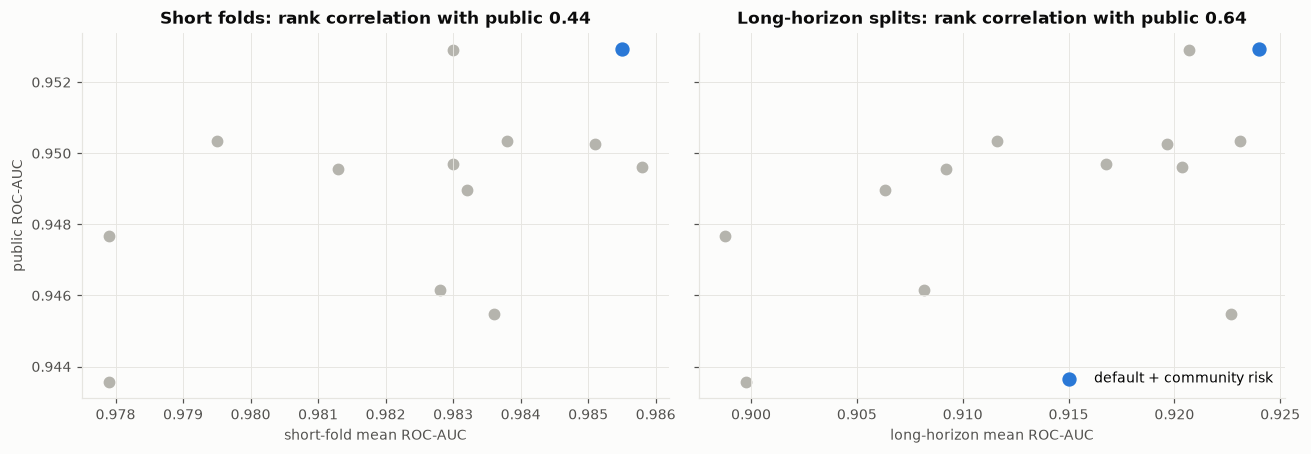

,rank correlation with public score
short folds (mean of 3),0.4410
long horizon (mean of 4 splits),0.6440
"long horizon, split 1 only",0.6220
"long horizon, split 2 only",0.4430
"long horizon, split 3 only",0.5940
"long horizon, split 4 only",0.1620


In [79]:
rho = lambda a, b: pd.Series(a).corr(pd.Series(b), method="spearman")
agree = pd.Series({
    "short folds (mean of 3)": rho(lh_table["short-fold mean"], lh_table["public"]),
    "long horizon (mean of 4 splits)": rho(lh_table["long-horizon mean"], lh_table["public"]),
    **{f"long horizon, split {i + 1} only": rho(lh_table.iloc[:, i], lh_table["public"]) for i in range(len(LH_SPLITS))},
}, name="rank correlation with public score").to_frame()
LH_ADOPTED = bool(agree.loc["long horizon (mean of 4 splits)"].iloc[0] > max(0.32, agree.loc["short folds (mean of 3)"].iloc[0])
                  and agree.loc["long horizon (mean of 4 splits)"].iloc[0] >= 0.5)
print("Long-horizon design adopted for later evaluation:", LH_ADOPTED)
BEST_RA = "Rank average: default + community risk"
print("Rank of the default + community risk rank average among the 13 on the long-horizon mean:",
      int(lh_table["long-horizon mean"].rank(ascending=False)[BEST_RA]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title in [(axes[0], "short-fold mean", "Short folds"), (axes[1], "long-horizon mean", "Long-horizon splits")]:
    is_final = lh_table.index == BEST_RA
    ax.scatter(lh_table.loc[~is_final, col], lh_table.loc[~is_final, "public"], color=UNKNOWN, s=45)
    ax.scatter(lh_table.loc[is_final, col], lh_table.loc[is_final, "public"], color=LICIT, s=70, label="default + community risk")
    ax.set_title(f"{title}: rank correlation with public {rho(lh_table[col], lh_table['public']):.2f}")
    ax.set_xlabel(f"{col} ROC-AUC")
axes[0].set_ylabel("public ROC-AUC"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
agree.round(3)

> **Conclusion.** The long-horizon mean predicts the leaderboard better than the short folds: rank correlation 0.64 against 0.44. Single splits agree less, at 0.16 to 0.62, so the average over all four is what carries the signal.
>
> Candidates in 4.4 and 4.7 to 4.7 are therefore judged mainly on the four-split long-horizon mean, with the short folds as a check. On this design, default LightGBM rank-averaged with the community risk score ranks first, and it also has the best public score, 0.95292, so it becomes the final model (4.9). Default LightGBM, 0.95291 publicly, is the second selection.

**Final check: the long-horizon-tuned model in the rank average.** The best long-horizon candidate from stage 1 (4.4) passed its rule against default LightGBM. Here it replaces default LightGBM inside the final rank average and is checked on both designs, then on the leaderboard.

In [80]:
# Only if the rule passed: the new main model inside the final rank average, and test files.
if LHT_PASS:
    lht_lh_preds = cached("lhtune418_best_lh_preds", lambda: {k: ordered_avg_p(best_p, Xtr, ytr, Xva) for k, (Xtr, ytr, Xva, _) in LH_DATA.items()})
    ra_f = {"Final model: default + tuned risk model": (default_ref_folds + fold_rank(p_risk_val)) / 2,
            "Long-horizon-tuned + tuned risk model": (lht_folds + fold_rank(p_risk_val)) / 2}
    ra_tab2 = compare(ra_f, "Final model: default + tuned risk model")[["mean ROC-AUC", "Δ vs ref", "95% CI low", "95% CI high"]]
    ra_l = {}
    for k in LH_DATA:
        Pk, yk = LH_RES[k]["preds"], LH_RES[k]["y"]
        ra_l[k] = {"Final model: default + tuned risk model": roc_auc_score(yk, Pk["Rank average: default + community risk"]),
                   "Long-horizon-tuned + tuned risk model": roc_auc_score(yk, (lht_lh_preds[k] + rank01(Pk["Louvain community risk score"])) / 2)}
    ra_l = pd.DataFrame(ra_l)
    ra_tab2 = ra_tab2.join(ra_l.add_prefix("long horizon "))
    ra_tab2["long-horizon mean"] = ra_l.mean(axis=1)
    p_lht_test = cached("test_lhtune418", lambda: make_lgb(best_p).fit(xdef(None), Y).predict_proba(xdef(None, "test"))[:, 1])
    p_final_test = (rankdata(p_default_test) + rankdata(p_risk_test)) / (2 * n_test)
    lht_files = {"submissions/lh_tuned_lgbm.csv": p_lht_test,
                 "submissions/lh_tuned_plus_louvain_risk.csv": (rankdata(p_lht_test) + rankdata(p_risk_test)) / (2 * n_test)}
    rows = {}
    for path, p in lht_files.items():
        pd.DataFrame({"index": test_df["index"].to_numpy(), "target": p}).to_csv(path, index=False)
        check_submission(path)
        rows[path] = {"rank corr. with final submission": pd.Series(p).corr(pd.Series(p_final_test), method="spearman"),
                      "rank corr. with default LightGBM": pd.Series(p).corr(pd.Series(p_default_test), method="spearman")}
    display(ra_tab2.round(4))
    out = pd.DataFrame(rows).T.round(4)
else:
    out = "The best trial did not meet the rule, so default LightGBM stays the main model and no file was written."
out

Loaded cached result: artifacts/lhtune418_best_lh_preds.pkl


Loaded cached result: artifacts/test_lhtune418.pkl


,mean ROC-AUC,Δ vs ref,95% CI low,95% CI high,long horizon 15->29,long horizon 17->31,long horizon 19->33,long horizon 21->35,long-horizon mean
model,,,,,,,,,
Final model: default + tuned risk model,0.9855,0.0000,0.0000,0.0000,0.9379,0.9284,0.9197,0.9100,0.9240
Long-horizon-tuned + tuned risk model,0.9860,0.0005,0.0002,0.0008,0.9257,0.9322,0.9212,0.9216,0.9252


,rank corr. with final submission,rank corr. with default LightGBM
submissions/lh_tuned_lgbm.csv,0.9595,0.9276
submissions/lh_tuned_plus_louvain_risk.csv,0.9800,0.9223


> **Conclusion.** Inside the final rank average, the long-horizon-tuned model raises the long-horizon mean from 0.9240 to 0.9252, improving 3 of the 4 splits (again losing the earliest), and the short folds by +0.0005 (95% interval +0.0002 to +0.0008). The rank average stays close to the final submission (rank correlation 0.980); the tuned model alone differs more (0.960).
>
> Both files are leaderboard probes against the final model's 0.95292. Under the rule fixed in advance, a probe replaces the final model only if it clearly beats it publicly; a tie keeps the final model, since the gains here are modest and partly flattered by the search.
>
> The rank average, `lh_tuned_plus_louvain_risk.csv`, scored **0.95097** publicly, 0.0020 *below* the final model's 0.95292, although both validation designs favoured it. Tuning lost publicly again: on the short folds in section 3, and now on the long-horizon splits. With four splits that overlap heavily, a 20-trial search still fits the validation periods rather than the test period. The final model is unchanged.

**Final submissions.** 

1. **Default LightGBM rank-averaged with the Louvain community risk model** (4.7): best on the long-horizon design (0.924).
2. **Default LightGBM + Isolation Forest feature** (4.8): second-best on the long-horizon design (0.923) and the candidate least correlated with the first selection.

In [81]:
FINAL_FILES = {"submissions/default_lgbm_plus_louvain_risk.csv": p_final_test,
               "submissions/default_lgbm_plus_isolation_forest.csv": p_iso_test}
os.makedirs("submissions", exist_ok=True)
rows = {}
for path, p in FINAL_FILES.items():
    pd.DataFrame({"index": test_df["index"].to_numpy(), "target": p}).to_csv(path, index=False)
    check_submission(path)
out = pd.DataFrame(rows).T
out["public ROC-AUC"] = pd.Series({"submissions/default_lgbm_plus_louvain_risk.csv": 0.95292, "submissions/default_lgbm_plus_isolation_forest.csv": 0.95034})
# How differently each candidate second selection ranks the test set from the first selection.
cands = {"Default LightGBM": p_default_test, "Default + Isolation Forest feature": p_iso_test,
         "Louvain community risk model": p_risk_test}
display(pd.Series({n: pd.Series(p).corr(pd.Series(p_final_test), method="spearman") for n, p in cands.items()},
                  name="rank corr. with the first selection").to_frame().round(3))
out

,rank corr. with the first selection
Default LightGBM,0.9710
Default + Isolation Forest feature,0.9420
Louvain community risk model,0.9720


,public ROC-AUC
submissions/default_lgbm_plus_louvain_risk.csv,0.9529
submissions/default_lgbm_plus_isolation_forest.csv,0.9503


**Summary.**

- **Stage 1:** default LightGBM generalises furthest (long-horizon 0.921 vs 0.912 for tuned; public 0.95291 vs 0.95034). Other families, ensembles, more features and long-horizon tuning did not help publicly.
- **Stage 2:** adversarial weighting (0.94767), dropping drifting features (0.94547) and within-step ranking (0.94358) all fitted the past more closely and lost.
- **Stage 3:** only the Louvain risk score, as a separate tuned model rank-averaged with default LightGBM, helped: +0.0025 on the short folds and the best long-horizon mean, 0.924 (public 0.95292). Other methods, default settings for the risk model and collective classification did not.
- **Stage 4:** illicit transactions are less unusual than licit ones; the Isolation Forest score helps only as a feature, far ahead (long-horizon 0.923, public 0.95034).
- **Stage 5:** the long-horizon design tracks the leaderboard best (0.64 against 0.44) and decides close calls.

**Final submissions:** default LightGBM + Louvain risk model (0.95292), and default LightGBM + Isolation Forest feature (0.95034), the strongest candidate that ranks the test set differently.